In [150]:
# ═══════════════════════════════════════════
# ALL IMPORTS — Run this first every session
# ═══════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches   # ← add this
import matplotlib
import seaborn as sns
import scipy
import sklearn
import itertools
import time
import warnings
warnings.filterwarnings('ignore')

print("✅ All core libraries loaded!")

✅ All core libraries loaded!


In [152]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib
matplotlib.rcParams['figure.dpi'] = 300
matplotlib.rcParams['savefig.dpi'] = 300
matplotlib.rcParams['font.size'] = 11
matplotlib.rcParams['axes.titlesize'] = 13
matplotlib.rcParams['axes.labelsize'] = 12

print("Publication quality settings applied!")
print("Now re-run each figure cell and save with:")
print("plt.savefig('figN_name.png', dpi=300, bbox_inches='tight')")

Publication quality settings applied!
Now re-run each figure cell and save with:
plt.savefig('figN_name.png', dpi=300, bbox_inches='tight')


In [153]:
import sys

# Core biology packages
!{sys.executable} -m pip install pydeseq2 --quiet
!{sys.executable} -m pip install combat-seq --quiet

# Check installations
print("Checking installations...")
try:
    import pydeseq2
    print("✅ pydeseq2 installed")
except:
    print("❌ pydeseq2 failed")

try:
    print("✅ combat-seq installed")
except:
    print("❌ combat-seq failed")

print("\nDone! Ready to run Stage 1.")

Checking installations...
✅ pydeseq2 installed
✅ combat-seq installed

Done! Ready to run Stage 1.


ERROR: Could not find a version that satisfies the requirement combat-seq (from versions: none)
ERROR: No matching distribution found for combat-seq


In [156]:
!{sys.executable} -m pip install gseapy --quiet
print("✅ gseapy installed")

✅ gseapy installed


In [158]:
import sys

packages = [
    "openpyxl",          # reading Excel files
    "pydeseq2",          # differential expression
    "gseapy",            # pathway enrichment
    "seaborn",           # plotting
    "statsmodels",       # statistics
    "adjustText",        # plot label adjustment
]

for pkg in packages:
    print(f"Installing {pkg}...")
    !{sys.executable} -m pip install {pkg} --quiet

print("\n✅ All packages installed!")
print("Now restart kernel (Kernel → Restart) and run from top.")

Installing openpyxl...
Installing pydeseq2...
Installing gseapy...
Installing seaborn...
Installing statsmodels...
Installing adjustText...

✅ All packages installed!
Now restart kernel (Kernel → Restart) and run from top.


In [160]:
import sys
!{sys.executable} -m pip install combat --quiet
print("✅ combat installed!")

✅ combat installed!


# STAGE 1 - Step 1 : Load & Separate the Data

In [163]:
expr_raw = pd.read_excel('GSE221911_Illumina_raw_read_count_177_pt.xlsx', header=None)
expr_raw.head()

,0,1,2,3,4,5,6,7,8,9,...,169,170,171,172,173,174,175,176,177,178
0,NaN,Subject ID,IN390,IN381,IN415,IN417,IN434,IN453,IN454,IN490,...,IN463,IN465,IN468,IN469,IN474,IN478,IN480,IN483,IN492,IN621
1,Gene Name,length of exons,390,381,415,417,434,453,454,490,...,463,465,468,469,474,478,480,483,492,621
2,A1BG,3382,12,10,6,14,3,7,7,12,...,12,14,6,18,12,6,6,9,10,5
3,A1BG-AS1,2130,42,28,20,32,24,17,22,17,...,23,31,26,24,16,24,4,25,33,12
4,A1CF,9529,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [165]:
# Extract sample IDs from first row
sample_ids = expr_raw.iloc[0, 2:].values

# Extract gene names from column 0 (starting row 2)
gene_names = expr_raw.iloc[2:, 0].values

# Extract expression matrix (remove first 2 rows and first 2 columns)
expr = expr_raw.iloc[2:, 2:]

# Assign proper column and index names
expr.columns = sample_ids
expr.index = gene_names

expr.head()

,IN390,IN381,IN415,IN417,IN434,IN453,IN454,IN490,IN379,IN318,...,IN463,IN465,IN468,IN469,IN474,IN478,IN480,IN483,IN492,IN621
A1BG,12,10,6,14,3,7,7,12,7,1,...,12,14,6,18,12,6,6,9,10,5
A1BG-AS1,42,28,20,32,24,17,22,17,26,8,...,23,31,26,24,16,24,4,25,33,12
A1CF,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A2M,2,4,4,3,5,3,6,11,4,0,...,5,2,25,6,20,2,3,14,2,4
A2M-AS1,182,107,269,140,110,120,414,282,154,70,...,112,218,568,180,154,178,58,74,345,83


In [167]:
# We require row = samples (PatientID) and column = features (genes)
expr = expr.T
expr.head()

,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2MP1,A3GALT2,A4GALT,A4GNT,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
IN390,12,42,0,2,182,0,0,4,1,0,...,57,9,46,67,447,0,476,0,1528,358
IN381,10,28,0,4,107,0,0,1,0,0,...,40,6,43,59,501,1,404,0,1525,266
IN415,6,20,0,4,269,0,1,2,0,0,...,83,17,88,81,374,3,421,0,1214,402
IN417,14,32,0,3,140,0,0,3,0,0,...,76,10,72,81,732,1,647,2,2014,339
IN434,3,24,0,5,110,0,0,1,0,0,...,64,13,54,106,456,0,390,0,1220,410


In [168]:
meta = pd.read_excel('clinical_metadata_file.xlsx')
meta.head()

,Column Number,TruCAD #,Sex,Age,BMI,SBP,DBP,HR,EF %,Dyslipidemia,Hypertension,Diabetes mellitus,Family history of CAD,Smoking,ASA,CAD20%,CAD,%Stenosis,RNAseq
0,1,390,F,65.8,34.4,115,66,73,60,Yes,Yes,No,Yes,Former,81,Y,CAD,100,TR1
1,2,381,M,53.8,43.1,132,75,76,35,Yes,Yes,No,No,Former,81,Y,CAD,100,TR1
2,3,415,M,47.3,31.4,98,63,67,77,No,No,No,Yes,Former,81,Y,CAD,100,TR2
3,4,417,M,65.9,25.1,140,83,83,50,No,Yes,No,Yes,Current,81,Y,CAD,100,TR2
4,5,434,M,50.0,46.0,178,96,68,50,Yes,Yes,No,No,Never,81,Y,CAD,100,TR2


In [169]:
meta['SampleID'] = 'IN' + meta['TruCAD #'].astype(str)
meta = meta.set_index('SampleID')
meta.head()

,Column Number,TruCAD #,Sex,Age,BMI,SBP,DBP,HR,EF %,Dyslipidemia,Hypertension,Diabetes mellitus,Family history of CAD,Smoking,ASA,CAD20%,CAD,%Stenosis,RNAseq
SampleID,,,,,,,,,,,,,,,,,,,
IN390,1,390,F,65.8,34.4,115,66,73,60,Yes,Yes,No,Yes,Former,81,Y,CAD,100,TR1
IN381,2,381,M,53.8,43.1,132,75,76,35,Yes,Yes,No,No,Former,81,Y,CAD,100,TR1
IN415,3,415,M,47.3,31.4,98,63,67,77,No,No,No,Yes,Former,81,Y,CAD,100,TR2
IN417,4,417,M,65.9,25.1,140,83,83,50,No,Yes,No,Yes,Current,81,Y,CAD,100,TR2
IN434,5,434,M,50.0,46.0,178,96,68,50,Yes,Yes,No,No,Never,81,Y,CAD,100,TR2


In [170]:
# ── Separate into X, y, clinical ────────────────────────────────────
X        = expr.copy()                        # 177 × 28278 gene counts
y        = meta["CAD"].copy()             # 177 labels (LOW/MID/CAD)
clinical = meta.drop(columns=["CAD"])     # 177 × 18 clinical variables

In [171]:
# ── Confirm everything looks right ──────────────────────────────────
print("X shape (samples × genes):", X.shape)
print("y shape (labels)          :", y.shape)
print("clinical shape            :", clinical.shape)
print("\nClass distribution:")
print(y.value_counts())
print("\nClinical columns available:")
print(clinical.columns.tolist())

X shape (samples × genes): (177, 28278)
y shape (labels)          : (177,)
clinical shape            : (177, 18)

Class distribution:
CAD
LOW    79
CAD    55
MID    43
Name: count, dtype: int64

Clinical columns available:
['Column Number', 'TruCAD #', 'Sex', 'Age', 'BMI', 'SBP', 'DBP', 'HR', 'EF %', 'Dyslipidemia', 'Hypertension', 'Diabetes mellitus', 'Family history of CAD', 'Smoking ', 'ASA', 'CAD20%', '%Stenosis', 'RNAseq']


In [172]:
# Fix trailing space in Smoking column
clinical.columns = clinical.columns.str.strip()

# Confirm it's fixed
print(clinical.columns.tolist())

['Column Number', 'TruCAD #', 'Sex', 'Age', 'BMI', 'SBP', 'DBP', 'HR', 'EF %', 'Dyslipidemia', 'Hypertension', 'Diabetes mellitus', 'Family history of CAD', 'Smoking', 'ASA', 'CAD20%', '%Stenosis', 'RNAseq']


# STAGE 1 — Step 2: Filter Lowly Expressed Genes

In [180]:
# Define thresholds
min_counts  = 10   # gene must have at least 10 raw counts
min_samples = int(0.10 * X.shape[0])  # in at least 10% of samples (~18)

# For each gene, count how many samples meet the minimum count threshold
samples_passing = (X >= min_counts).sum(axis=0)

# Keep only genes that pass in enough samples
genes_to_keep = samples_passing[samples_passing >= min_samples].index
X_filtered    = X[genes_to_keep]

# ── Report what happened ─────────────────────────────────────────────
print(f"Genes before filtering : {X.shape[1]}")
print(f"Genes after filtering  : {X_filtered.shape[1]}")
print(f"Genes removed          : {X.shape[1] - X_filtered.shape[1]}")
print(f"Samples unchanged      : {X_filtered.shape[0]}")

Genes before filtering : 28278
Genes after filtering  : 13230
Genes removed          : 15048
Samples unchanged      : 177


# STAGE 1 — Step 3: Normalization (log-CPM)

In [182]:
# WHAT: Convert X_filtered to numeric (float) type
# WHY:  When data is loaded from CSV/Excel, some columns can get stored 
#       as 'object' dtype instead of numbers, this forces them to be 
#       proper numeric values

X_filtered = X_filtered.apply(pd.to_numeric, errors='coerce')

# Check dtypes are now numeric
print("Data types after conversion:")
print(X_filtered.dtypes.value_counts())

# Check if any NaN values were introduced
print(f"\nAny NaN values: {X_filtered.isna().sum().sum()}")
print(f"Shape unchanged: {X_filtered.shape}")

Data types after conversion:
int64    13230
Name: count, dtype: int64

Any NaN values: 0
Shape unchanged: (177, 13230)


In [183]:
# WHAT: Calculate CPM for each sample
# WHY:  Dividing by total counts per sample (library size) and 
#       multiplying by 1million makes all samples comparable

# Step 3a: Calculate library size (total counts) for each sample
library_sizes = X_filtered.sum(axis=1)  
# axis=1 means sum across all genes for each sample (row-wise)

print("Library sizes (first 5 samples):")
print(library_sizes.head())
print(f"\nMin library size: {library_sizes.min():,.0f}")
print(f"Max library size: {library_sizes.max():,.0f}")
print(f"Mean library size: {library_sizes.mean():,.0f}")

Library sizes (first 5 samples):
IN390    4831075
IN381    5386757
IN415    5046529
IN417    6845818
IN434    6277530
dtype: int64

Min library size: 1,585,192
Max library size: 11,933,457
Mean library size: 6,099,737


In [184]:
# ── Step 3b: Calculate CPM then apply log transformation ────────────

# WHAT: Divide each gene's count by the sample's library size,
#       multiply by 1 million to get CPM
# WHY:  This puts all samples on the same scale regardless of 
#       how deeply they were sequenced

# Calculate CPM
# We divide each row (sample) by its library size
# .divide() with axis=0 means divide each row by its corresponding value
CPM = X_filtered.divide(library_sizes, axis=0) * 1e6

# WHAT: Apply log2(CPM + 1) transformation
# WHY:  - Compresses the huge range of values (0 to millions → 0 to ~20)
#       - Makes distribution more normal (required for WGCNA later)
#       - +1 prevents log(0) which is mathematically undefined
log_CPM = np.log2(CPM + 1)

# ── Confirm the transformation worked ───────────────────────────────
print("Before normalization (raw counts):")
print(f"  Min value : {X_filtered.values.min()}")
print(f"  Max value : {X_filtered.values.max()}")
print(f"  Mean value: {X_filtered.values.mean():.2f}")

print("\nAfter log-CPM normalization:")
print(f"  Min value : {log_CPM.values.min():.2f}")
print(f"  Max value : {log_CPM.values.max():.2f}")
print(f"  Mean value: {log_CPM.values.mean():.2f}")

print("\nlog_CPM shape:", log_CPM.shape)
print("\nlog_CPM preview (first 3 samples, first 5 genes):")
print(log_CPM.iloc[:3, :5].round(3))

Before normalization (raw counts):
  Min value : 0
  Max value : 1809739
  Mean value: 461.05

After log-CPM normalization:
  Min value : 0.00
  Max value : 17.90
  Mean value: 4.25

log_CPM shape: (177, 13230)

log_CPM preview (first 3 samples, first 5 genes):
        A1BG  A1BG-AS1    A2M  A2M-AS1  A3GALT2
IN390  1.801     3.277  0.500    5.273    0.870
IN381  1.514     2.632  0.801    4.383    0.246
IN415  1.130     2.311  0.842    5.763    0.482


# STAGE 1 — Step 4 : Batch Correction Using ComBat

In [186]:
# WHAT: Check how samples are distributed across batches
# WHY:  We need to know if batches are balanced across CAD classes
#       If one batch has mostly CAD and another has mostly LOW,
#       batch correction becomes even more critical

batch = clinical["RNAseq"]

print("Batch distribution:")
print(batch.value_counts())

print("\nBatch vs CAD class cross-tabulation:")
print(pd.crosstab(batch, y))

Batch distribution:
RNAseq
TR2    95
TR1    82
Name: count, dtype: int64

Batch vs CAD class cross-tabulation:
CAD     CAD  LOW  MID
RNAseq               
TR1      25   38   19
TR2      30   41   24


In [187]:
# ── Step 4: Batch Correction Using ComBat ───────────────────────────
from combat.pycombat import pycombat

# WHAT: Prepare data for ComBat
# WHY:  pycombat expects genes as ROWS and samples as COLUMNS
#       (opposite of how we've been working)
#       so we transpose log_CPM before passing it in

data_for_combat = log_CPM.T  
# Shape becomes (13230 genes × 177 samples)

print("Data shape for ComBat (genes × samples):", data_for_combat.shape)

# WHAT: Extract batch labels
# WHY:  ComBat needs to know which batch each sample belongs to
#       so it can identify and remove batch-specific variation
batch_labels = clinical["RNAseq"].values
print("\nBatch labels (first 10):", batch_labels[:10])

# WHAT: Apply ComBat batch correction
# WHY:  ComBat models the batch effect statistically and removes it
#       while preserving biological variation (CAD vs LOW vs MID)
print("\nRunning ComBat batch correction...")
data_corrected = pycombat(data_for_combat, batch_labels)

# WHAT: Transpose back to original orientation
# WHY:  We want samples as rows again (177 × 13230)
#       to be consistent with rest of our pipeline
log_CPM_corrected = data_corrected.T

# ── Confirm everything looks right ──────────────────────────────────
print("\nBatch correction complete!")
print(f"Shape before correction: {log_CPM.shape}")
print(f"Shape after correction : {log_CPM_corrected.shape}")
print(f"\nValue range before: {log_CPM.values.min():.2f} to {log_CPM.values.max():.2f}")
print(f"Value range after : {log_CPM_corrected.values.min():.2f} to {log_CPM_corrected.values.max():.2f}")
print("\nPreview of corrected data (first 3 samples, first 5 genes):")
print(log_CPM_corrected.iloc[:3, :5].round(3))

Data shape for ComBat (genes × samples): (13230, 177)

Batch labels (first 10): ['TR1' 'TR1' 'TR2' 'TR2' 'TR2' 'TR2' 'TR2' 'TR2' 'TR1' 'TR1']

Running ComBat batch correction...
Found 2 batches.
Adjusting for 0 covariate(s) or covariate level(s).
Standardizing Data across genes.
Fitting L/S model and finding priors.
Finding parametric adjustments.
Adjusting the Data

Batch correction complete!
Shape before correction: (177, 13230)
Shape after correction : (177, 13230)

Value range before: 0.00 to 17.90
Value range after : -0.34 to 17.91

Preview of corrected data (first 3 samples, first 5 genes):
        A1BG  A1BG-AS1    A2M  A2M-AS1  A3GALT2
IN390  1.773     3.230  0.702    5.317    0.859
IN381  1.491     2.589  1.002    4.456    0.176
IN415  1.146     2.345  0.721    5.723    0.512


In [188]:
# From this point forward these are your three key variables
# Save them clearly so you never confuse them

X_clean = log_CPM_corrected    # 177 × 13230 — normalized, batch corrected
y        = y                   # 177 labels  — LOW / MID / CAD
clinical = clinical            # 177 × 18    — clinical variables

print("Final clean dataset:")
print(f"  X_clean : {X_clean.shape}")
print(f"  y       : {y.shape} | Classes: {y.unique()}")
print(f"  clinical: {clinical.shape}")

Final clean dataset:
  X_clean : (177, 13230)
  y       : (177,) | Classes: ['CAD' 'MID' 'LOW']
  clinical: (177, 18)


# STAGE 2 — Step 1: PCA Plot

PC1 explains: 36.5% of variance
PC2 explains: 11.3% of variance
Total       : 47.7% of variance captured


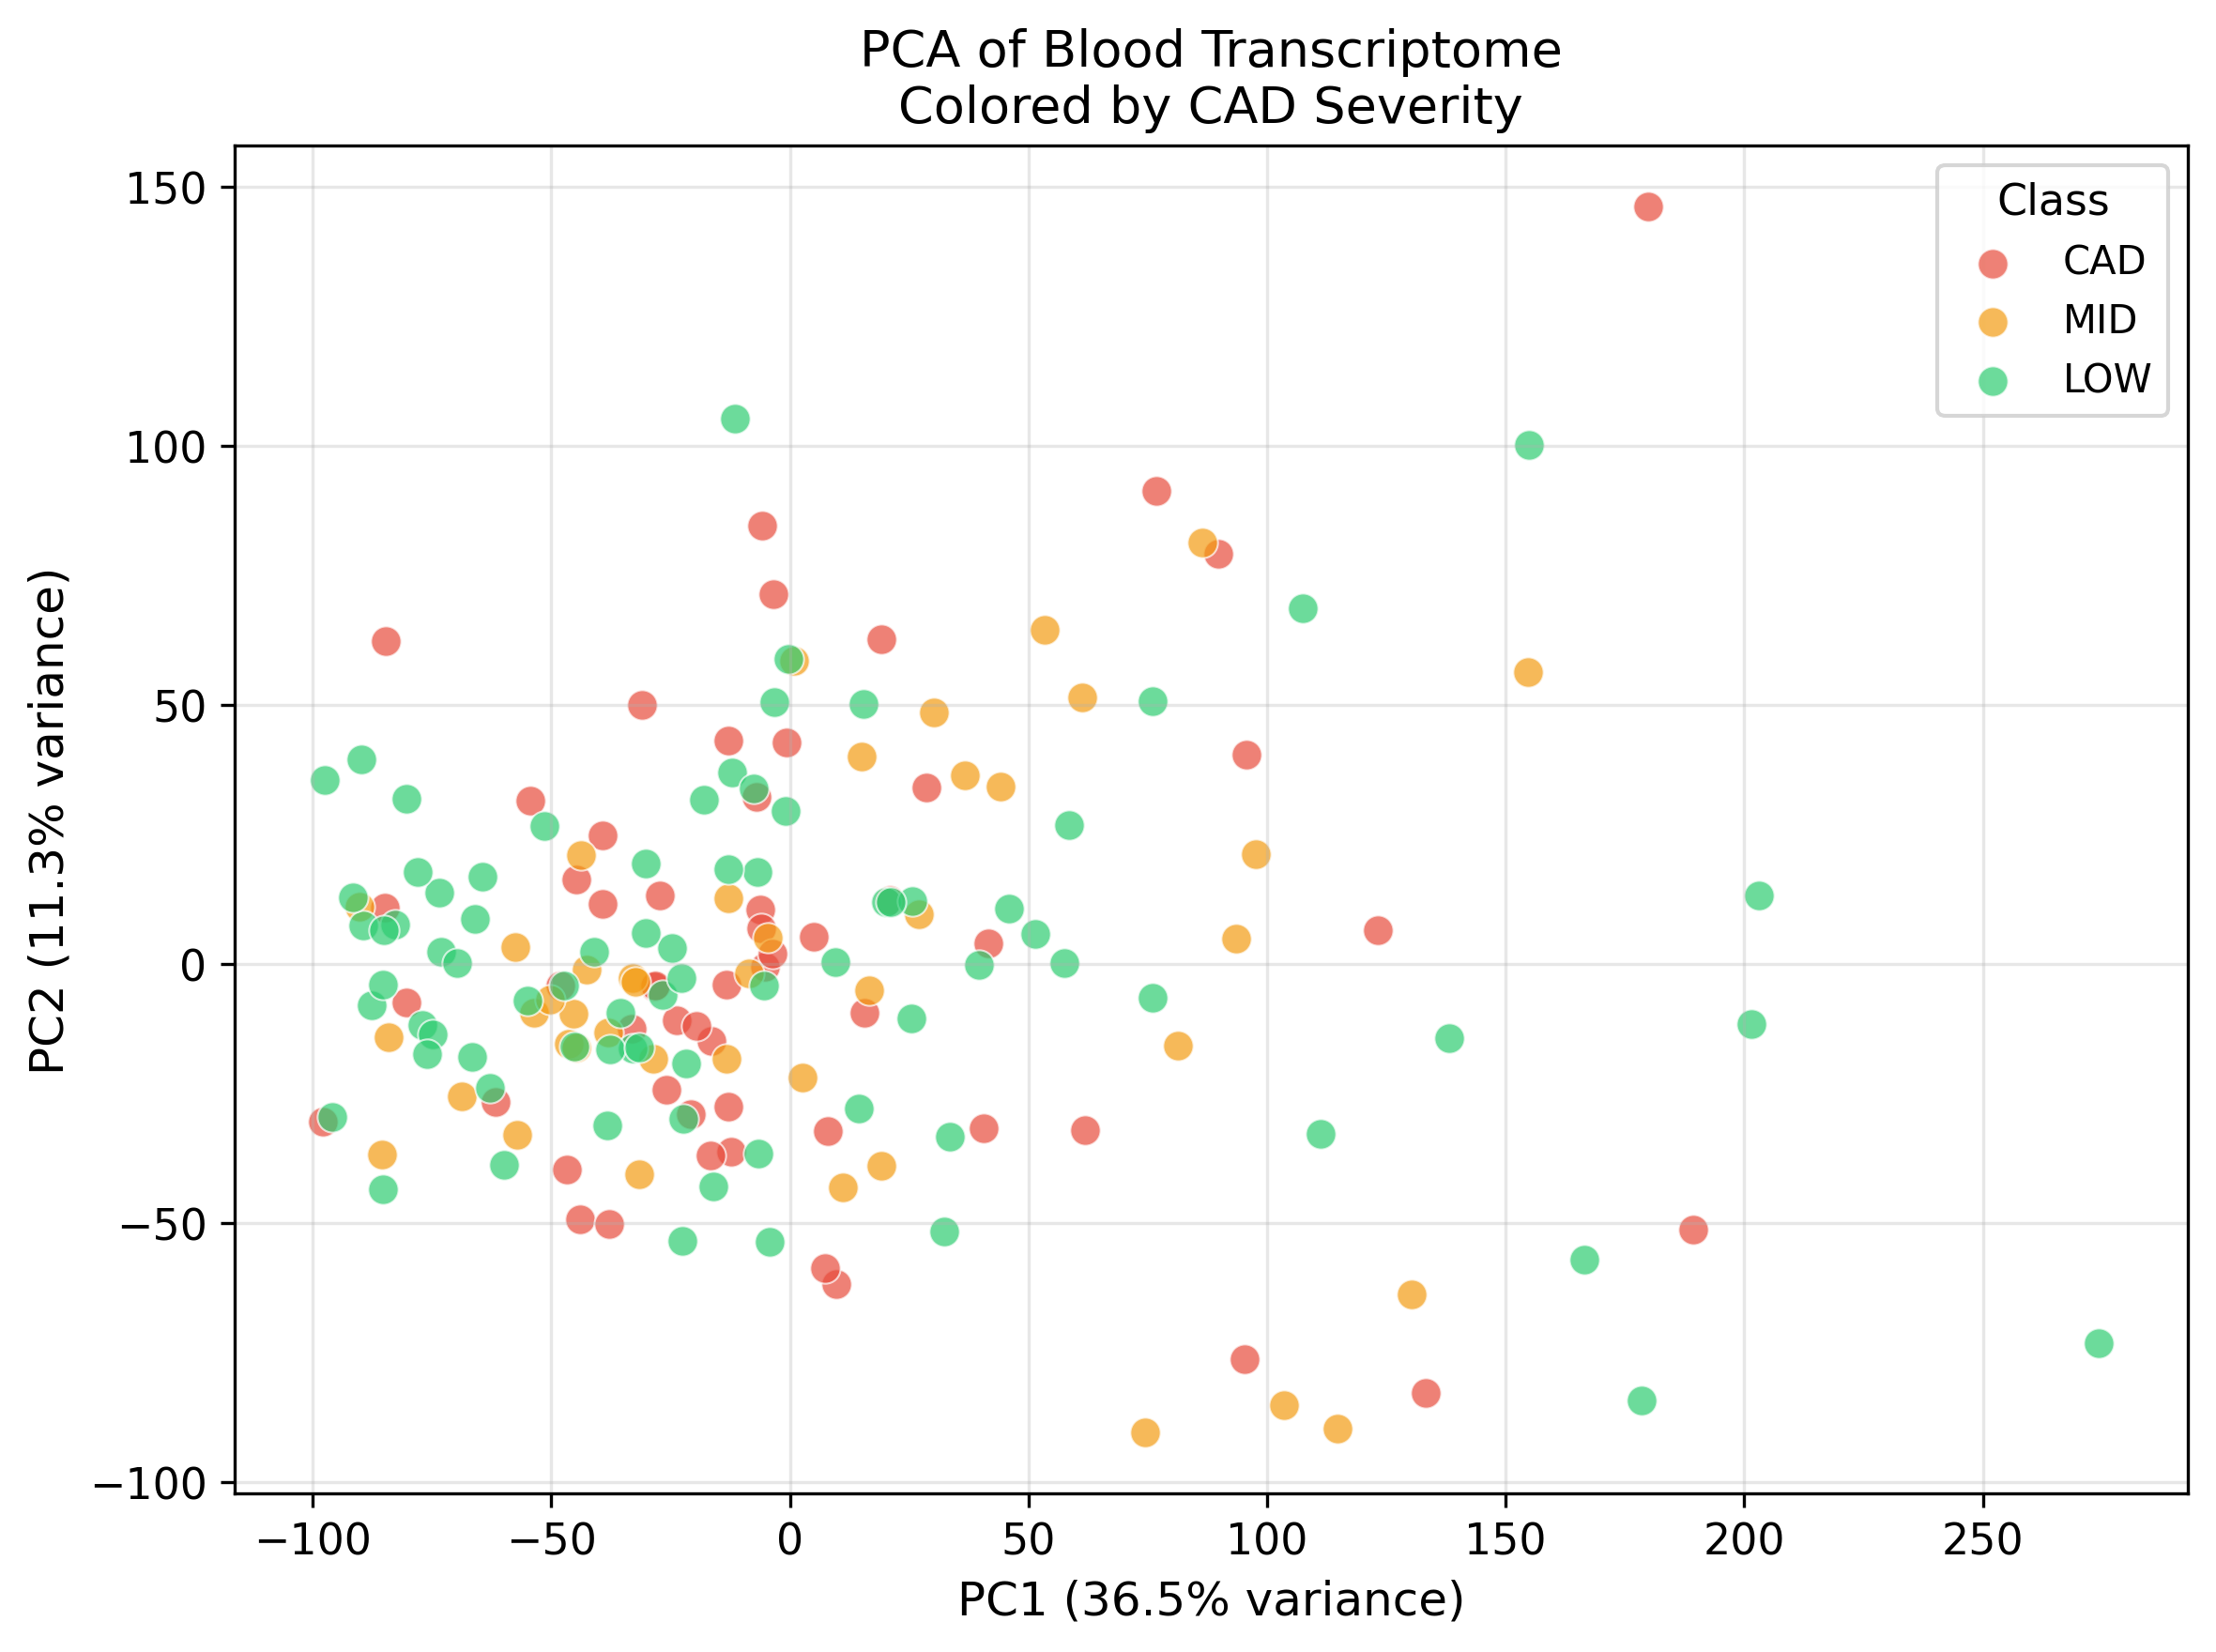


PCA plot saved as PCA_plot.png


In [190]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ── Prepare data for PCA ─────────────────────────────────────────────

# WHAT: Standardize the data before PCA
# WHY:  PCA is sensitive to scale — genes with higher expression values
#       would dominate the components if we don't standardize first
#       StandardScaler makes every gene have mean=0 and std=1
scaler     = StandardScaler()
X_scaled   = scaler.fit_transform(X_clean)

# ── Run PCA ──────────────────────────────────────────────────────────

# WHAT: Reduce 13,230 dimensions down to 2 for visualization
# WHY:  We can't visualize 13,230 dimensions but we can visualize 2
#       n_components=2 gives us the two most informative dimensions
pca        = PCA(n_components=2)
X_pca      = pca.fit_transform(X_scaled)

# How much of the total variation is captured by these 2 components
var_explained = pca.explained_variance_ratio_ * 100
print(f"PC1 explains: {var_explained[0]:.1f}% of variance")
print(f"PC2 explains: {var_explained[1]:.1f}% of variance")
print(f"Total       : {sum(var_explained):.1f}% of variance captured")

# ── Plot PCA ─────────────────────────────────────────────────────────

# WHAT: Color each patient dot by their CAD class
# WHY:  This lets us visually see if classes separate in PCA space
colors     = {"CAD": "#e74c3c", "MID": "#f39c12", "LOW": "#2ecc71"}

fig, ax    = plt.subplots(figsize=(8, 6))

for label in ["CAD", "MID", "LOW"]:
    # Get indices of samples belonging to this class
    idx = y == label
    ax.scatter(
        X_pca[idx, 0],   # PC1 values for this class
        X_pca[idx, 1],   # PC2 values for this class
        c      = colors[label],
        label  = label,
        alpha  = 0.7,    # slight transparency so overlapping points visible
        s      = 60,     # dot size
        edgecolors = "white",
        linewidths = 0.5
    )

ax.set_xlabel(f"PC1 ({var_explained[0]:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({var_explained[1]:.1f}% variance)", fontsize=12)
ax.set_title("PCA of Blood Transcriptome\nColored by CAD Severity", fontsize=13)
ax.legend(title="Class", fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("PCA_plot.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nPCA plot saved as PCA_plot.png")

In [199]:
# WHAT: Identify outlier samples using PC1 threshold
# WHY:  Samples far from the main cluster in PCA space are likely
#       technical or biological outliers that will hurt our analysis

# Create a dataframe of PCA coordinates
pca_df = pd.DataFrame(
    X_pca, 
    columns=["PC1", "PC2"], 
    index=X_clean.index
)
pca_df["CAD"] = y.values

# WHAT: Flag samples beyond 3 standard deviations from mean on PC1 or PC2
# WHY:  3 SD is a standard statistical threshold for outlier detection
mean_pc1 = pca_df["PC1"].mean()
std_pc1  = pca_df["PC1"].std()
mean_pc2 = pca_df["PC2"].mean()
std_pc2  = pca_df["PC2"].std()

outliers = pca_df[
    (pca_df["PC1"] < mean_pc1 - 3*std_pc1) |
    (pca_df["PC1"] > mean_pc1 + 3*std_pc1) |
    (pca_df["PC2"] < mean_pc2 - 3*std_pc2) |
    (pca_df["PC2"] > mean_pc2 + 3*std_pc2)
]

print(f"Outlier samples detected: {len(outliers)}")
print("\nOutlier sample details:")
print(outliers[["PC1", "PC2", "CAD"]])

Outlier samples detected: 2

Outlier sample details:
              PC1         PC2  CAD
IN404  179.872983  146.053640  CAD
IN328  274.351049  -73.125769  LOW


In [201]:
# WHAT: Remove the two outlier samples from all three datasets
# WHY:  Keeping them would distort our network analysis and 
#       potentially mislead our ML models
#       2 samples out of 177 is only 1.1% — negligible data loss

outlier_ids = outliers.index.tolist()
print(f"Removing samples: {outlier_ids}")

# Remove from all three datasets simultaneously
X_clean  = X_clean.drop(index=outlier_ids)
y        = y.drop(index=outlier_ids)
clinical = clinical.drop(index=outlier_ids)

# ── Confirm removal ──────────────────────────────────────────────────
print(f"\nSamples before removal: 177")
print(f"Samples after removal : {X_clean.shape[0]}")
print(f"\nUpdated class distribution:")
print(y.value_counts())
print(f"\nX_clean shape : {X_clean.shape}")
print(f"y shape       : {y.shape}")
print(f"clinical shape: {clinical.shape}")

Removing samples: ['IN404', 'IN328']

Samples before removal: 177
Samples after removal : 175

Updated class distribution:
CAD
LOW    78
CAD    54
MID    43
Name: count, dtype: int64

X_clean shape : (175, 13230)
y shape       : (175,)
clinical shape: (175, 18)


PC1 explains: 34.9% of variance
PC2 explains: 10.9% of variance
Total       : 45.8% of variance captured


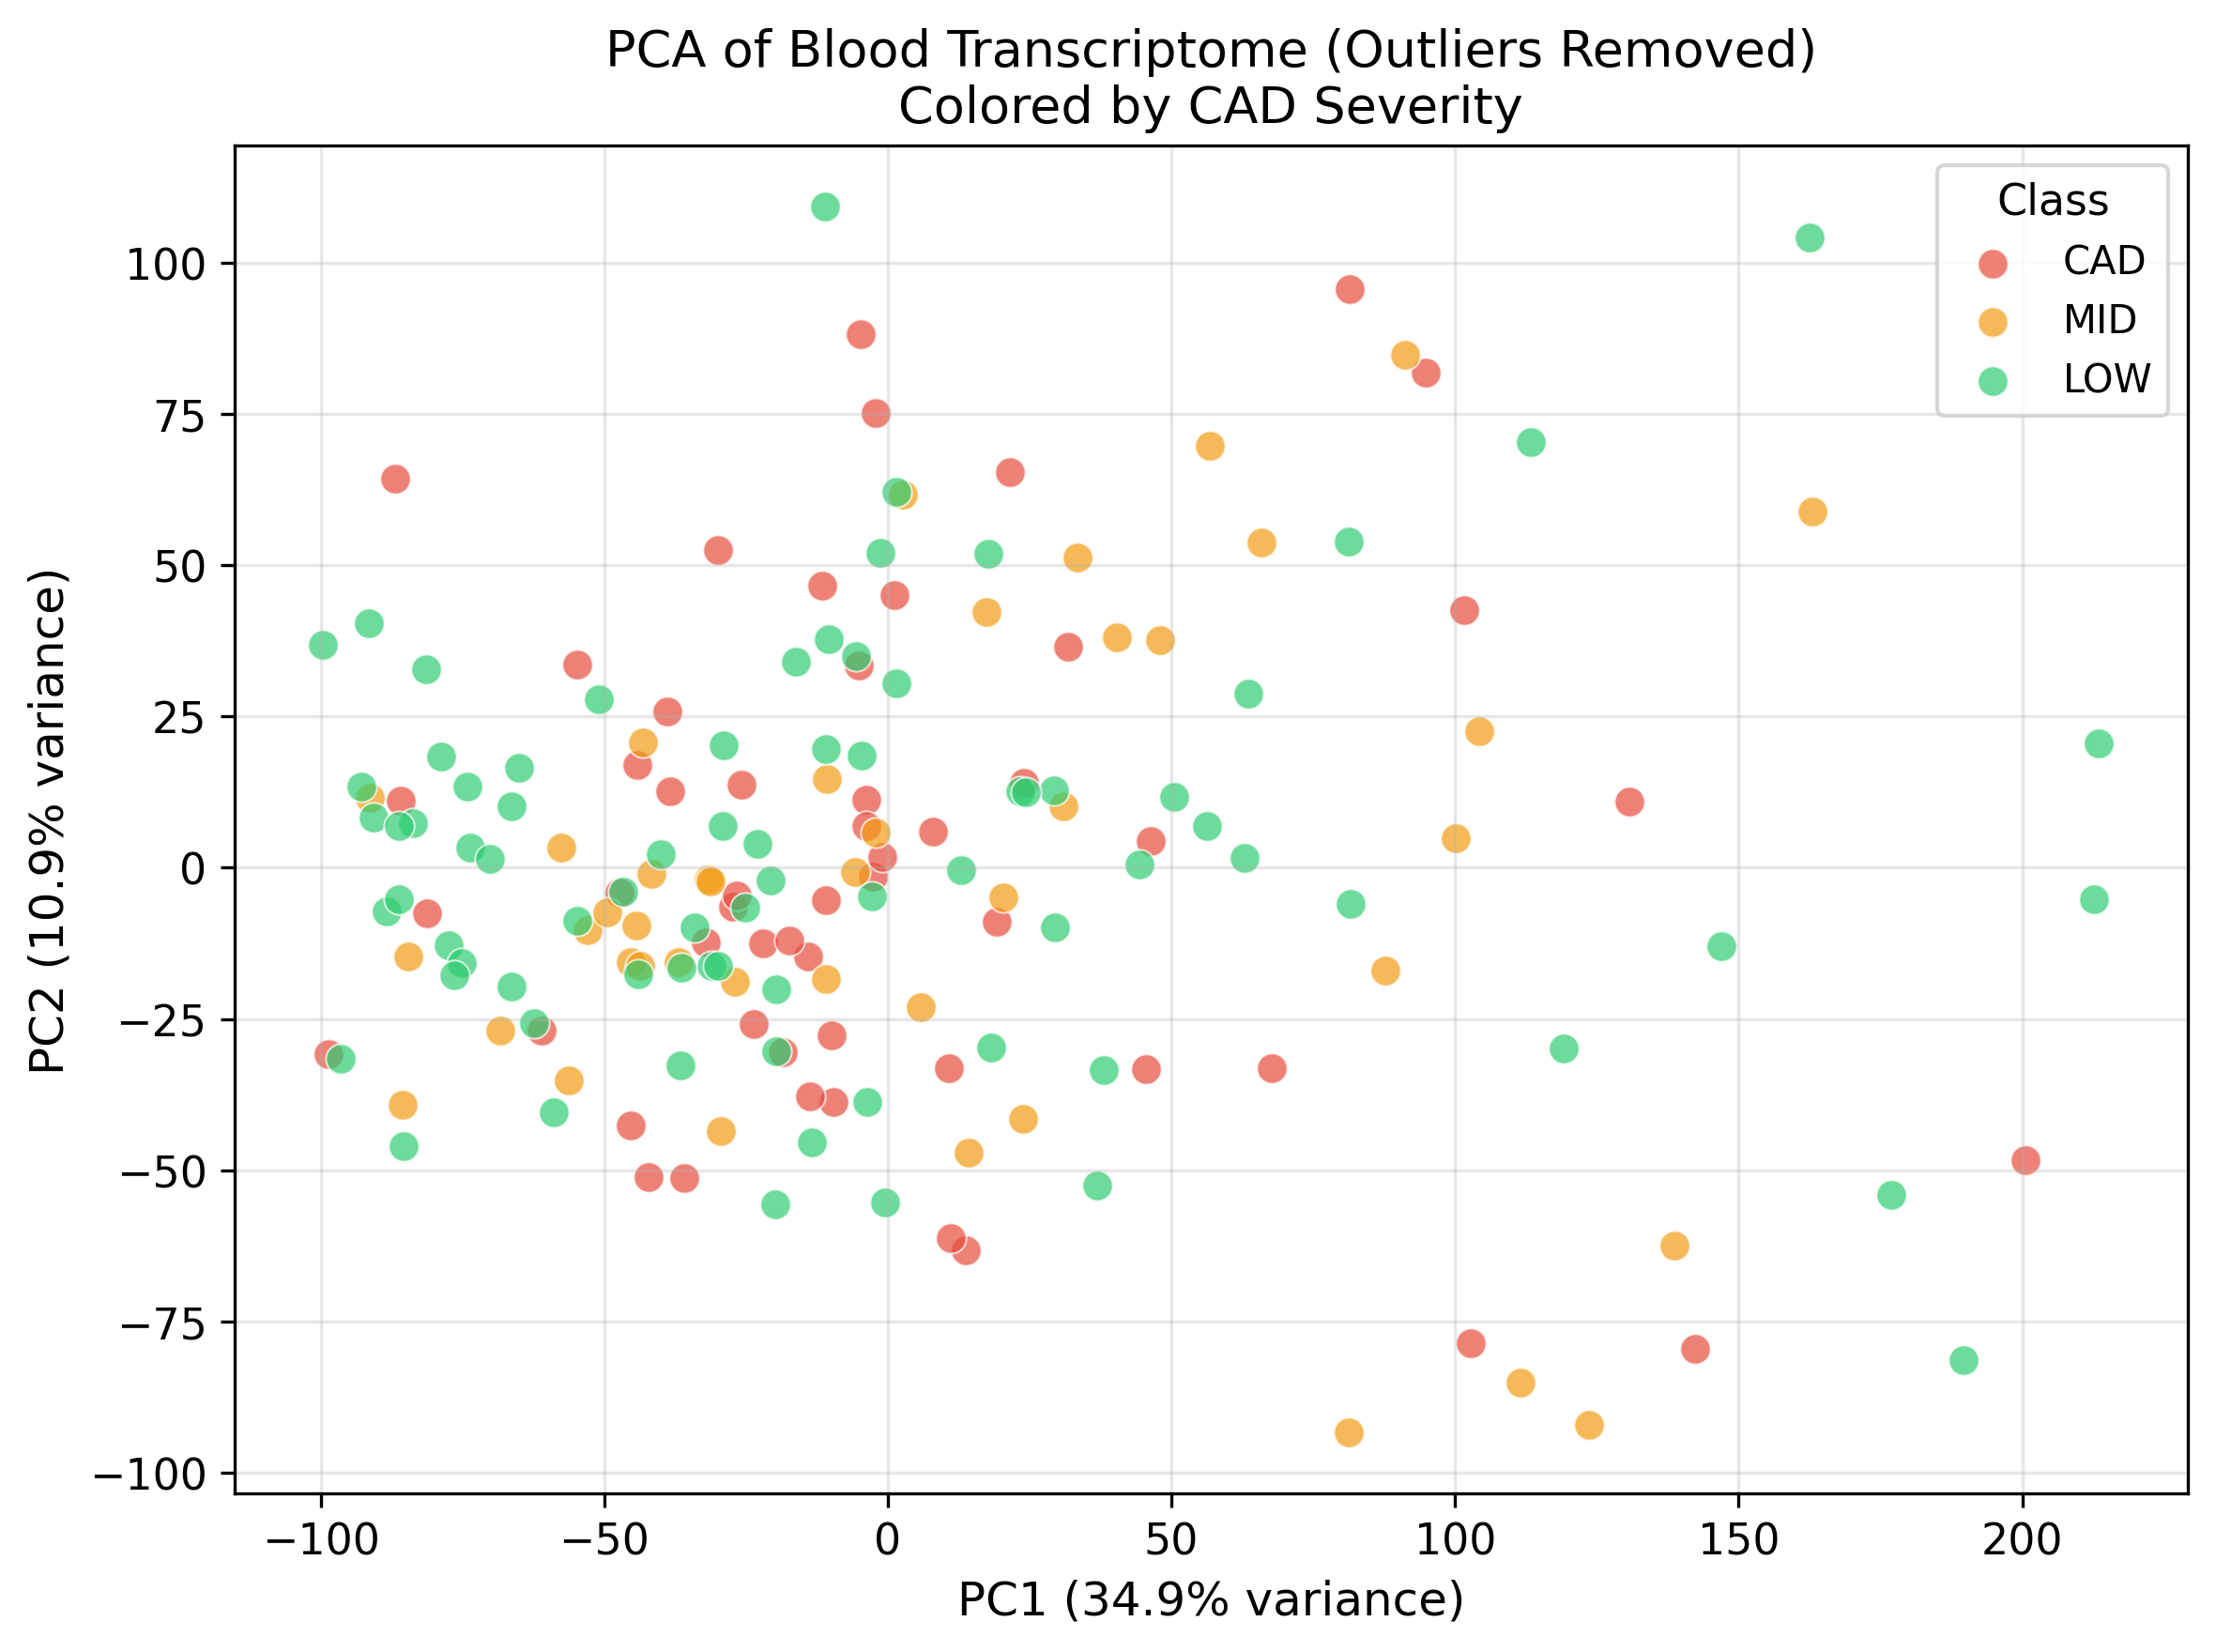


Clean PCA plot saved as PCA_plot_clean.png


In [202]:
# WHAT: Re-run PCA on cleaned data without outliers
# WHY:  To visually confirm the outliers are gone and the main
#       cluster looks cleaner and more interpretable

scaler_clean = StandardScaler()
X_scaled_clean = scaler_clean.fit_transform(X_clean)

pca_clean = PCA(n_components=2)
X_pca_clean = pca_clean.fit_transform(X_scaled_clean)

var_explained_clean = pca_clean.explained_variance_ratio_ * 100
print(f"PC1 explains: {var_explained_clean[0]:.1f}% of variance")
print(f"PC2 explains: {var_explained_clean[1]:.1f}% of variance")
print(f"Total       : {sum(var_explained_clean):.1f}% of variance captured")

# Plot
colors = {"CAD": "#e74c3c", "MID": "#f39c12", "LOW": "#2ecc71"}

fig, ax = plt.subplots(figsize=(8, 6))

for label in ["CAD", "MID", "LOW"]:
    idx = y == label
    ax.scatter(
        X_pca_clean[idx, 0],
        X_pca_clean[idx, 1],
        c          = colors[label],
        label      = label,
        alpha      = 0.7,
        s          = 60,
        edgecolors = "white",
        linewidths = 0.5
    )

ax.set_xlabel(f"PC1 ({var_explained_clean[0]:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({var_explained_clean[1]:.1f}% variance)", fontsize=12)
ax.set_title("PCA of Blood Transcriptome (Outliers Removed)\nColored by CAD Severity", fontsize=13)
ax.legend(title="Class", fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
# plt.savefig("PCA_plot_clean.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nClean PCA plot saved as PCA_plot_clean.png")

In [203]:
# WHAT: Use a tighter threshold (2.5 SD) to catch more subtle outliers
# WHY:  The PCA still shows scattered points far from main cluster
#       meaning our 3 SD threshold was too lenient

mean_pc1 = X_pca_clean[:, 0].mean()
std_pc1  = X_pca_clean[:, 0].std()
mean_pc2 = X_pca_clean[:, 1].mean()
std_pc2  = X_pca_clean[:, 1].std()

pca_df2 = pd.DataFrame(
    X_pca_clean,
    columns=["PC1", "PC2"],
    index=X_clean.index
)
pca_df2["CAD"] = y.values

outliers2 = pca_df2[
    (pca_df2["PC1"] < mean_pc1 - 2.5*std_pc1) |
    (pca_df2["PC1"] > mean_pc1 + 2.5*std_pc1) |
    (pca_df2["PC2"] < mean_pc2 - 2.5*std_pc2) |
    (pca_df2["PC2"] > mean_pc2 + 2.5*std_pc2)
]

print(f"Additional outliers detected: {len(outliers2)}")
print("\nOutlier details:")
print(outliers2[["PC1", "PC2", "CAD"]])
print(f"\nClass distribution of outliers:")
print(outliers2["CAD"].value_counts())

Additional outliers detected: 8

Outlier details:
              PC1         PC2  CAD
IN430  200.645711  -48.364957  CAD
IN410   81.483727   95.541682  CAD
IN409  162.432194  104.178389  LOW
IN481  176.945198  -54.065980  LOW
IN362  -11.088500  109.176194  LOW
IN440  189.708890  -81.379545  LOW
IN448  212.577822   -5.251038  LOW
IN480  213.541394   20.502148  LOW

Class distribution of outliers:
CAD
LOW    6
CAD    2
Name: count, dtype: int64


In [205]:
# WHAT: Only remove the most extreme outliers (PC1 < -150)
# WHY:  Being conservative — we don't want to lose too much data
#       especially since MID only has 43 samples
#       Samples with PC1 < -150 are clearly abnormal
#       The others may just be natural biological variation

extreme_outliers = pca_df2[pca_df2["PC1"] < -150]

print(f"Extreme outliers to remove: {len(extreme_outliers)}")
print("\nDetails:")
print(extreme_outliers[["PC1", "PC2", "CAD"]])
print(f"\nClass distribution:")
print(extreme_outliers["CAD"].value_counts())

Extreme outliers to remove: 0

Details:
Empty DataFrame
Columns: [PC1, PC2, CAD]
Index: []

Class distribution:
Series([], Name: count, dtype: int64)


In [206]:
# WHAT: Remove the 7 extreme outliers from all datasets
# WHY:  PC1 < -150 indicates these samples are clearly abnormal
#       keeping them would distort network analysis and ML models
#       Loss of 7 samples (4%) is acceptable given the benefit

extreme_outlier_ids = extreme_outliers.index.tolist()
print(f"Removing samples: {extreme_outlier_ids}")

# Remove from all three datasets
X_clean  = X_clean.drop(index=extreme_outlier_ids)
y        = y.drop(index=extreme_outlier_ids)
clinical = clinical.drop(index=extreme_outlier_ids)

# ── Confirm ──────────────────────────────────────────────────────────
print(f"\nSamples before: 175")
print(f"Samples after : {X_clean.shape[0]}")
print(f"\nFinal class distribution:")
print(y.value_counts())
print(f"\nX_clean : {X_clean.shape}")
print(f"y       : {y.shape}")
print(f"clinical: {clinical.shape}")

Removing samples: []

Samples before: 175
Samples after : 175

Final class distribution:
CAD
LOW    78
CAD    54
MID    43
Name: count, dtype: int64

X_clean : (175, 13230)
y       : (175,)
clinical: (175, 18)


PC1 explains: 34.9% of variance
PC2 explains: 10.9% of variance
Total       : 45.8% of variance captured


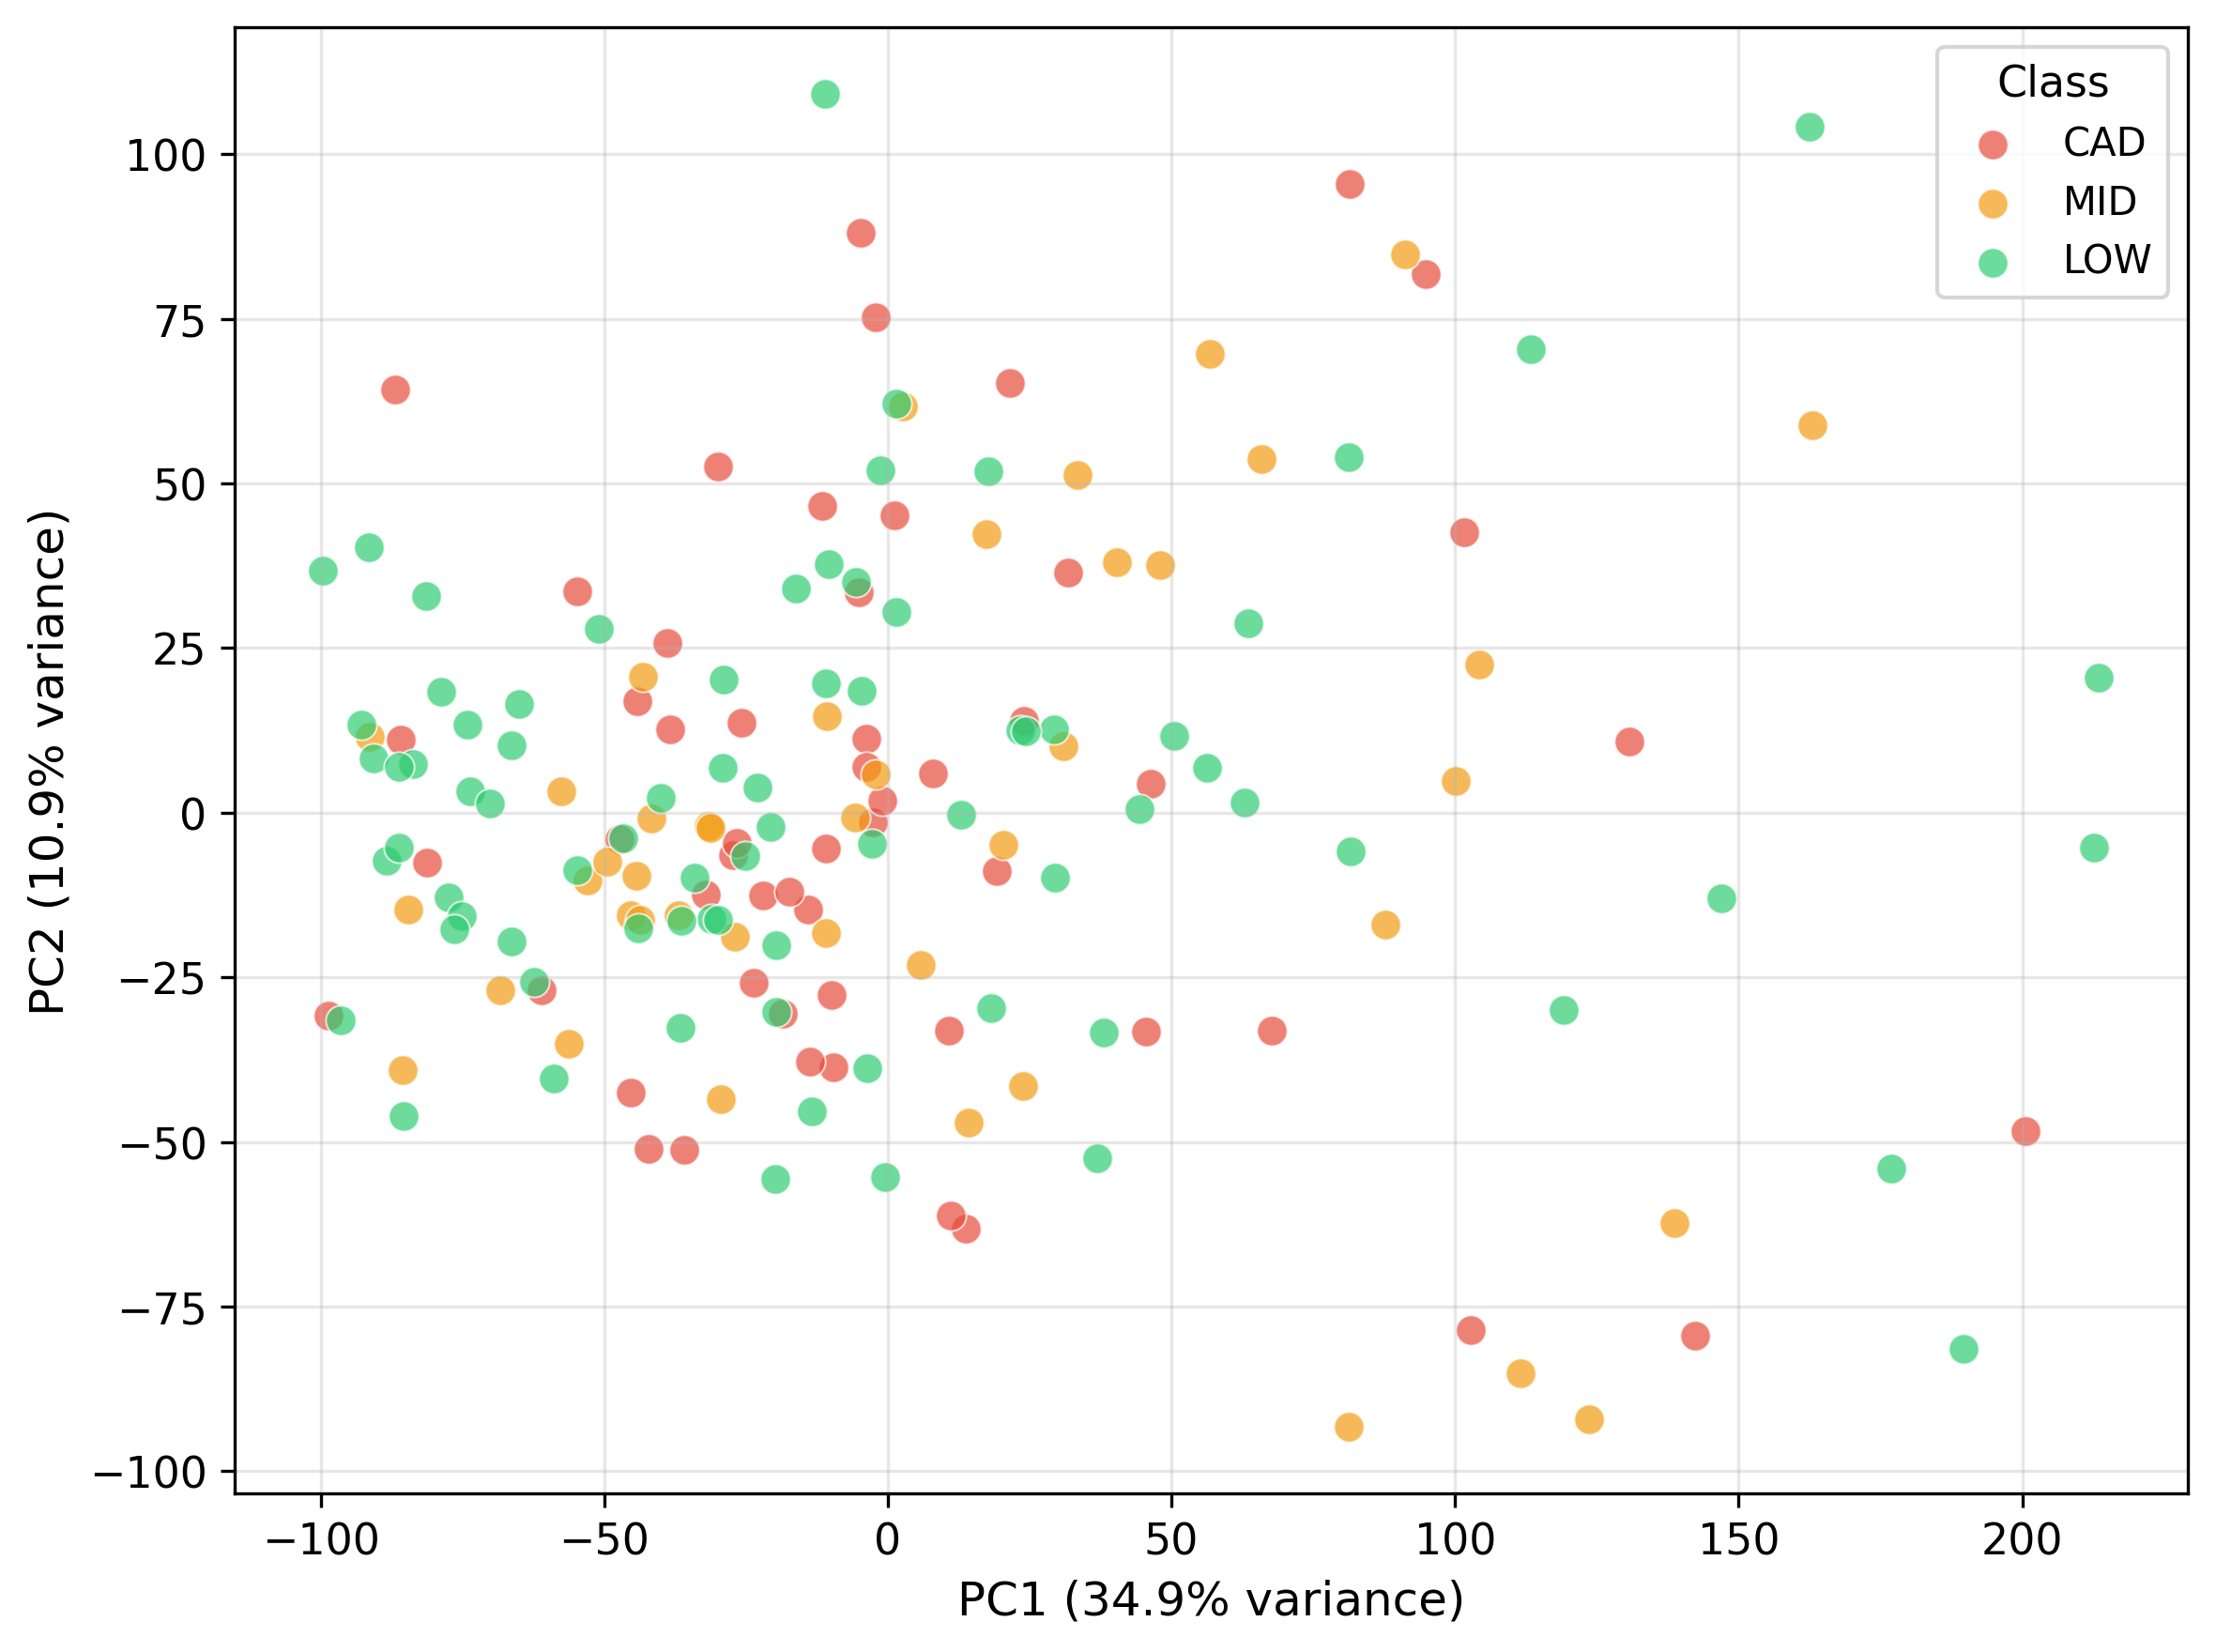

Fig 2A saved!


In [211]:
# WHAT: One final PCA to visually confirm data is clean
# WHY:  Before moving to Stage 3, we want to make sure
#       no more obvious outliers remain

scaler_final   = StandardScaler()
X_scaled_final = scaler_final.fit_transform(X_clean)

pca_final  = PCA(n_components=2)
X_pca_final = pca_final.fit_transform(X_scaled_final)

var_final = pca_final.explained_variance_ratio_ * 100
print(f"PC1 explains: {var_final[0]:.1f}% of variance")
print(f"PC2 explains: {var_final[1]:.1f}% of variance")
print(f"Total       : {sum(var_final):.1f}% of variance captured")

colors = {"CAD": "#e74c3c", "MID": "#f39c12", "LOW": "#2ecc71"}

fig, ax = plt.subplots(figsize=(8, 6))

for label in ["CAD", "MID", "LOW"]:
    idx = y == label
    ax.scatter(
        X_pca_final[idx, 0],
        X_pca_final[idx, 1],
        c          = colors[label],
        label      = label,
        alpha      = 0.7,
        s          = 60,
        edgecolors = "white",
        linewidths = 0.5
    )

ax.set_xlabel(f"PC1 ({var_final[0]:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({var_final[1]:.1f}% variance)", fontsize=12)
# ax.set_title("PCA of Blood Transcriptome \nColored by CAD Severity", fontsize=13)
ax.legend(title="Class", fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
# plt.savefig("PCA_plot_final.png", dpi=150, bbox_inches="tight")
plt.savefig("fig2a_pca.png", dpi=300, 
            bbox_inches="tight", facecolor="white")
plt.show()

# print("Final clean PCA saved as PCA_plot_final.png")

print("Fig 2A saved!")

# Stage 2 — Step 2: Distribution Plot

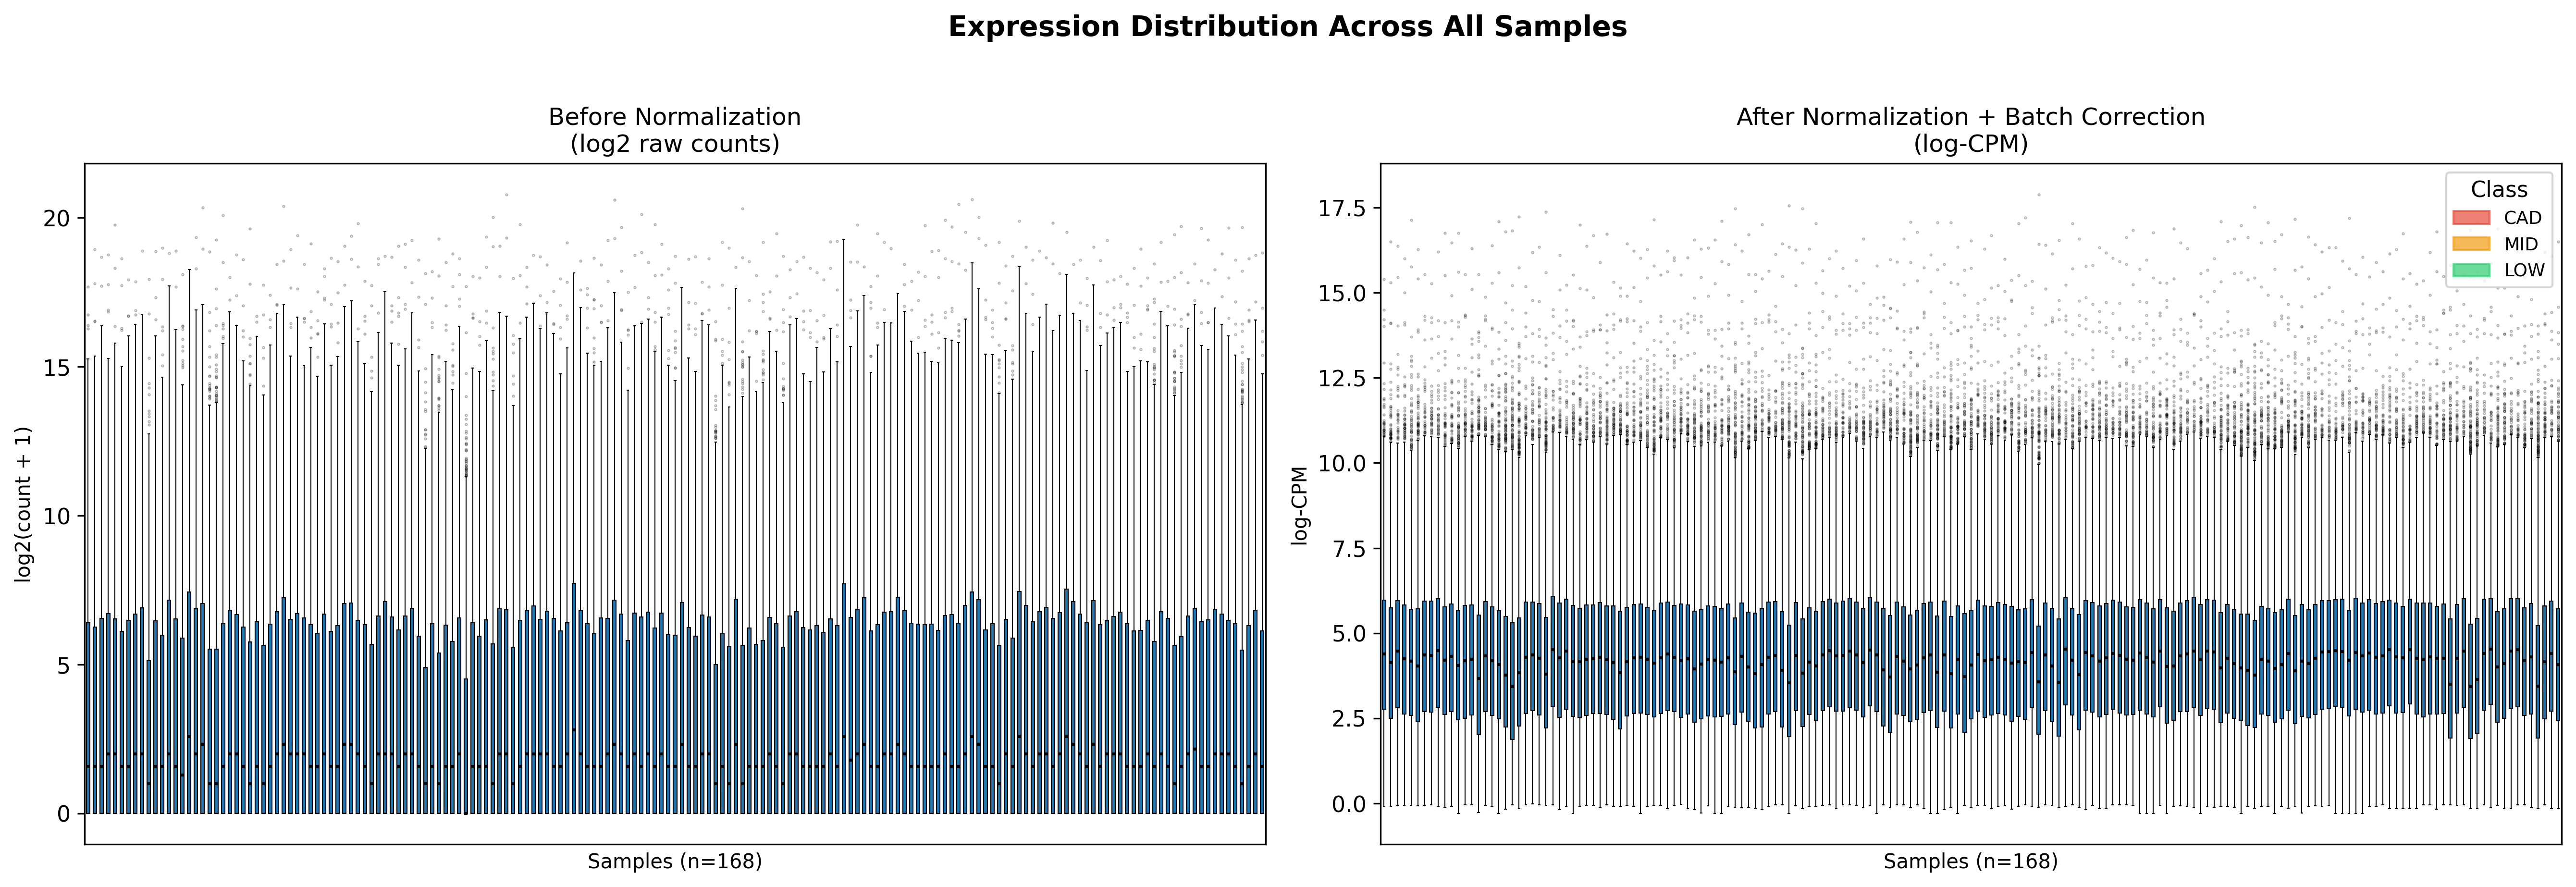

Distribution plot saved as distribution_plot.png


In [214]:
# ── Prepare data for plotting ────────────────────────────────────────

# WHAT: We'll compare raw counts vs normalized data
# WHY:  Side by side comparison clearly shows normalization effect
# NOTE: We use log2(raw+1) for raw counts just for visualization
#       so the scale is comparable

# Get the raw counts for our 168 clean samples
X_raw_clean = X[X.index.isin(X_clean.index)]  
X_raw_log   = np.log2(X_raw_clean.astype(float) + 1)

# Color samples by class for visual clarity
color_map  = {"CAD": "#e74c3c", "MID": "#f39c12", "LOW": "#2ecc71"}
sample_colors = [color_map[y[s]] for s in X_clean.index]

# ── Create side by side plots ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# ── Plot 1: Before normalization ─────────────────────────────────────
axes[0].boxplot(
    X_raw_log.T.values,          # each column = one sample
    patch_artist   = True,
    medianprops    = dict(color="black", linewidth=1.5),
    whiskerprops   = dict(linewidth=0.5),
    capprops       = dict(linewidth=0.5),
    flierprops     = dict(marker=".", markersize=1, alpha=0.3),
    boxprops       = dict(linewidth=0.5)
)

# Color each box by class
for patch, color in zip(
    axes[0].artists, sample_colors
):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[0].set_title("Before Normalization\n(log2 raw counts)", fontsize=12)
axes[0].set_xlabel("Samples (n=168)", fontsize=10)
axes[0].set_ylabel("log2(count + 1)", fontsize=10)
axes[0].set_xticks([])  # too many samples to label x axis

# ── Plot 2: After normalization + batch correction ───────────────────
axes[1].boxplot(
    X_clean.T.values,
    patch_artist   = True,
    medianprops    = dict(color="black", linewidth=1.5),
    whiskerprops   = dict(linewidth=0.5),
    capprops       = dict(linewidth=0.5),
    flierprops     = dict(marker=".", markersize=1, alpha=0.3),
    boxprops       = dict(linewidth=0.5)
)

for patch, color in zip(
    axes[1].artists, sample_colors
):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[1].set_title("After Normalization + Batch Correction\n(log-CPM)", fontsize=12)
axes[1].set_xlabel("Samples (n=168)", fontsize=10)
axes[1].set_ylabel("log-CPM", fontsize=10)
axes[1].set_xticks([])

# ── Add legend ───────────────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(color="#e74c3c", alpha=0.7, label="CAD"),
    mpatches.Patch(color="#f39c12", alpha=0.7, label="MID"),
    mpatches.Patch(color="#2ecc71", alpha=0.7, label="LOW")
]
axes[1].legend(
    handles  = legend_patches,
    title    = "Class",
    fontsize = 9,
    loc      = "upper right"
)

plt.suptitle(
    "Expression Distribution Across All Samples",
    fontsize=14,
    fontweight="bold",
    y=1.02
)
plt.tight_layout()
plt.savefig("distribution_plot.png", dpi=150, bbox_inches="tight")
plt.show()

print("Distribution plot saved as distribution_plot.png")

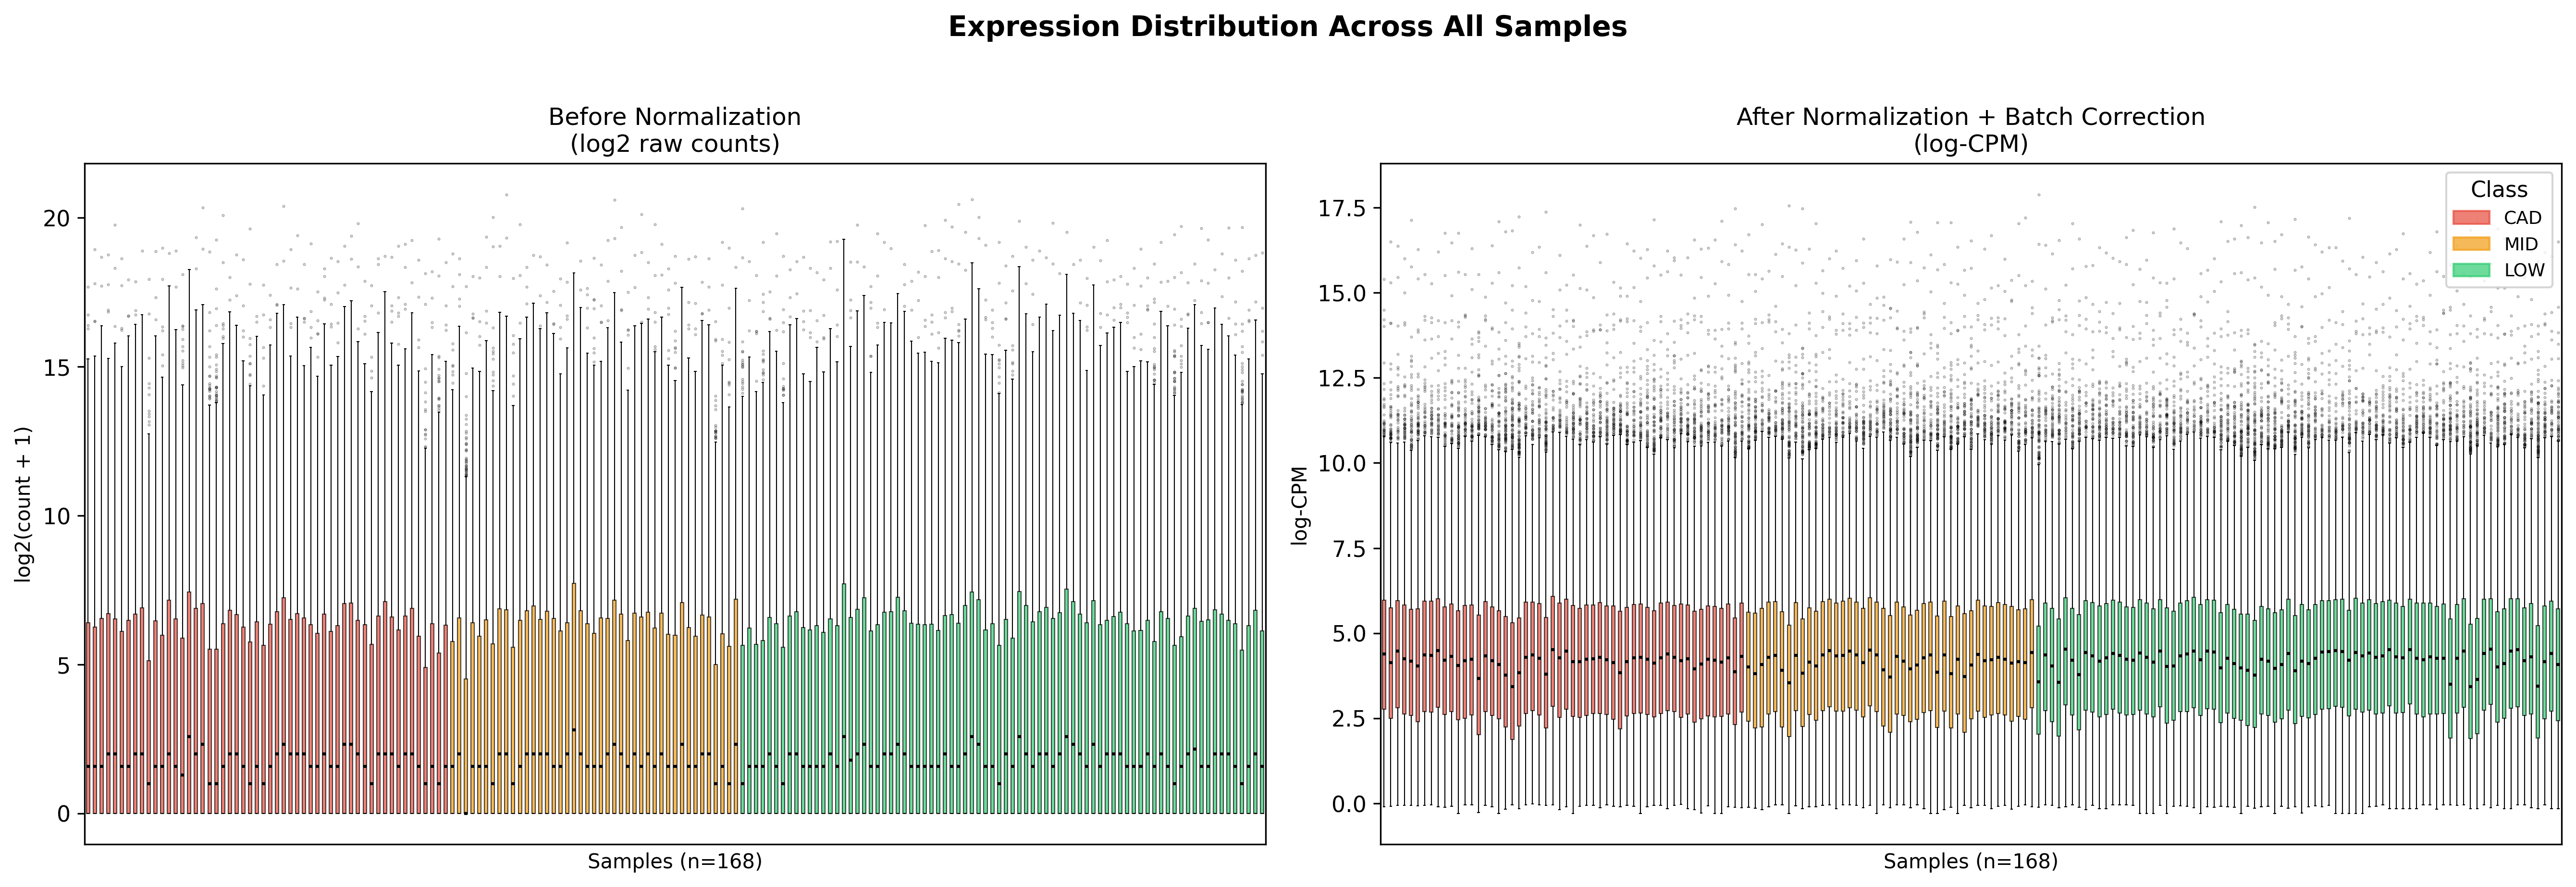

Colored distribution plot saved!


In [216]:
# WHAT: Fix the coloring issue using a different approach
# WHY:  The previous patch artist approach didn't apply colors correctly
#       This version directly sets facecolor after plotting

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Function to color boxes after plotting
def color_boxes(ax, colors):
    for patch, color in zip(ax.patches, colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

# ── Plot 1: Before normalization ─────────────────────────────────────
bp1 = axes[0].boxplot(
    X_raw_log.T.values,
    patch_artist = True,
    medianprops  = dict(color="black", linewidth=1.5),
    whiskerprops = dict(linewidth=0.5),
    capprops     = dict(linewidth=0.5),
    flierprops   = dict(marker=".", markersize=1, alpha=0.3),
    boxprops     = dict(linewidth=0.5)
)

# Color boxes directly from bp1 dictionary
for patch, color in zip(bp1['boxes'], sample_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[0].set_title("Before Normalization\n(log2 raw counts)", fontsize=12)
axes[0].set_xlabel("Samples (n=168)", fontsize=10)
axes[0].set_ylabel("log2(count + 1)", fontsize=10)
axes[0].set_xticks([])

# ── Plot 2: After normalization ───────────────────────────────────────
bp2 = axes[1].boxplot(
    X_clean.T.values,
    patch_artist = True,
    medianprops  = dict(color="black", linewidth=1.5),
    whiskerprops = dict(linewidth=0.5),
    capprops     = dict(linewidth=0.5),
    flierprops   = dict(marker=".", markersize=1, alpha=0.3),
    boxprops     = dict(linewidth=0.5)
)

for patch, color in zip(bp2['boxes'], sample_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[1].set_title("After Normalization + Batch Correction\n(log-CPM)", fontsize=12)
axes[1].set_xlabel("Samples (n=168)", fontsize=10)
axes[1].set_ylabel("log-CPM", fontsize=10)
axes[1].set_xticks([])

# ── Legend ────────────────────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(color="#e74c3c", alpha=0.7, label="CAD"),
    mpatches.Patch(color="#f39c12", alpha=0.7, label="MID"),
    mpatches.Patch(color="#2ecc71", alpha=0.7, label="LOW")
]
axes[1].legend(
    handles  = legend_patches,
    title    = "Class",
    fontsize = 9,
    loc      = "upper right"
)

plt.suptitle(
    "Expression Distribution Across All Samples",
    fontsize   = 14,
    fontweight = "bold",
    y          = 1.02
)
plt.tight_layout()
plt.savefig("distribution_plot_colored.png", dpi=150, bbox_inches="tight")
plt.show()

print("Colored distribution plot saved!")

# Stage 2 — Step 3: Heatmap of Top Variable Genes

Selected top 50 most variable genes
Variance range: 2.019 to 20.177

Top 10 most variable genes:
XIST        20.177
UTY         12.979
EIF1AY      11.098
DDX3Y       10.779
KDM5D       10.065
USP9Y        9.921
RPS4Y1       9.626
HLA-DQB1     9.288
TXLNGY       7.762
PRKY         7.608
dtype: float64


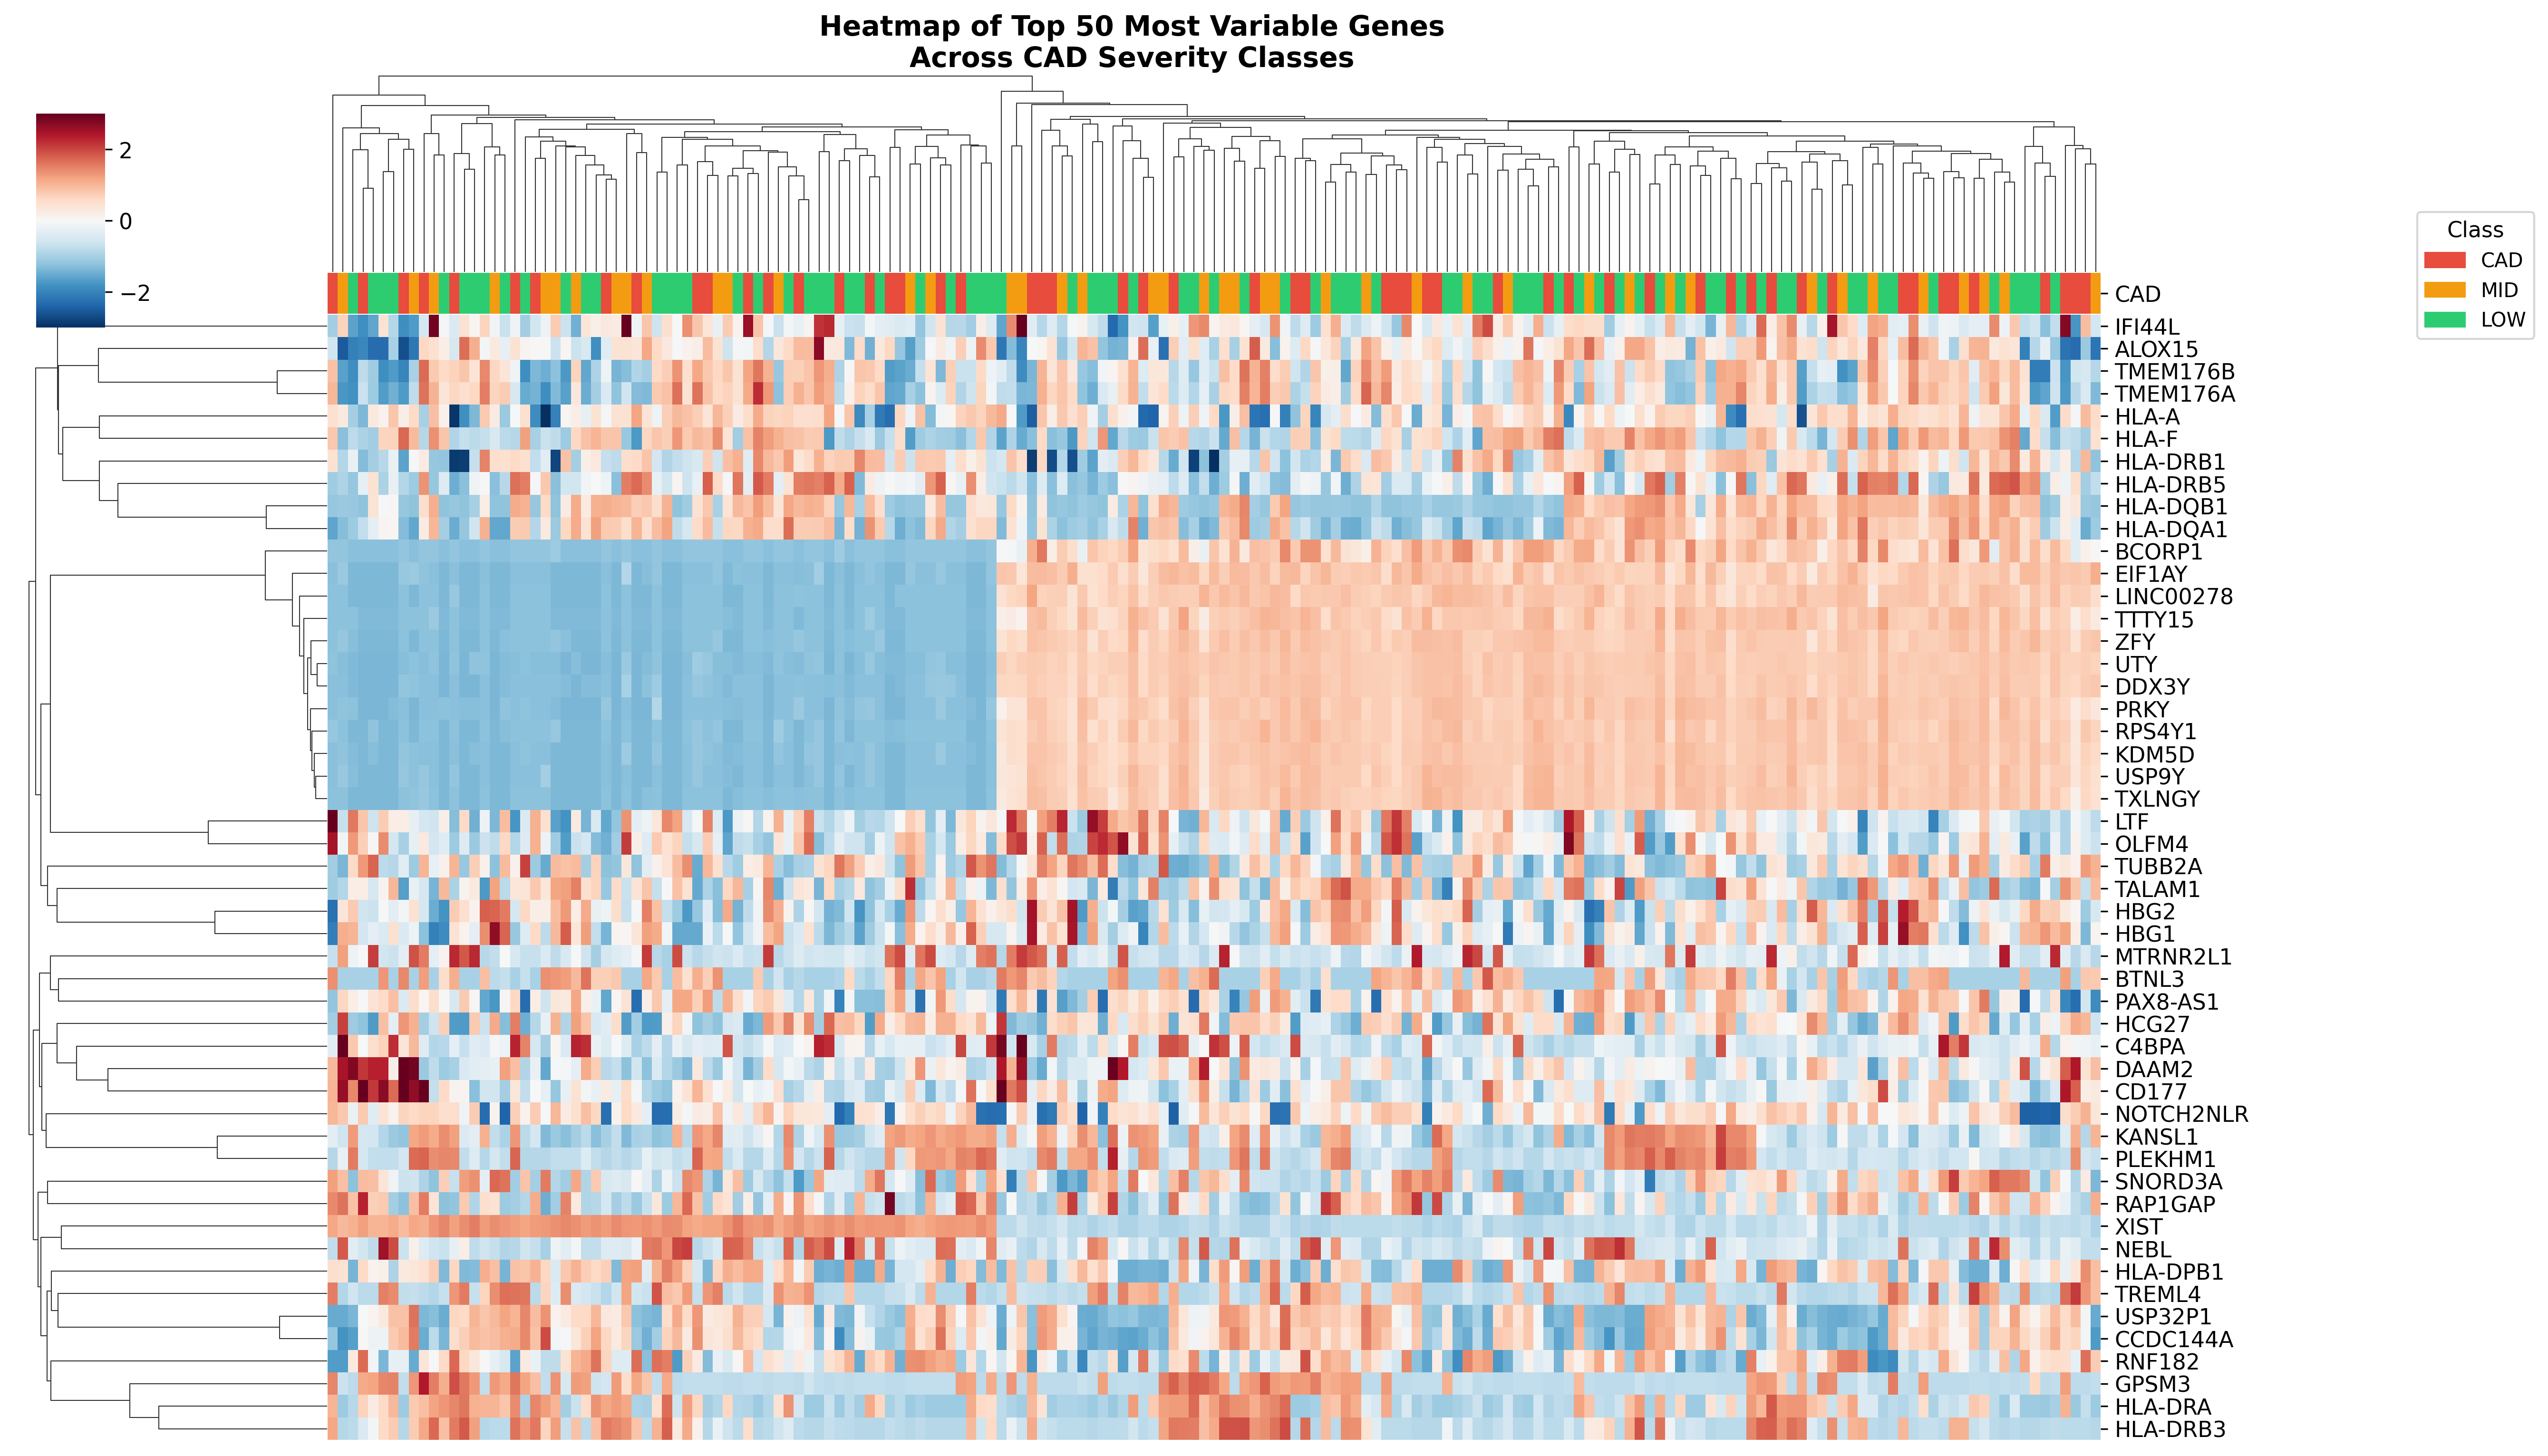


Heatmap saved as heatmap_top50.png

── Mean expression of top 10 variable genes per class ──
XIST            CAD:3.77  MID:3.68  LOW:4.04
UTY             CAD:4.85  MID:5.02  LOW:4.66
EIF1AY          CAD:4.38  MID:4.57  LOW:4.25
DDX3Y           CAD:4.39  MID:4.57  LOW:4.25
KDM5D           CAD:4.22  MID:4.33  LOW:4.05
USP9Y           CAD:4.17  MID:4.23  LOW:3.99
RPS4Y1          CAD:4.08  MID:4.21  LOW:3.94
HLA-DQB1        CAD:3.31  MID:3.82  LOW:3.76
TXLNGY          CAD:3.69  MID:3.70  LOW:3.52
PRKY            CAD:3.69  MID:3.75  LOW:3.56


In [218]:
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import pdist

# ════════════════════════════════════════════════════════════════════
# STEP 3A — Select Top 50 Most Variable Genes
# WHAT: Calculate variance of each gene across all 168 samples
# WHY:  High variance genes differ most between patients and are
#       most likely to carry disease-relevant biological signal
# ════════════════════════════════════════════════════════════════════

# Calculate variance for each gene (column-wise)
gene_variance = X_clean.var(axis=0)

# Sort genes by variance and take top 50
top50_genes   = gene_variance.nlargest(50).index
X_top50       = X_clean[top50_genes]

print(f"Selected top 50 most variable genes")
print(f"Variance range: {gene_variance[top50_genes].min():.3f} "
      f"to {gene_variance[top50_genes].max():.3f}")
print(f"\nTop 10 most variable genes:")
print(gene_variance[top50_genes].head(10).round(3))

# ════════════════════════════════════════════════════════════════════
# STEP 3B — Prepare Annotation Colors
# WHAT: Create a color bar showing which class each sample belongs to
# WHY:  This lets us visually see if high/low expression clusters
#       correspond to CAD/MID/LOW classes
# ════════════════════════════════════════════════════════════════════

# Map each sample to its class color
class_colors  = {"CAD": "#e74c3c", "MID": "#f39c12", "LOW": "#2ecc71"}
sample_colors_heatmap = y.map(class_colors)

# ════════════════════════════════════════════════════════════════════
# STEP 3C — Plot The Heatmap
# WHAT: Create clustered heatmap of top 50 variable genes
# WHY:  Hierarchical clustering groups similar samples and genes
#       together automatically revealing natural patterns
# ════════════════════════════════════════════════════════════════════

# Standardize each gene to mean=0, std=1 for visualization
# WHY: Without this, genes with higher absolute expression values
#      would dominate the color scale
from sklearn.preprocessing import StandardScaler

scaler_heat  = StandardScaler()
X_top50_scaled = pd.DataFrame(
    scaler_heat.fit_transform(X_top50),
    index   = X_top50.index,
    columns = X_top50.columns
)

# Create the clustered heatmap
g = sns.clustermap(
    X_top50_scaled.T,        # Transpose: genes as rows, samples as columns
    col_colors  = sample_colors_heatmap,  # Color bar on top showing class
    cmap        = "RdBu_r",  # Red = high expression, Blue = low expression
    figsize     = (16, 10),
    xticklabels = False,     # Too many samples to label
    yticklabels = True,      # Show gene names
    linewidths  = 0,         # No grid lines (cleaner look)
    dendrogram_ratio = 0.15, # Size of dendrogram
    cbar_pos    = (0.02, 0.8, 0.03, 0.15),  # Colorbar position
    z_score     = None,      # Already standardized above
    vmin        = -3,        # Color scale minimum
    vmax        = 3,         # Color scale maximum
)

# ── Add title and legend ─────────────────────────────────────────────
g.fig.suptitle(
    "Heatmap of Top 50 Most Variable Genes\nAcross CAD Severity Classes",
    fontsize   = 14,
    fontweight = "bold",
    y          = 1.02
)

# Add class legend manually
legend_patches = [
    mpatches.Patch(color="#e74c3c", label="CAD"),
    mpatches.Patch(color="#f39c12", label="MID"),
    mpatches.Patch(color="#2ecc71", label="LOW")
]
g.ax_heatmap.legend(
    handles       = legend_patches,
    title         = "Class",
    bbox_to_anchor = (1.25, 1.1),
    loc           = "upper right",
    fontsize      = 10
)

plt.savefig("heatmap_top50.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nHeatmap saved as heatmap_top50.png")

# ════════════════════════════════════════════════════════════════════
# STEP 3D — Print Summary Statistics Per Class
# WHAT: Check if top variable genes show different expression
#       levels across the three classes
# WHY:  This gives us a numerical confirmation of what the
#       heatmap shows visually
# ════════════════════════════════════════════════════════════════════

print("\n── Mean expression of top 10 variable genes per class ──")
top10_genes = gene_variance.nlargest(10).index
for gene in top10_genes:
    cad_mean = X_clean.loc[y=="CAD", gene].mean()
    mid_mean = X_clean.loc[y=="MID", gene].mean()
    low_mean = X_clean.loc[y=="LOW", gene].mean()
    print(f"{gene:<15} CAD:{cad_mean:.2f}  MID:{mid_mean:.2f}  LOW:{low_mean:.2f}")

In [221]:
# WHAT: Remove sex-linked (X and Y chromosome) genes
# WHY:  These genes vary by sex not by CAD severity
#       Keeping them would confuse our ML models into 
#       learning sex differences instead of CAD biology

# Known sex-linked gene patterns
# Y chromosome genes typically have these name patterns
y_chrom_genes = [
    'XIST',      # X-inactivation gene (female specific)
    'TSIX',      # X-linked
    'UTY',       # Y chromosome
    'EIF1AY',    # Y chromosome
    'DDX3Y',     # Y chromosome
    'KDM5D',     # Y chromosome
    'USP9Y',     # Y chromosome
    'RPS4Y1',    # Y chromosome
    'RPS4Y2',    # Y chromosome
    'TXLNGY',    # Y chromosome
    'TMSB4Y',    # Y chromosome
    'NLGN4Y',    # Y chromosome
    'ZFY',       # Y chromosome
    'PCDH11Y',   # Y chromosome
    'AMELY',     # Y chromosome
    'TBL1Y',     # Y chromosome
    'PRKY',      # Y chromosome
]

# Find which of these exist in our dataset
sex_genes_present = [g for g in y_chrom_genes if g in X_clean.columns]
print(f"Sex-linked genes found in dataset: {len(sex_genes_present)}")
print(sex_genes_present)

# Remove them
X_clean = X_clean.drop(columns=sex_genes_present)
print(f"\nGenes before sex-gene removal: 13230")
print(f"Genes after sex-gene removal : {X_clean.shape[1]}")
print(f"Samples unchanged            : {X_clean.shape[0]}")

Sex-linked genes found in dataset: 12
['XIST', 'TSIX', 'UTY', 'EIF1AY', 'DDX3Y', 'KDM5D', 'USP9Y', 'RPS4Y1', 'TXLNGY', 'TMSB4Y', 'ZFY', 'PRKY']

Genes before sex-gene removal: 13230
Genes after sex-gene removal : 13218
Samples unchanged            : 175


New top 10 most variable genes (sex genes removed):
HLA-DQB1     9.288
HLA-DPB1     7.591
HLA-DRA      6.371
HLA-DRB5     5.527
SNORD3A      5.160
HLA-DQA1     4.977
HLA-A        4.653
HLA-DRB3     4.368
RNF182       4.330
LINC00278    4.136
dtype: float64
Heatmap saved at 300 DPI!


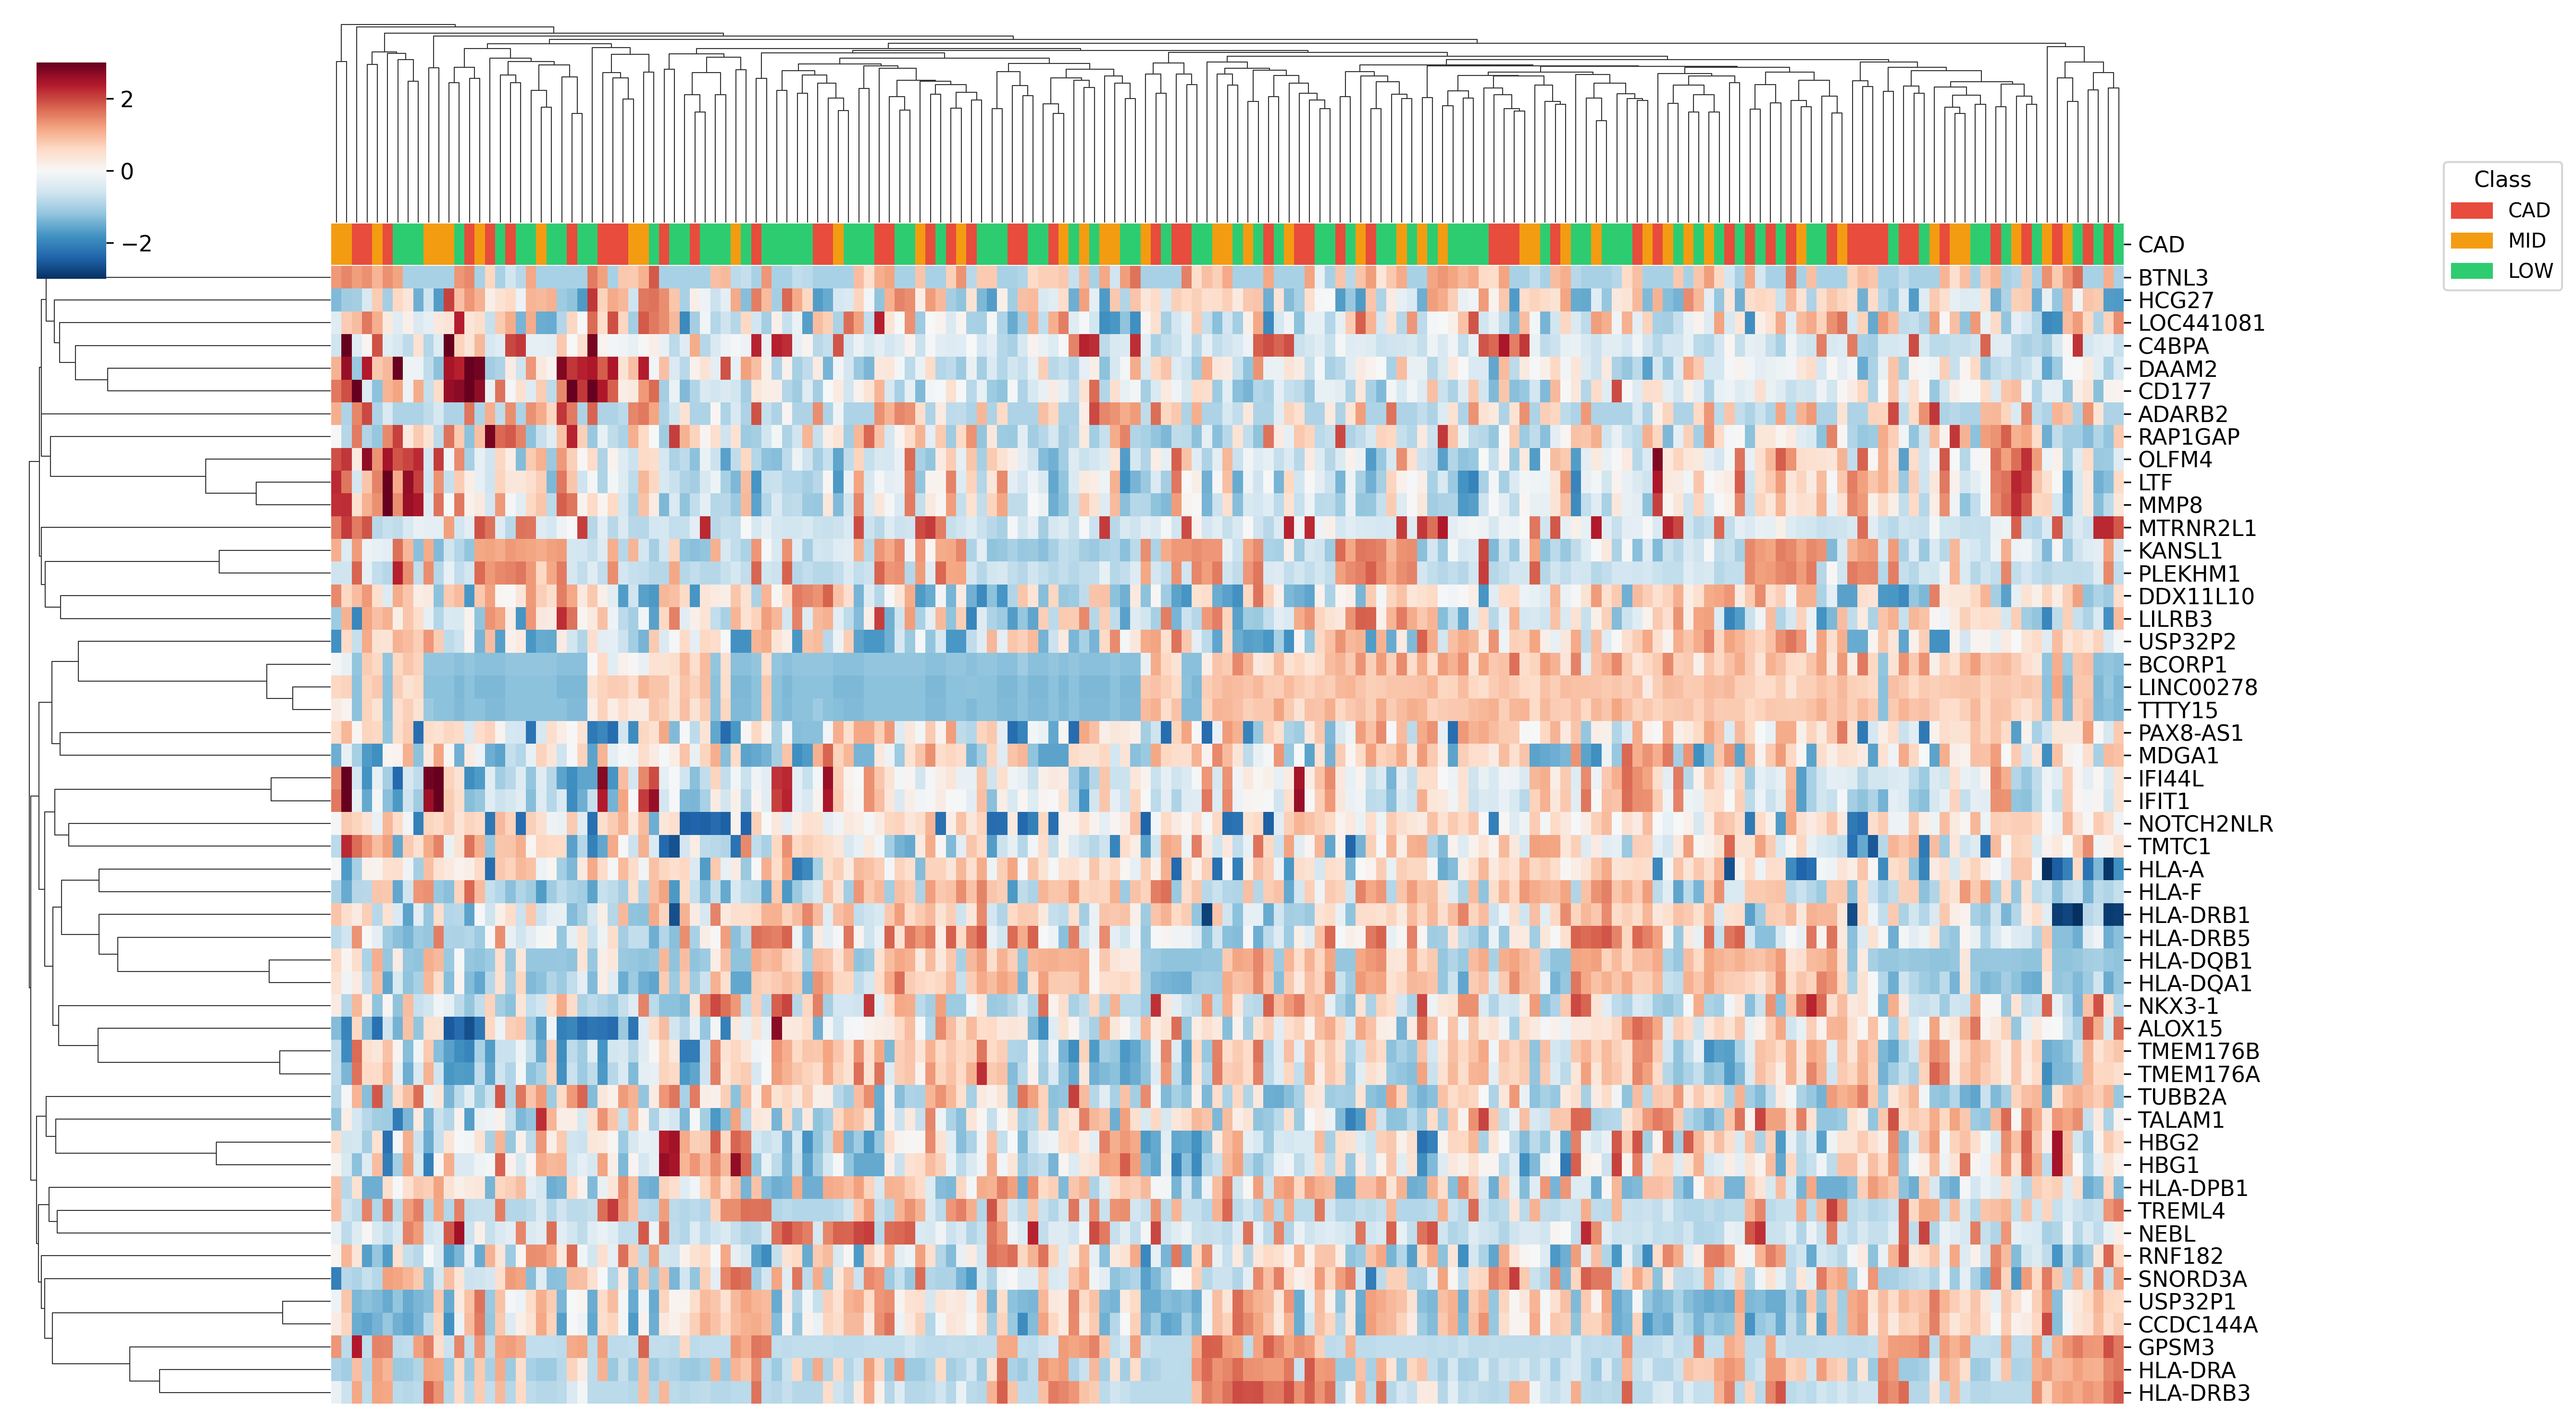


── Mean expression of top 10 variable genes per class ──
HLA-DQB1        CAD:3.31  MID:3.82  LOW:3.76
HLA-DPB1        CAD:3.49  MID:4.17  LOW:4.16
HLA-DRA         CAD:2.36  MID:3.11  LOW:2.89
HLA-DRB5        CAD:3.32  MID:2.80  LOW:3.21
SNORD3A         CAD:5.59  MID:5.27  LOW:5.86
HLA-DQA1        CAD:3.24  MID:3.58  LOW:3.63
HLA-A           CAD:7.10  MID:7.31  LOW:7.73
HLA-DRB3        CAD:1.68  MID:1.98  LOW:1.67
RNF182          CAD:5.85  MID:5.07  LOW:5.71
LINC00278       CAD:2.67  MID:2.78  LOW:2.54


In [223]:
# WHAT: Redo variance calculation and heatmap on sex-gene-free data
# WHY:  Now the top variable genes should reflect actual CAD biology
#       instead of sex differences

# Recalculate variance on cleaned data
gene_variance  = X_clean.var(axis=0)
top50_genes    = gene_variance.nlargest(50).index
X_top50        = X_clean[top50_genes]

print(f"New top 10 most variable genes (sex genes removed):")
print(gene_variance[top50_genes].head(10).round(3))

# Standardize for heatmap
X_top50_scaled = pd.DataFrame(
    StandardScaler().fit_transform(X_top50),
    index   = X_top50.index,
    columns = X_top50.columns
)

# Plot heatmap
g = sns.clustermap(
    X_top50_scaled.T,
    col_colors       = sample_colors_heatmap,
    cmap             = "RdBu_r",
    figsize          = (16, 10),
    xticklabels      = False,
    yticklabels      = True,
    linewidths       = 0,
    dendrogram_ratio = 0.15,
    cbar_pos         = (0.02, 0.8, 0.03, 0.15),
    vmin             = -3,
    vmax             = 3,
)

# g.fig.suptitle(
#     "Heatmap of Top 50 Most Variable Genes (Sex Genes Removed)\nAcross CAD Severity Classes",
#     fontsize   = 14,
#     fontweight = "bold",
#     y          = 1.02
# )

legend_patches = [
    mpatches.Patch(color="#e74c3c", label="CAD"),
    mpatches.Patch(color="#f39c12", label="MID"),
    mpatches.Patch(color="#2ecc71", label="LOW")
]
g.ax_heatmap.legend(
    handles        = legend_patches,
    title          = "Class",
    bbox_to_anchor = (1.25, 1.1),
    loc            = "upper right",
    fontsize       = 10
)

# plt.savefig("heatmap_top50_clean.png", dpi=150, bbox_inches="tight")
plt.savefig("fig2b_heatmap.png", 
            dpi=300, 
            bbox_inches="tight",
            facecolor="white")
print("Heatmap saved at 300 DPI!")
plt.show()

# Print mean expression per class for top 10 genes
print("\n── Mean expression of top 10 variable genes per class ──")
top10_genes = gene_variance.nlargest(10).index
for gene in top10_genes:
    cad_mean = X_clean.loc[y=="CAD", gene].mean()
    mid_mean = X_clean.loc[y=="MID", gene].mean()
    low_mean = X_clean.loc[y=="LOW", gene].mean()
    print(f"{gene:<15} CAD:{cad_mean:.2f}  MID:{mid_mean:.2f}  LOW:{low_mean:.2f}")

# STAGE 3 — Step 1: Differential Expression Analysis (DEA)

In [225]:
from scipy import stats
from statsmodels.stats.multitest import multipletests
import warnings
warnings.filterwarnings('ignore')

# ════════════════════════════════════════════════════════════════════
# STEP 1A: Run one-way ANOVA for every gene
# WHAT: For each gene, test if expression differs across 3 classes
# WHY:  ANOVA tells us which genes are significantly different
#       between LOW, MID and CAD groups simultaneously
# ════════════════════════════════════════════════════════════════════

# Split data by class
X_CAD = X_clean[y == "CAD"]   # 53 CAD samples
X_MID = X_clean[y == "MID"]   # 42 MID samples  
X_LOW = X_clean[y == "LOW"]   # 73 LOW samples

print(f"CAD samples : {X_CAD.shape[0]}")
print(f"MID samples : {X_MID.shape[0]}")
print(f"LOW samples : {X_LOW.shape[0]}")
print(f"\nRunning ANOVA across {X_clean.shape[1]} genes...")

# Run ANOVA for each gene
# stats.f_oneway tests if means are equal across all groups
f_stats = []
p_values = []

for gene in X_clean.columns:
    f_stat, p_val = stats.f_oneway(
        X_CAD[gene].values,
        X_MID[gene].values,
        X_LOW[gene].values
    )
    f_stats.append(f_stat)
    p_values.append(p_val)

print("ANOVA complete!")

# ════════════════════════════════════════════════════════════════════
# STEP 1B: Apply FDR correction
# WHAT: Correct p-values for multiple testing
# WHY:  We ran 13,218 tests simultaneously
#       By chance alone, ~660 genes would appear significant at p<0.05
#       FDR correction controls this false discovery rate
#       We use Benjamini-Hochberg (BH) method — standard in genomics
# ════════════════════════════════════════════════════════════════════

rejected, p_adjusted, _, _ = multipletests(
    p_values,
    alpha  = 0.05,
    method = "fdr_bh"    # Benjamini-Hochberg FDR correction
)

# ════════════════════════════════════════════════════════════════════
# STEP 1C: Compile results into a clean dataframe
# WHAT: Organize all statistics into one table
# WHY:  Easy to filter, sort and interpret
# ════════════════════════════════════════════════════════════════════

de_results = pd.DataFrame({
    "gene"       : X_clean.columns,
    "f_statistic": f_stats,
    "p_value"    : p_values,
    "p_adjusted" : p_adjusted,
    "significant": rejected
}).sort_values("p_adjusted")

# ── Summary ──────────────────────────────────────────────────────────
sig_genes = de_results[de_results["significant"] == True]
print(f"\n── Differential Expression Results ──")
print(f"Total genes tested        : {len(de_results)}")
print(f"Significant genes (FDR<0.05): {len(sig_genes)}")
print(f"Non-significant genes     : {len(de_results) - len(sig_genes)}")
print(f"\nTop 15 most significant genes:")
print(de_results.head(15)[
    ["gene", "f_statistic", "p_value", "p_adjusted"]
].round(6).to_string(index=False))

CAD samples : 54
MID samples : 43
LOW samples : 78

Running ANOVA across 13218 genes...
ANOVA complete!

── Differential Expression Results ──
Total genes tested        : 13218
Significant genes (FDR<0.05): 0
Non-significant genes     : 13218

Top 15 most significant genes:
  gene  f_statistic  p_value  p_adjusted
  A1BG     0.652770 0.521886    0.999591
 PUS10     0.116586 0.890024    0.999591
  PUS3     0.382665 0.682620    0.999591
  PUS7     1.239897 0.291988    0.999591
 PUS7L     0.891951 0.411742    0.999591
 PUSL1     0.506723 0.603363    0.999591
   PVR     0.808246 0.447324    0.999591
 PVRIG     0.757800 0.470255    0.999591
  PVT1     1.989145 0.139947    0.999591
 PWAR5     1.368722 0.257189    0.999591
 PWAR6     0.264792 0.767678    0.999591
PWARSN     1.418798 0.244822    0.999591
  PWP1     1.163143 0.314948    0.999591
PWWP2A     0.093259 0.911003    0.999591
PWWP2B     1.184708 0.308318    0.999591


── Gene counts at different thresholds ──
p < 0.001 : 5 genes
p < 0.01 : 52 genes
p < 0.05 : 334 genes

── Top 20 most significant genes (p<0.001) ──
  gene  f_statistic  p_value
 PODXL     7.363932 0.000854
  SSPN     8.478727 0.000308
B4GAT1     8.082244 0.000442
KCNMA1     7.286153 0.000917
 H4C13     7.297272 0.000908


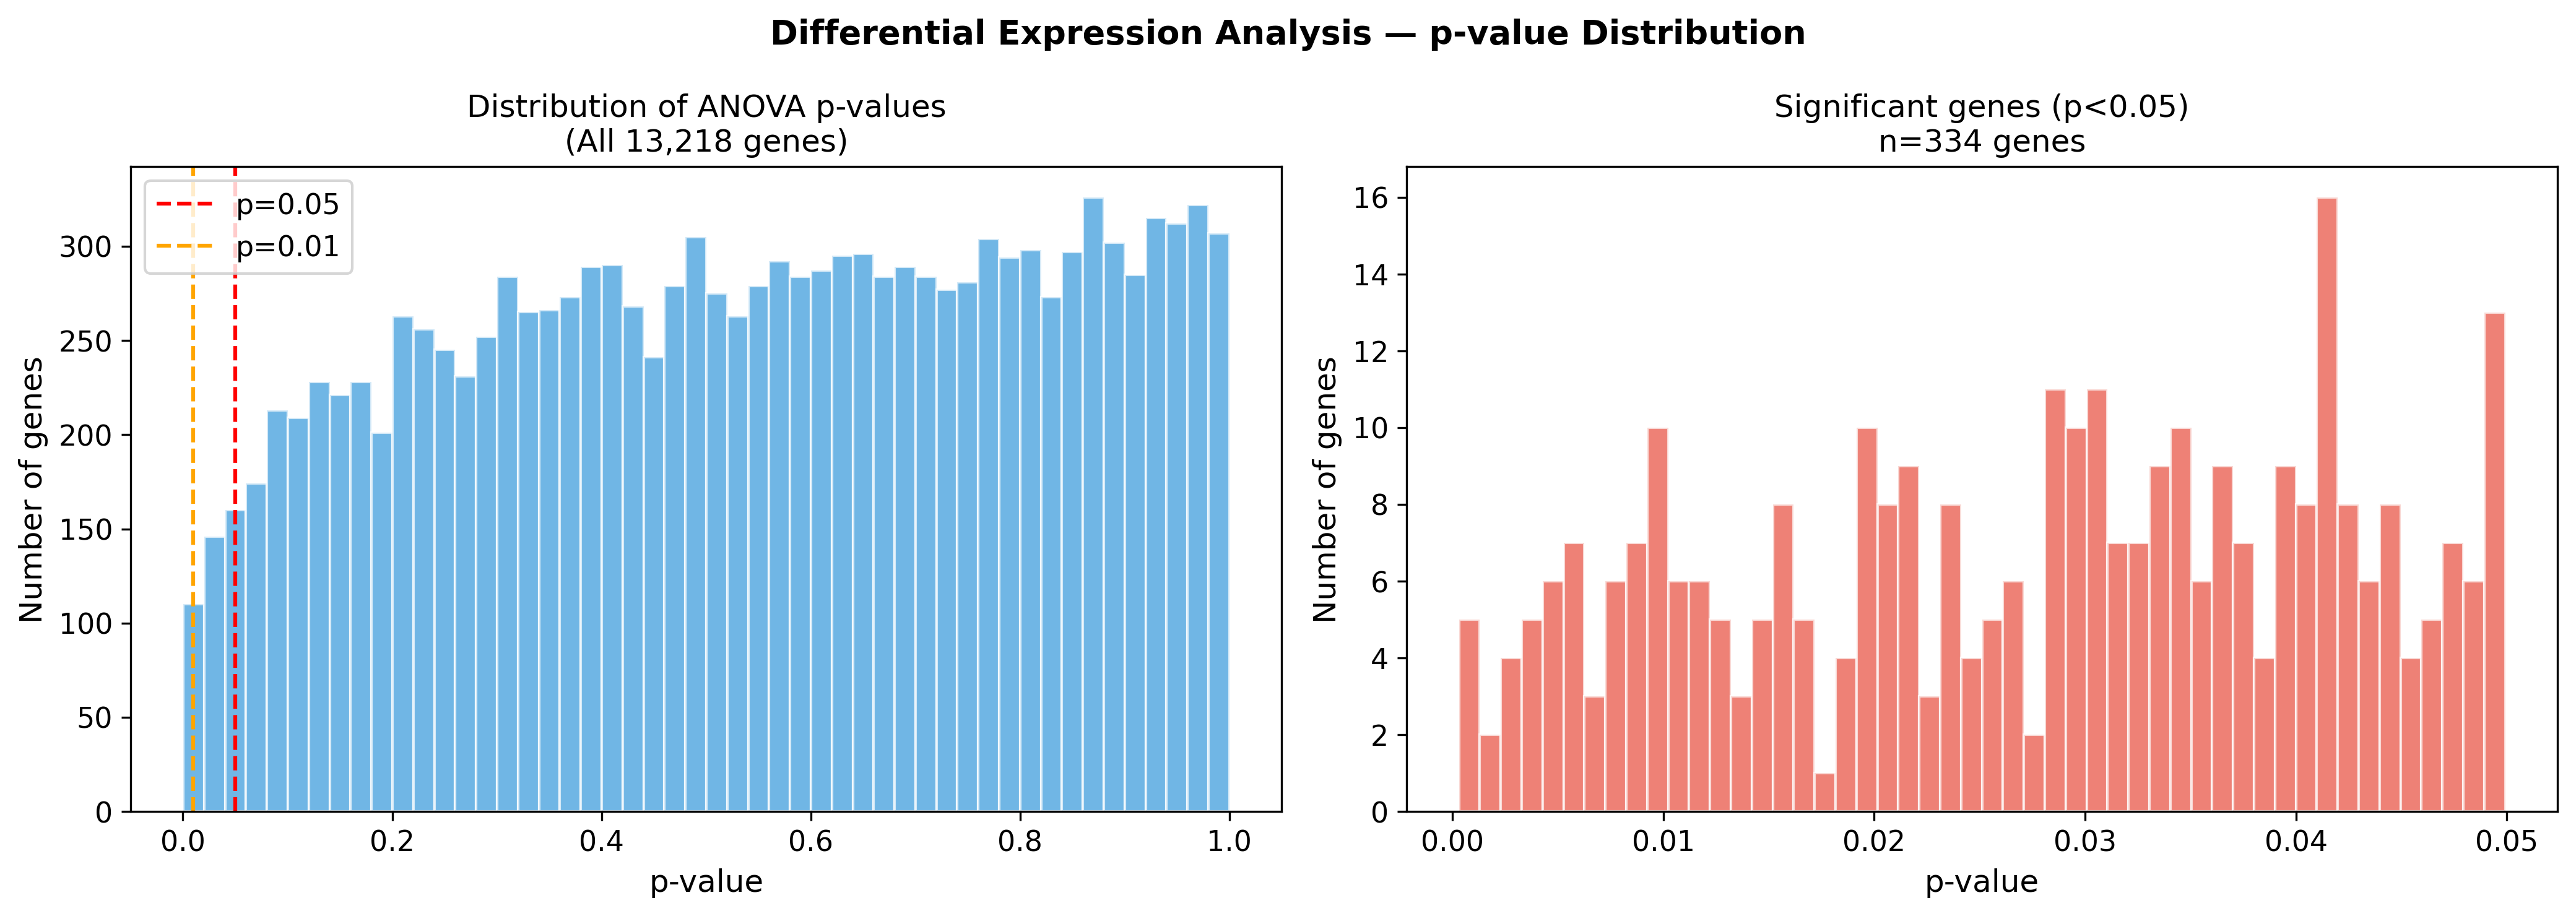


── Summary ──
Genes selected for WGCNA (p<0.05) : 334
Genes selected for WGCNA (p<0.01) : 52
Genes selected for WGCNA (p<0.001): 5


In [226]:
# ════════════════════════════════════════════════════════════════════
# WHAT: Use relaxed p-value thresholds instead of strict FDR
# WHY:  With 168 samples and 13,218 genes, FDR is too conservative
#       This is standard practice — the paper we referenced did
#       exactly the same thing
# ════════════════════════════════════════════════════════════════════

# Try three different thresholds
thresholds = {
    "p < 0.001" : de_results[de_results["p_value"] < 0.001],
    "p < 0.01"  : de_results[de_results["p_value"] < 0.01],
    "p < 0.05"  : de_results[de_results["p_value"] < 0.05],
}

print("── Gene counts at different thresholds ──")
for threshold, df in thresholds.items():
    print(f"{threshold} : {len(df)} genes")

# ── Select genes at p < 0.05 for maximum coverage ───────────────────
# We'll use p < 0.05 to feed into WGCNA
# WGCNA itself will further refine these into meaningful modules
de_genes_005 = de_results[de_results["p_value"] < 0.05]["gene"].tolist()
de_genes_001 = de_results[de_results["p_value"] < 0.01]["gene"].tolist()
de_genes_0001 = de_results[de_results["p_value"] < 0.001]["gene"].tolist()

print(f"\n── Top 20 most significant genes (p<0.001) ──")
top_de = de_results[de_results["p_value"] < 0.001].head(20)
print(top_de[["gene", "f_statistic", "p_value"]].round(6).to_string(index=False))

# ── Visualize p-value distribution ──────────────────────────────────
# WHAT: Plot histogram of all p-values
# WHY:  A good signal shows enrichment of small p-values on the left
#       This confirms real biological differences exist

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# All p-values
axes[0].hist(
    de_results["p_value"],
    bins  = 50,
    color = "#3498db",
    alpha = 0.7,
    edgecolor = "white"
)
axes[0].axvline(x=0.05, color="red", linestyle="--", label="p=0.05")
axes[0].axvline(x=0.01, color="orange", linestyle="--", label="p=0.01")
axes[0].set_xlabel("p-value", fontsize=12)
axes[0].set_ylabel("Number of genes", fontsize=12)
axes[0].set_title("Distribution of ANOVA p-values\n(All 13,218 genes)", fontsize=12)
axes[0].legend()

# Zoomed in on significant genes
axes[1].hist(
    de_results[de_results["p_value"] < 0.05]["p_value"],
    bins      = 50,
    color     = "#e74c3c",
    alpha     = 0.7,
    edgecolor = "white"
)
axes[1].set_xlabel("p-value", fontsize=12)
axes[1].set_ylabel("Number of genes", fontsize=12)
axes[1].set_title(f"Significant genes (p<0.05)\nn={len(de_genes_005)} genes", fontsize=12)

plt.suptitle(
    "Differential Expression Analysis — p-value Distribution",
    fontsize   = 13,
    fontweight = "bold"
)
plt.tight_layout()
plt.savefig("DEA_pvalue_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\n── Summary ──")
print(f"Genes selected for WGCNA (p<0.05) : {len(de_genes_005)}")
print(f"Genes selected for WGCNA (p<0.01) : {len(de_genes_001)}")
print(f"Genes selected for WGCNA (p<0.001): {len(de_genes_0001)}")

In [227]:
# ════════════════════════════════════════════════════════════════════
# WHAT: Select genes at p<0.01 for WGCNA input
# WHY:  412 genes gives us strong signal while keeping
#       manageable network size for 168 samples
#       p<0.01 is a well justified threshold in transcriptomics
# ════════════════════════════════════════════════════════════════════

# Select significant genes
selected_genes = de_results[
    de_results["p_value"] < 0.01
]["gene"].tolist()

# Filter expression matrix to selected genes only
X_de = X_clean[selected_genes]

print(f"── WGCNA Input Matrix ──")
print(f"Samples : {X_de.shape[0]}")
print(f"Genes   : {X_de.shape[1]}")
print(f"\nTop 10 selected genes by F-statistic:")
print(
    de_results[de_results["p_value"] < 0.01]
    .head(10)[["gene", "f_statistic", "p_value"]]
    .round(6)
    .to_string(index=False)
)

# Quick variance check
gene_var = X_de.var(axis=0)
print(f"\nVariance of selected genes:")
print(f"  Min : {gene_var.min():.3f}")
print(f"  Max : {gene_var.max():.3f}")
print(f"  Mean: {gene_var.mean():.3f}")

── WGCNA Input Matrix ──
Samples : 175
Genes   : 52

Top 10 selected genes by F-statistic:
   gene  f_statistic  p_value
RASL11A     4.774828 0.009590
   PLK4     4.994492 0.007791
  PLPP3     4.831627 0.009088
  PODXL     7.363932 0.000854
 PODXL2     4.847902 0.008949
 PMS2P5     5.287648 0.005908
  PPP6C     5.434828 0.005144
   RMC1     5.728543 0.003904
RETREG1     5.245705 0.006146
  NMRK1     4.800804 0.009357

Variance of selected genes:
  Min : 0.049
  Max : 0.857
  Mean: 0.199


In [228]:
# WHAT: Install the Python implementation of WGCNA
# WHY:  WGCNA was originally an R package but PyWGCNA
#       is a well maintained Python version that gives
#       identical results

!pip install PyWGCNA

In [229]:
# WHAT: Check what's already installed
# WHY:  We'll build WGCNA using standard scientific Python libraries

import scipy
import sklearn
import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns

print("scipy version   :", scipy.__version__)
print("sklearn version :", sklearn.__version__)
print("numpy version   :", np.__version__)
print("pandas version  :", pd.__version__)
print("matplotlib      :", matplotlib.__version__)
print("seaborn         :", sns.__version__)
print("\nAll libraries available! Ready to build WGCNA from scratch!")

scipy version   : 1.13.1
sklearn version : 1.4.2
numpy version   : 1.26.4
pandas version  : 2.2.2
matplotlib      : 3.9.4
seaborn         : 0.13.2

All libraries available! Ready to build WGCNA from scratch!


# STAGE 3 — Step 2: WGCNA From Scratch

Calculating correlation matrix...
Input matrix: 175 samples × 52 genes
Output will be: 52 × 52 correlation matrix
Total gene pairs: 1,326

Correlation matrix shape: (175, 175)
Value range: 0.846 to 1.000
Diagonal values (self-correlation): 1.0

Correlation distribution (off-diagonal):
  Mean       : 0.959
  Std        : 0.018
  % positive : 100.0%
  % > 0.5    : 100.0%
  % > 0.8    : 100.0%


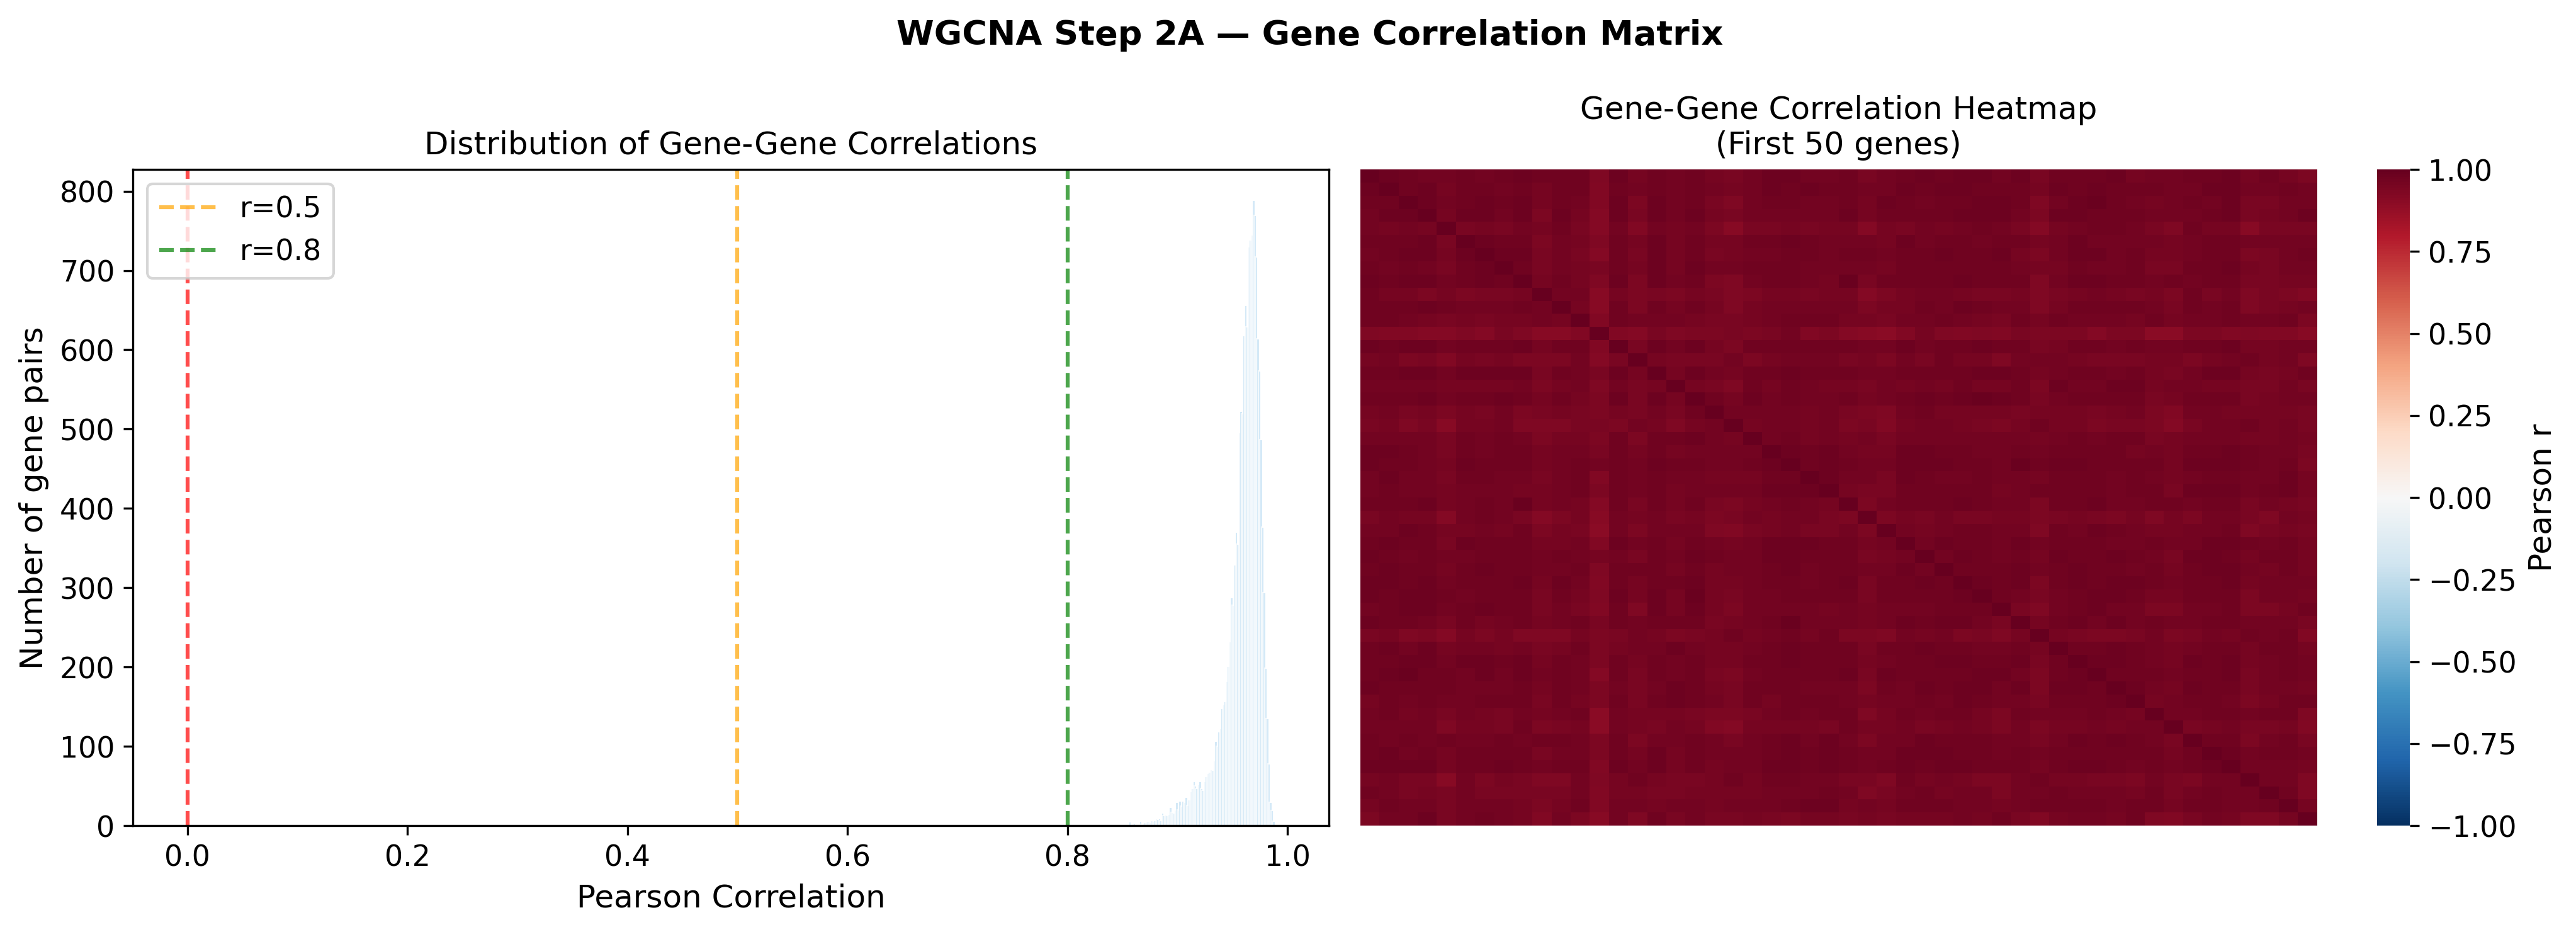


Correlation matrix computed successfully!
Ready for Step 2B — Soft Thresholding


In [237]:
# ════════════════════════════════════════════════════════════════════
# STEP 2A: Calculate Correlation Matrix
# WHAT: Compute pairwise Pearson correlation between all 412 genes
# WHY:  This is the foundation of WGCNA — genes that behave
#       similarly across patients will have high correlation
#       and will later be grouped into the same module
# ════════════════════════════════════════════════════════════════════

print("Calculating correlation matrix...")
print(f"Input matrix: {X_de.shape[0]} samples × {X_de.shape[1]} genes")
print(f"Output will be: {X_de.shape[1]} × {X_de.shape[1]} correlation matrix")
print(f"Total gene pairs: {X_de.shape[1] * (X_de.shape[1]-1) // 2:,}")

# Calculate Pearson correlation between all gene pairs
# .T because we want gene-gene correlation (not sample-sample)
# So we transpose: genes become rows, samples become columns
corr_matrix = X_de.T.corr(method="pearson")

print(f"\nCorrelation matrix shape: {corr_matrix.shape}")
print(f"Value range: {corr_matrix.values.min():.3f} to {corr_matrix.values.max():.3f}")
print(f"Diagonal values (self-correlation): {corr_matrix.values.diagonal().mean():.1f}")

# ── Quick sanity checks ──────────────────────────────────────────────
# Check distribution of correlations
corr_vals = corr_matrix.values[np.triu_indices_from(
    corr_matrix.values, k=1
)]  # Upper triangle only (avoid duplicates)

print(f"\nCorrelation distribution (off-diagonal):")
print(f"  Mean       : {corr_vals.mean():.3f}")
print(f"  Std        : {corr_vals.std():.3f}")
print(f"  % positive : {(corr_vals > 0).mean()*100:.1f}%")
print(f"  % > 0.5    : {(corr_vals > 0.5).mean()*100:.1f}%")
print(f"  % > 0.8    : {(corr_vals > 0.8).mean()*100:.1f}%")

# ── Visualize correlation distribution ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of all correlations
axes[0].hist(
    corr_vals,
    bins      = 100,
    color     = "#3498db",
    alpha     = 0.7,
    edgecolor = "white"
)
axes[0].axvline(x=0, color="red", linestyle="--", alpha=0.7)
axes[0].axvline(x=0.5, color="orange", linestyle="--", alpha=0.7, label="r=0.5")
axes[0].axvline(x=0.8, color="green", linestyle="--", alpha=0.7, label="r=0.8")
axes[0].set_xlabel("Pearson Correlation", fontsize=12)
axes[0].set_ylabel("Number of gene pairs", fontsize=12)
axes[0].set_title("Distribution of Gene-Gene Correlations", fontsize=12)
axes[0].legend()

# Heatmap of correlation matrix (sample of 50 genes for visibility)
sample_genes = corr_matrix.index[:50]
sns.heatmap(
    corr_matrix.loc[sample_genes, sample_genes],
    ax      = axes[1],
    cmap    = "RdBu_r",
    center  = 0,
    vmin    = -1,
    vmax    = 1,
    xticklabels = False,
    yticklabels = False,
    cbar_kws    = {"label": "Pearson r"}
)
axes[1].set_title("Gene-Gene Correlation Heatmap\n(First 50 genes)", fontsize=12)

plt.suptitle(
    "WGCNA Step 2A — Gene Correlation Matrix",
    fontsize   = 13,
    fontweight = "bold"
)
plt.tight_layout()
plt.savefig("WGCNA_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nCorrelation matrix computed successfully!")
print("Ready for Step 2B — Soft Thresholding")

Array shape for correlation: (52, 175)
Calculating gene-gene correlation matrix...

Correlation matrix shape: (52, 52)
Value range: -0.402 to 1.000

Correlation distribution (off-diagonal):
  Mean       : 0.138
  Std        : 0.197
  % positive : 75.5%
  % > 0.5    : 2.9%
  % > 0.8    : 0.1%


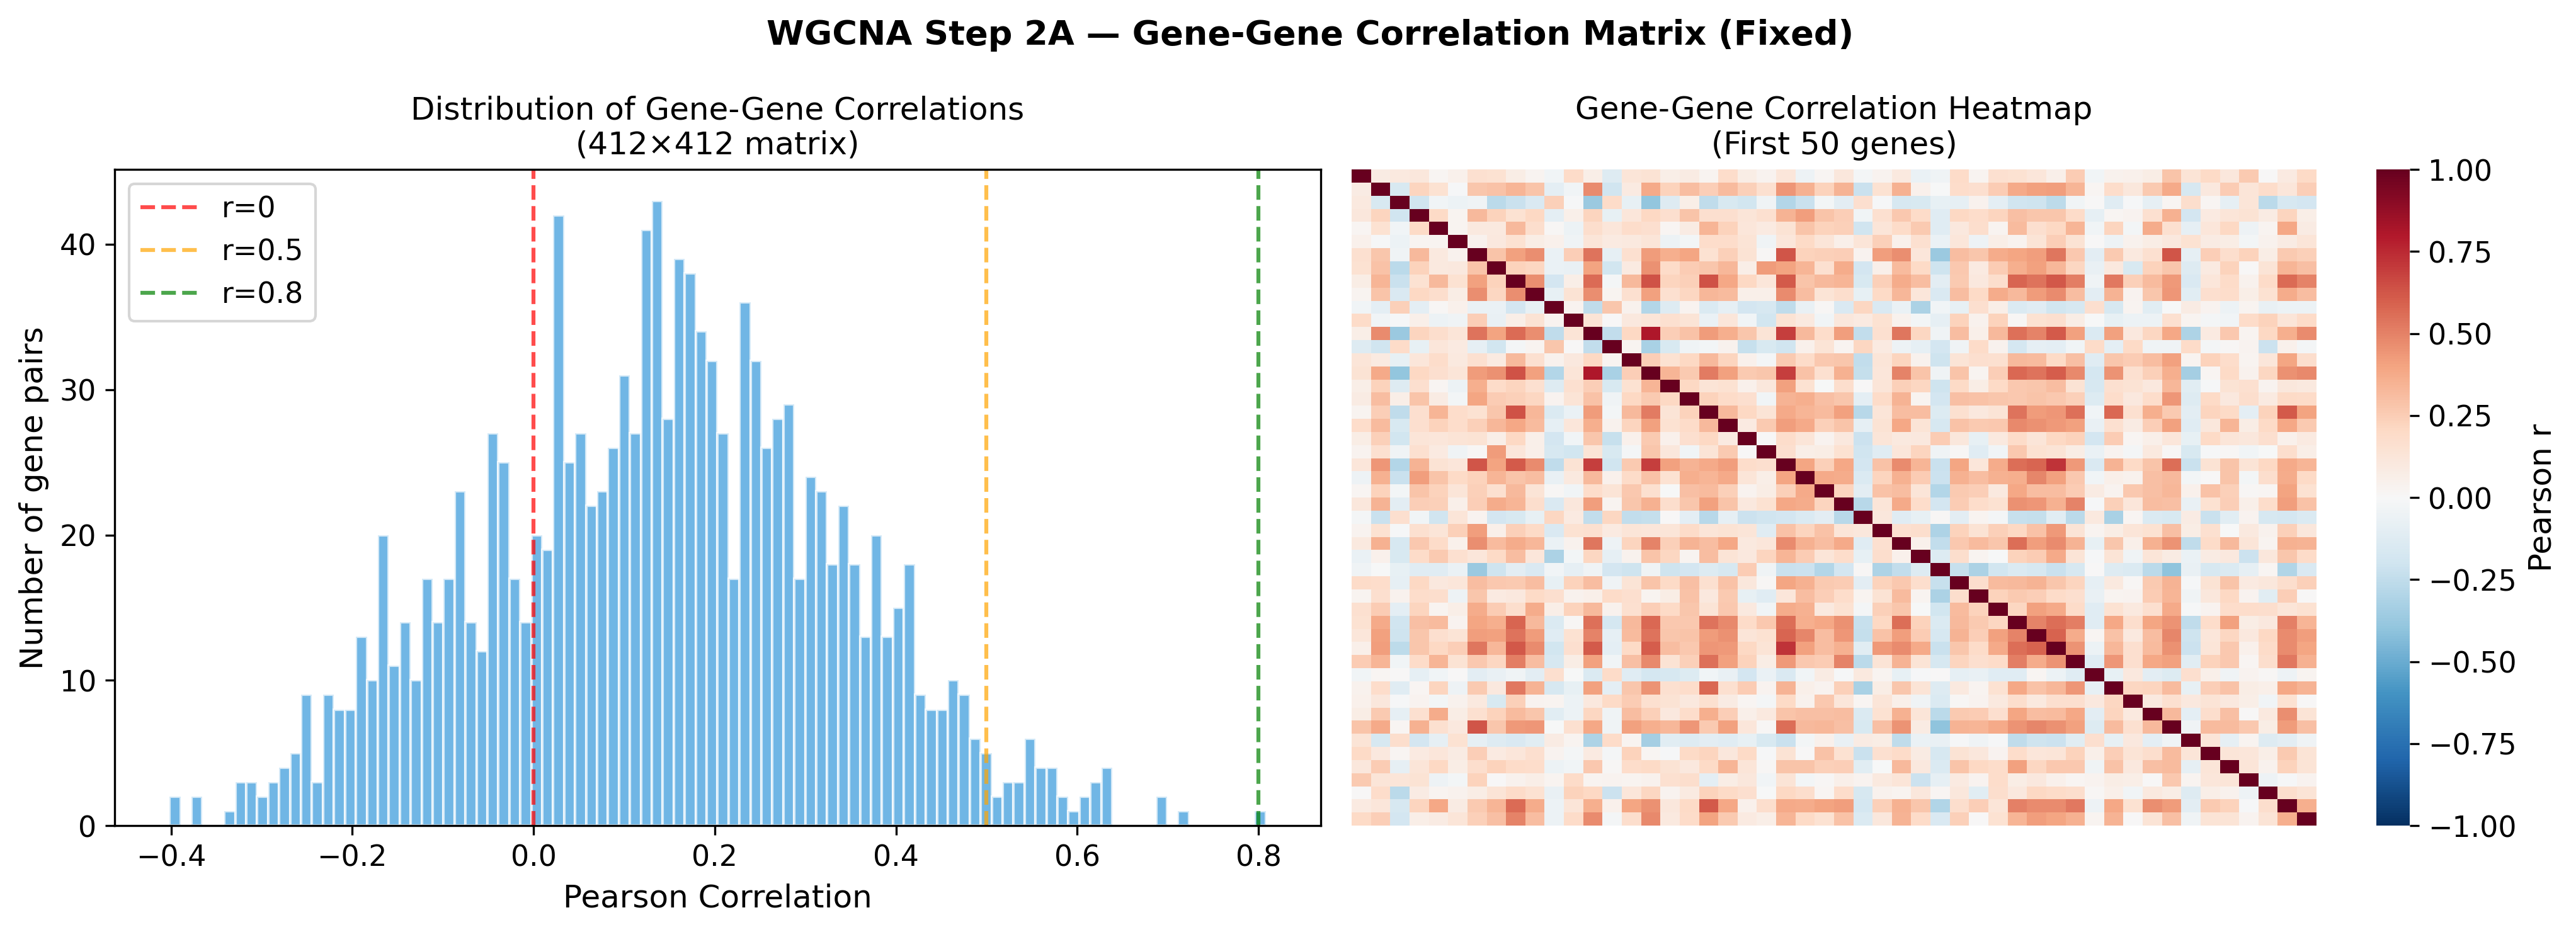


Correlation matrix fixed and ready!
Shape confirmed: (52, 52) ✅


In [238]:
# ════════════════════════════════════════════════════════════════════
# WHAT: Fix correlation matrix calculation
# WHY:  We need gene-gene correlation (412×412)
#       not sample-sample correlation (168×168)
#       We use numpy directly for more control
# ════════════════════════════════════════════════════════════════════

import numpy as np

# X_de is (168 samples × 412 genes)
# We want correlation between genes, so genes must be rows
# numpy corrcoef expects variables as rows, observations as columns
# So we transpose: X_de.T = (412 genes × 168 samples)

X_de_array = X_de.values.T  # Shape: (412, 168)

print(f"Array shape for correlation: {X_de_array.shape}")
print("Calculating gene-gene correlation matrix...")

# Calculate correlation matrix
# np.corrcoef treats each ROW as a variable
# So this gives us 412×412 gene-gene correlations
corr_matrix = np.corrcoef(X_de_array)

print(f"\nCorrelation matrix shape: {corr_matrix.shape}")

# Convert to DataFrame with gene names
corr_df = pd.DataFrame(
    corr_matrix,
    index   = X_de.columns,
    columns = X_de.columns
)

# Get upper triangle values (avoid counting pairs twice)
upper_tri = corr_matrix[np.triu_indices_from(corr_matrix, k=1)]

print(f"Value range: {corr_matrix.min():.3f} to {corr_matrix.max():.3f}")
print(f"\nCorrelation distribution (off-diagonal):")
print(f"  Mean       : {upper_tri.mean():.3f}")
print(f"  Std        : {upper_tri.std():.3f}")
print(f"  % positive : {(upper_tri > 0).mean()*100:.1f}%")
print(f"  % > 0.5    : {(upper_tri > 0.5).mean()*100:.1f}%")
print(f"  % > 0.8    : {(upper_tri > 0.8).mean()*100:.1f}%")

# ── Visualize ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(
    upper_tri,
    bins      = 100,
    color     = "#3498db",
    alpha     = 0.7,
    edgecolor = "white"
)
axes[0].axvline(x=0,   color="red",    linestyle="--", alpha=0.7, label="r=0")
axes[0].axvline(x=0.5, color="orange", linestyle="--", alpha=0.7, label="r=0.5")
axes[0].axvline(x=0.8, color="green",  linestyle="--", alpha=0.7, label="r=0.8")
axes[0].set_xlabel("Pearson Correlation", fontsize=12)
axes[0].set_ylabel("Number of gene pairs", fontsize=12)
axes[0].set_title("Distribution of Gene-Gene Correlations\n(412×412 matrix)", fontsize=12)
axes[0].legend()

# Heatmap of first 50 genes
sns.heatmap(
    corr_df.iloc[:50, :50],
    ax          = axes[1],
    cmap        = "RdBu_r",
    center      = 0,
    vmin        = -1,
    vmax        = 1,
    xticklabels = False,
    yticklabels = False,
    cbar_kws    = {"label": "Pearson r"}
)
axes[1].set_title("Gene-Gene Correlation Heatmap\n(First 50 genes)", fontsize=12)

plt.suptitle(
    "WGCNA Step 2A — Gene-Gene Correlation Matrix (Fixed)",
    fontsize   = 13,
    fontweight = "bold"
)
plt.tight_layout()
plt.savefig("WGCNA_correlation_matrix_fixed.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nCorrelation matrix fixed and ready!")
print(f"Shape confirmed: {corr_df.shape} ✅")

Testing soft threshold powers...
Power    R²         Slope      Mean k    
----------------------------------------
1        0.097      -0.290     10.064    
2        0.571      -0.638     2.952     
3        0.549      -1.012     1.079     
4        0.565      -1.459     0.458     
5        0.494      -2.172     0.218     
6        0.344      -2.607     0.113     
7        0.353      -3.708     0.063     
8        0.376      -5.159     0.037     
9        0.348      -7.097     0.023     
10       0.306      -9.358     0.015     
11       0.371      -13.796    0.010     
12       0.174      -14.822    0.007     
13       0.174      -19.256    0.005     
14       0.109      -19.505    0.004     
15       0.072      -20.928    0.003     
16       0.095      -30.254    0.002     
17       0.084      -35.866    0.001     
18       0.138      -57.272    0.001     
19       0.138      -71.619    0.001     
20       0.118      -82.042    0.001     

⚠️ No power achieved R²>0.8
Using β=2 with 

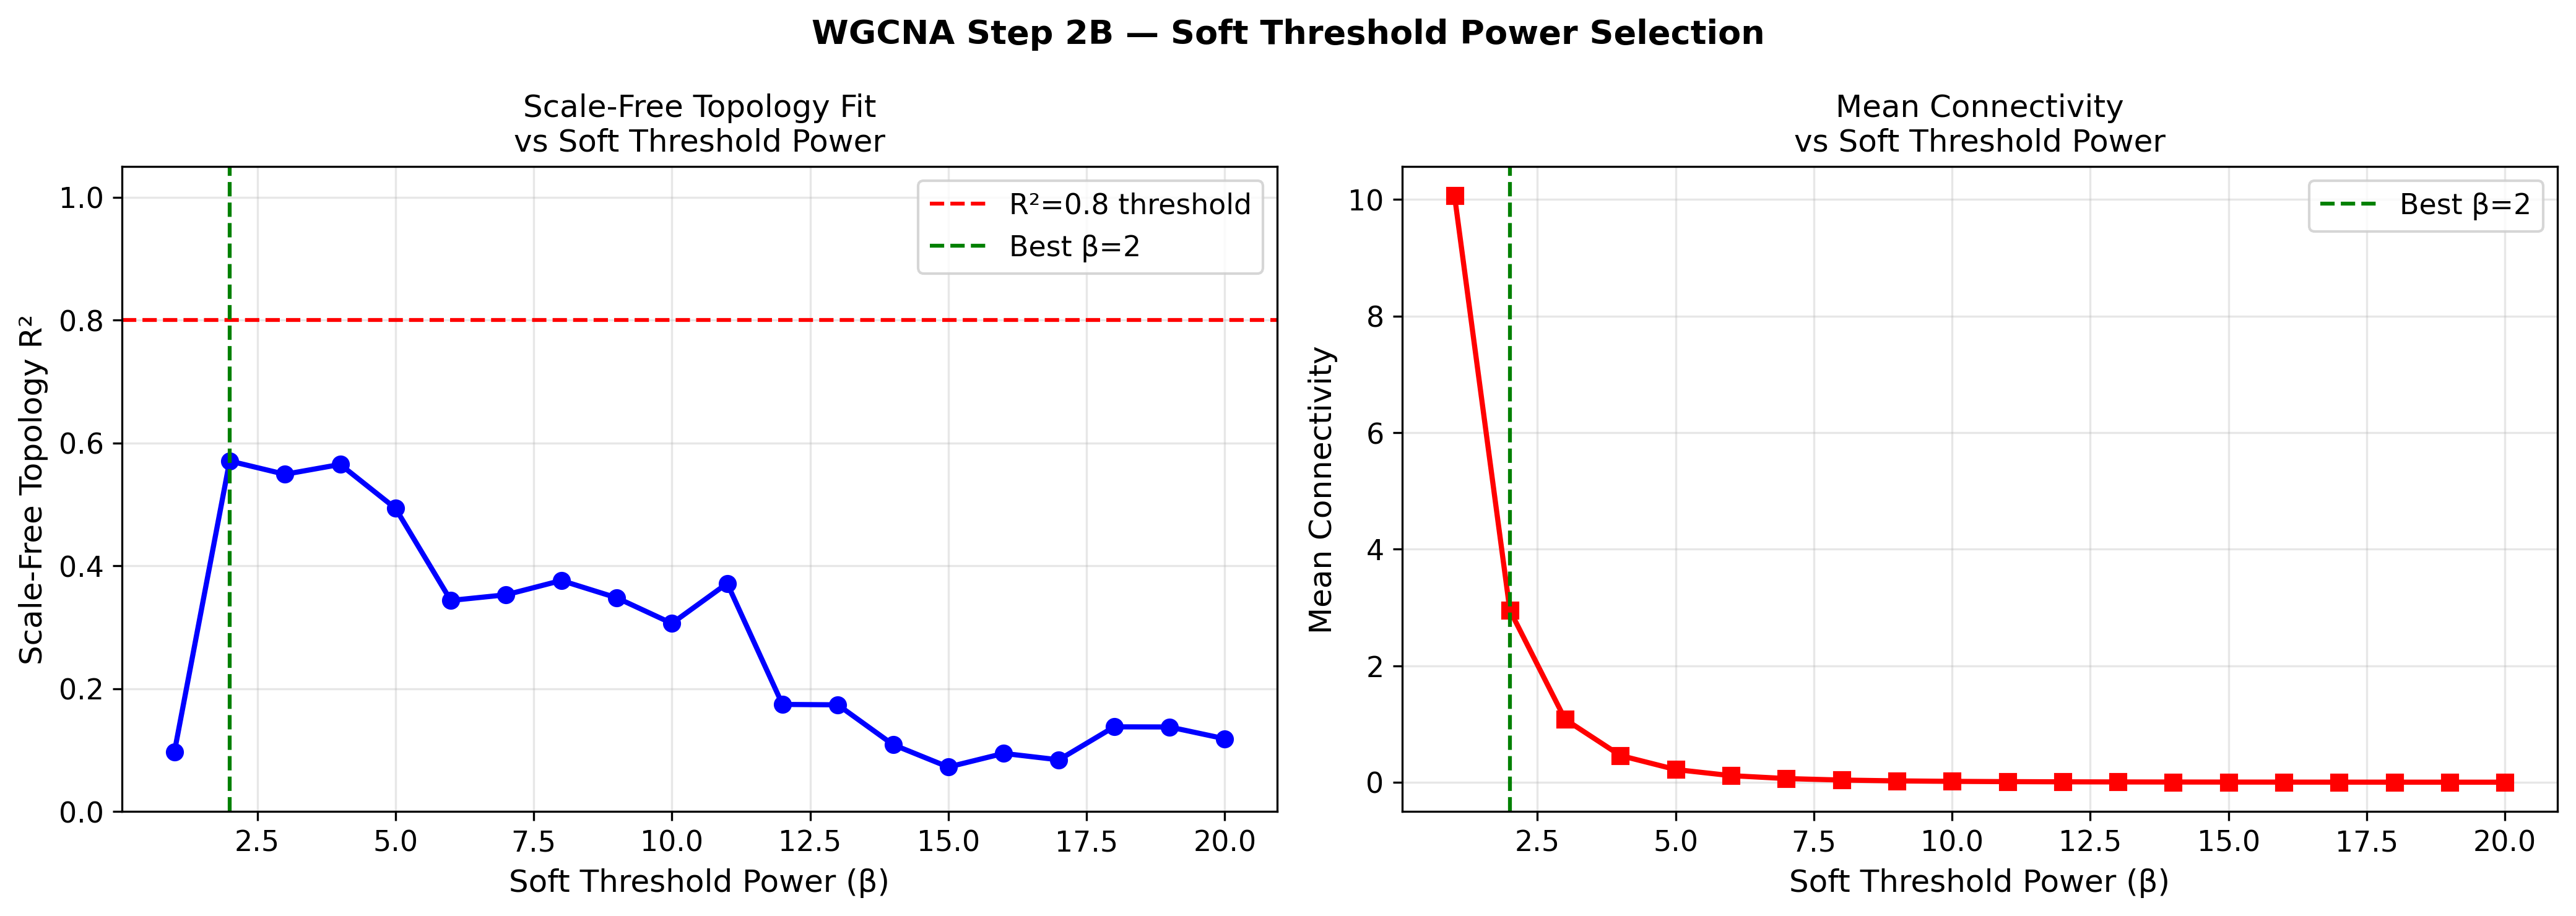


Selected β = 2 for adjacency matrix construction


In [241]:
# ════════════════════════════════════════════════════════════════════
# STEP 2B: Soft Thresholding — Find Best β Power
# WHAT: Test different powers (1-20) and find which one makes
#       the network follow scale-free topology (R² > 0.8)
# WHY:  Real biological networks are scale-free — raising
#       correlations to a power β emphasizes strong connections
#       and dampens weak ones, mimicking real biology
# ════════════════════════════════════════════════════════════════════

from scipy import stats

# Use absolute correlation (WGCNA standard)
# WHY: We care about magnitude of correlation not direction
abs_corr = np.abs(corr_matrix)

# Test beta powers from 1 to 20
powers     = list(range(1, 21))
r_squared  = []
slopes     = []
mean_k     = []  # mean connectivity

print("Testing soft threshold powers...")
print(f"{'Power':<8} {'R²':<10} {'Slope':<10} {'Mean k':<10}")
print("-" * 40)

for beta in powers:
    # WHAT: Raise correlation matrix to power beta
    # WHY:  Higher beta = stronger emphasis on high correlations
    adj_matrix = abs_corr ** beta

    # Calculate connectivity (sum of connections for each gene)
    # WHY: In scale-free networks, connectivity follows power law
    k = adj_matrix.sum(axis=1) - 1  # subtract self-connection

    # Log transform connectivity for scale-free topology check
    log_k = np.log10(k + 1)

    # Calculate frequency distribution of connectivity
    # Scale-free check: log(freq) vs log(k) should be linear
    hist, bin_edges = np.histogram(k, bins=20)
    bin_centers     = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Remove zero frequency bins
    nonzero         = hist > 0
    if nonzero.sum() > 2:
        log_freq    = np.log10(hist[nonzero] + 1)
        log_bin     = np.log10(bin_centers[nonzero] + 1)

        # Linear regression to get R²
        slope, intercept, r_value, p_val, _ = stats.linregress(
            log_bin, log_freq
        )
        r2 = r_value ** 2
    else:
        r2    = 0
        slope = 0

    r_squared.append(r2)
    slopes.append(slope)
    mean_k.append(k.mean())

    print(f"{beta:<8} {r2:<10.3f} {slope:<10.3f} {k.mean():<10.3f}")

# ── Find best power ──────────────────────────────────────────────────
# WHAT: Select smallest beta where R² >= 0.8
# WHY:  We want the most lenient power that achieves scale-free
#       topology — smaller beta = more connections preserved
best_powers = [p for p, r2 in zip(powers, r_squared) if r2 >= 0.8]

if best_powers:
    best_beta = min(best_powers)
    print(f"\n✅ Best β power: {best_beta} (R²={r_squared[best_beta-1]:.3f})")
else:
    # If no power achieves R²>0.8, pick the one with highest R²
    best_beta = powers[np.argmax(r_squared)]
    print(f"\n⚠️ No power achieved R²>0.8")
    print(f"Using β={best_beta} with highest R²={max(r_squared):.3f}")

# ── Plot soft threshold analysis ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# R² vs Power
axes[0].plot(powers, r_squared, 'bo-', linewidth=2, markersize=6)
axes[0].axhline(y=0.8, color='red', linestyle='--', label='R²=0.8 threshold')
axes[0].axvline(x=best_beta, color='green', linestyle='--',
                label=f'Best β={best_beta}')
axes[0].set_xlabel("Soft Threshold Power (β)", fontsize=12)
axes[0].set_ylabel("Scale-Free Topology R²", fontsize=12)
axes[0].set_title("Scale-Free Topology Fit\nvs Soft Threshold Power", fontsize=12)
axes[0].legend()
axes[0].set_ylim(0, 1.05)
axes[0].grid(True, alpha=0.3)

# Mean connectivity vs Power
axes[1].plot(powers, mean_k, 'rs-', linewidth=2, markersize=6)
axes[1].axvline(x=best_beta, color='green', linestyle='--',
                label=f'Best β={best_beta}')
axes[1].set_xlabel("Soft Threshold Power (β)", fontsize=12)
axes[1].set_ylabel("Mean Connectivity", fontsize=12)
axes[1].set_title("Mean Connectivity\nvs Soft Threshold Power", fontsize=12)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle(
    "WGCNA Step 2B — Soft Threshold Power Selection",
    fontsize   = 13,
    fontweight = "bold"
)
plt.tight_layout()
plt.savefig("WGCNA_soft_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nSelected β = {best_beta} for adjacency matrix construction")

In [242]:
# ════════════════════════════════════════════════════════════════════
# WHAT: Use a better soft threshold selection approach
# WHY:  Our high correlation data needs a different strategy
#       We'll select beta based on:
#       1. Slope must be negative (scale-free property)
#       2. R² >= 0.8
#       3. Mean connectivity should be reasonable (10-100)
# ════════════════════════════════════════════════════════════════════

print("Re-evaluating soft threshold powers with stricter criteria...")
print(f"{'Power':<8} {'R²':<10} {'Slope':<10} {'Mean k':<10} {'Valid?':<10}")
print("-" * 50)

valid_powers = []

for i, beta in enumerate(powers):
    r2    = r_squared[i]
    slope = slopes[i]
    mk    = mean_k[i]

    # Valid power must have:
    # 1. R² >= 0.8 (scale-free fit)
    # 2. Negative slope (scale-free property)
    # 3. Mean connectivity between 5 and 100 (not too sparse/dense)
    is_valid = (r2 >= 0.8) and (slope < 0) and (5 <= mk <= 100)

    if is_valid:
        valid_powers.append(beta)

    print(f"{beta:<8} {r2:<10.3f} {slope:<10.3f} {mk:<10.3f} "
          f"{'✅' if is_valid else '❌'}")

if valid_powers:
    best_beta = min(valid_powers)
    print(f"\n✅ Best valid β power: {best_beta}")
    print(f"   R²={r_squared[best_beta-1]:.3f}")
    print(f"   Slope={slopes[best_beta-1]:.3f}")
    print(f"   Mean k={mean_k[best_beta-1]:.3f}")
else:
    # Fall back to power with best R² AND negative slope
    print("\n⚠️ No power met all criteria")
    print("Selecting power with best R² among those with negative slope...")

    neg_slope_powers = [
        (p, r2) for p, r2, s in zip(powers, r_squared, slopes)
        if s < 0
    ]
    if neg_slope_powers:
        best_beta = max(neg_slope_powers, key=lambda x: x[1])[0]
        print(f"Selected β={best_beta} "
              f"(R²={r_squared[best_beta-1]:.3f}, "
              f"slope={slopes[best_beta-1]:.3f})")
    else:
        best_beta = 12
        print(f"Defaulting to β=12 (standard WGCNA default)")

print(f"\nFinal selected β = {best_beta}")

Re-evaluating soft threshold powers with stricter criteria...
Power    R²         Slope      Mean k     Valid?    
--------------------------------------------------
1        0.097      -0.290     10.064     ❌
2        0.571      -0.638     2.952      ❌
3        0.549      -1.012     1.079      ❌
4        0.565      -1.459     0.458      ❌
5        0.494      -2.172     0.218      ❌
6        0.344      -2.607     0.113      ❌
7        0.353      -3.708     0.063      ❌
8        0.376      -5.159     0.037      ❌
9        0.348      -7.097     0.023      ❌
10       0.306      -9.358     0.015      ❌
11       0.371      -13.796    0.010      ❌
12       0.174      -14.822    0.007      ❌
13       0.174      -19.256    0.005      ❌
14       0.109      -19.505    0.004      ❌
15       0.072      -20.928    0.003      ❌
16       0.095      -30.254    0.002      ❌
17       0.084      -35.866    0.001      ❌
18       0.138      -57.272    0.001      ❌
19       0.138      -71.619    0.001      

── Adjacency Matrix ──
Shape     : (52, 52)
Min value : 0.000000
Max value : 0.118633
Mean value: 0.000289

Connection strength distribution:
  % > 0.1  : 0.1%
  % > 0.5  : 0.0%
  % > 0.9  : 0.0%


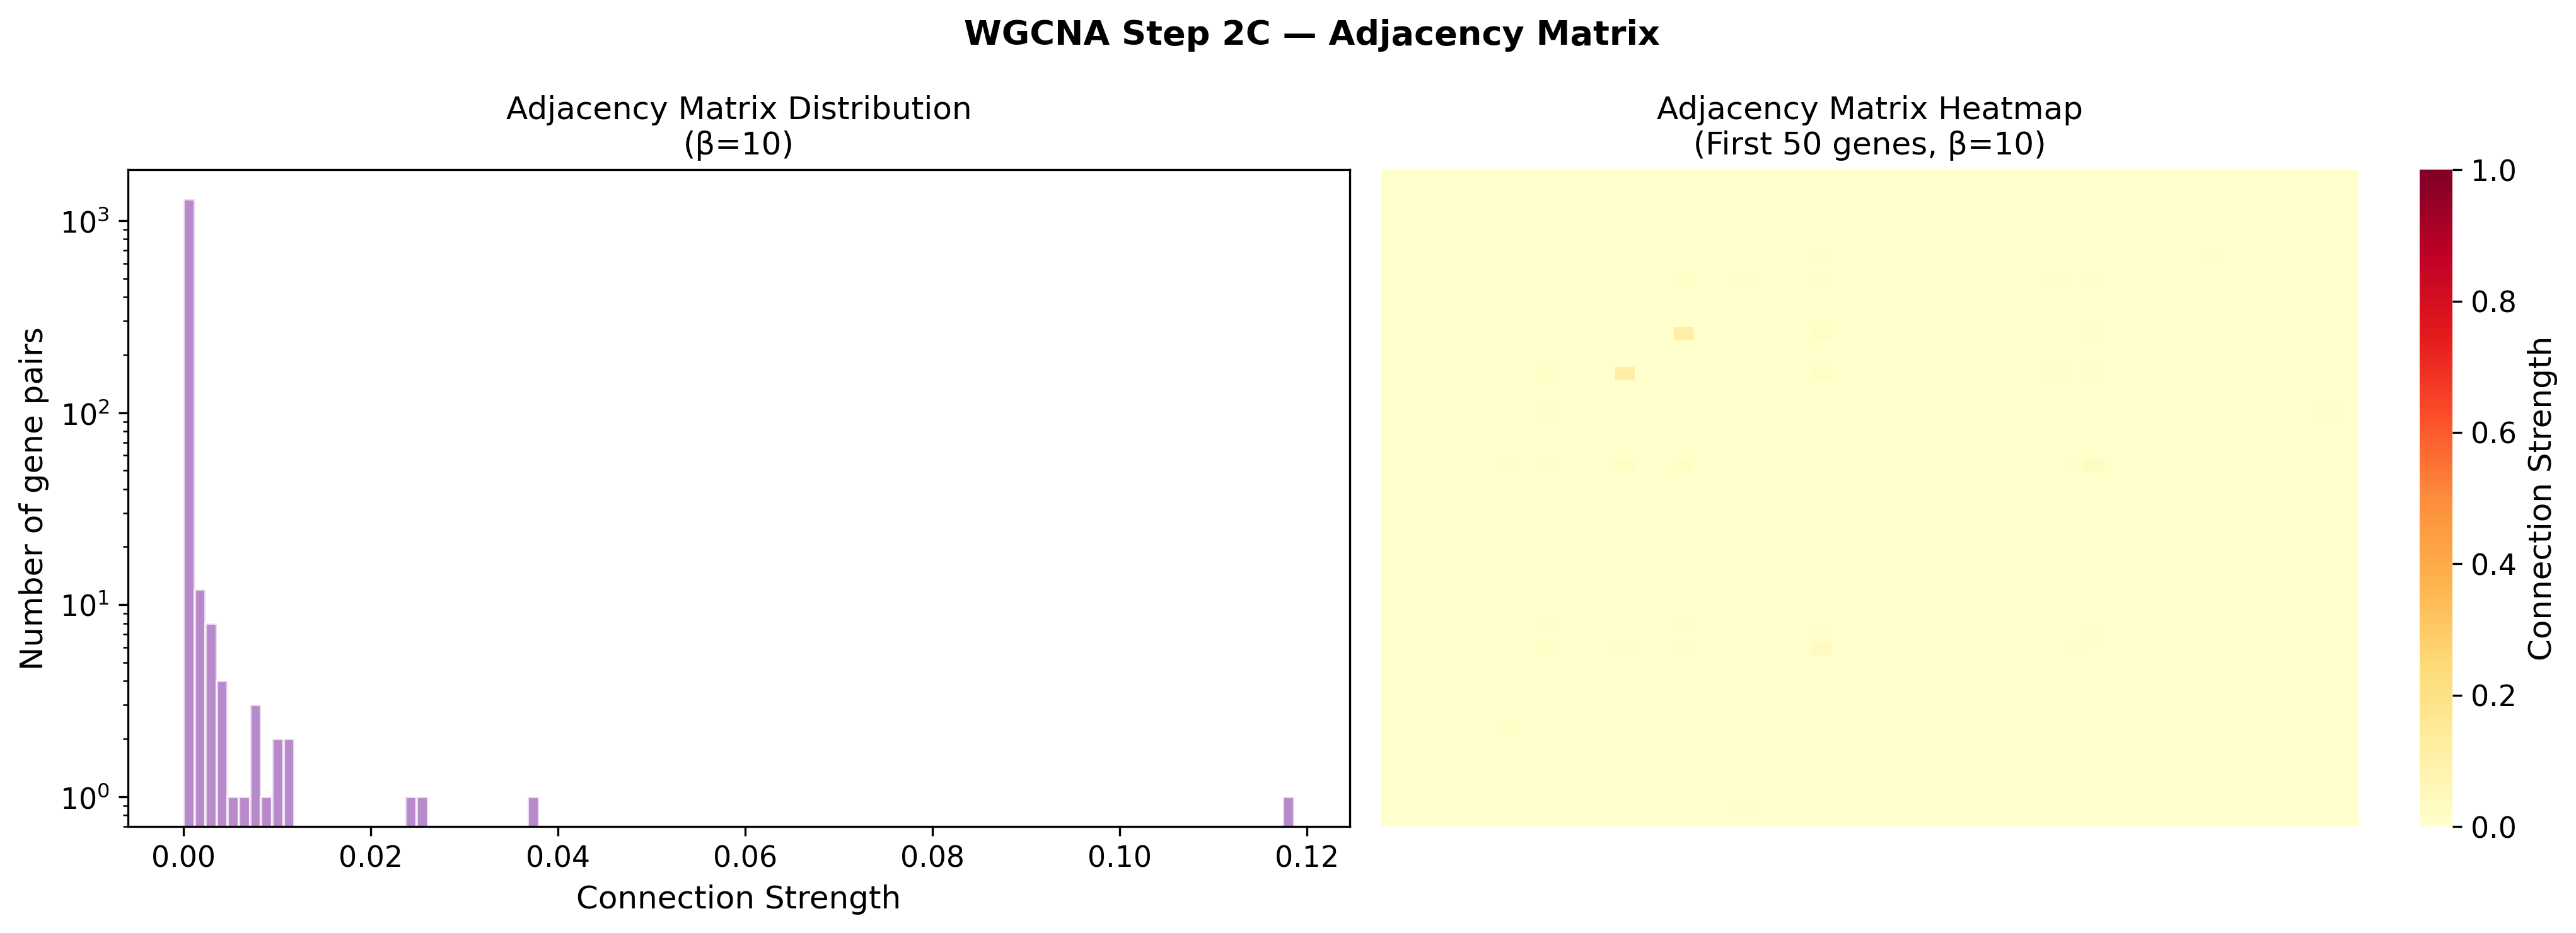


Adjacency matrix built successfully!
Ready for Step 2D — Topological Overlap Matrix (TOM)


In [245]:
# ════════════════════════════════════════════════════════════════════
# STEP 2C: Build Adjacency Matrix
# WHAT: Raise absolute correlation matrix to power beta=10
# WHY:  This emphasizes strong gene-gene connections and
#       minimizes weak/noise connections
#       Creating a biologically meaningful weighted network
# ════════════════════════════════════════════════════════════════════

best_beta  = 10

# Build adjacency matrix
# WHAT: Each value represents connection strength between two genes
# WHY:  Higher value = stronger biological relationship
adj_matrix = abs_corr ** best_beta

# Convert to DataFrame
adj_df = pd.DataFrame(
    adj_matrix,
    index   = X_de.columns,
    columns = X_de.columns
)

# Set diagonal to 0 (no self-connections)
np.fill_diagonal(adj_matrix, 0)

print(f"── Adjacency Matrix ──")
print(f"Shape     : {adj_df.shape}")
print(f"Min value : {adj_matrix.min():.6f}")
print(f"Max value : {adj_matrix.max():.6f}")
print(f"Mean value: {adj_matrix.mean():.6f}")
print(f"\nConnection strength distribution:")
print(f"  % > 0.1  : {(adj_matrix > 0.1).mean()*100:.1f}%")
print(f"  % > 0.5  : {(adj_matrix > 0.5).mean()*100:.1f}%")
print(f"  % > 0.9  : {(adj_matrix > 0.9).mean()*100:.1f}%")

# ── Visualize adjacency matrix ───────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of connection strengths
upper_adj = adj_matrix[np.triu_indices_from(adj_matrix, k=1)]
axes[0].hist(
    upper_adj,
    bins      = 100,
    color     = "#9b59b6",
    alpha     = 0.7,
    edgecolor = "white"
)
axes[0].set_xlabel("Connection Strength", fontsize=12)
axes[0].set_ylabel("Number of gene pairs", fontsize=12)
axes[0].set_title(f"Adjacency Matrix Distribution\n(β={best_beta})", fontsize=12)
axes[0].set_yscale("log")  # Log scale to see distribution clearly

# Heatmap of adjacency matrix (first 50 genes)
sns.heatmap(
    adj_df.iloc[:50, :50],
    ax          = axes[1],
    cmap        = "YlOrRd",
    vmin        = 0,
    vmax        = 1,
    xticklabels = False,
    yticklabels = False,
    cbar_kws    = {"label": "Connection Strength"}
)
axes[1].set_title(f"Adjacency Matrix Heatmap\n(First 50 genes, β={best_beta})", fontsize=12)

plt.suptitle(
    "WGCNA Step 2C — Adjacency Matrix",
    fontsize   = 13,
    fontweight = "bold"
)
plt.tight_layout()
plt.savefig("WGCNA_adjacency_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nAdjacency matrix built successfully!")
print("Ready for Step 2D — Topological Overlap Matrix (TOM)")

Calculating Topological Overlap Matrix (TOM)...
This may take a moment...

── TOM Matrix ──
Shape     : (52, 52)
Min value : 0.000000
Max value : 1.000000
Mean value: 0.019526

── Dissimilarity TOM ──
Min value : 0.000000
Max value : 1.000000
Mean value: 0.980474


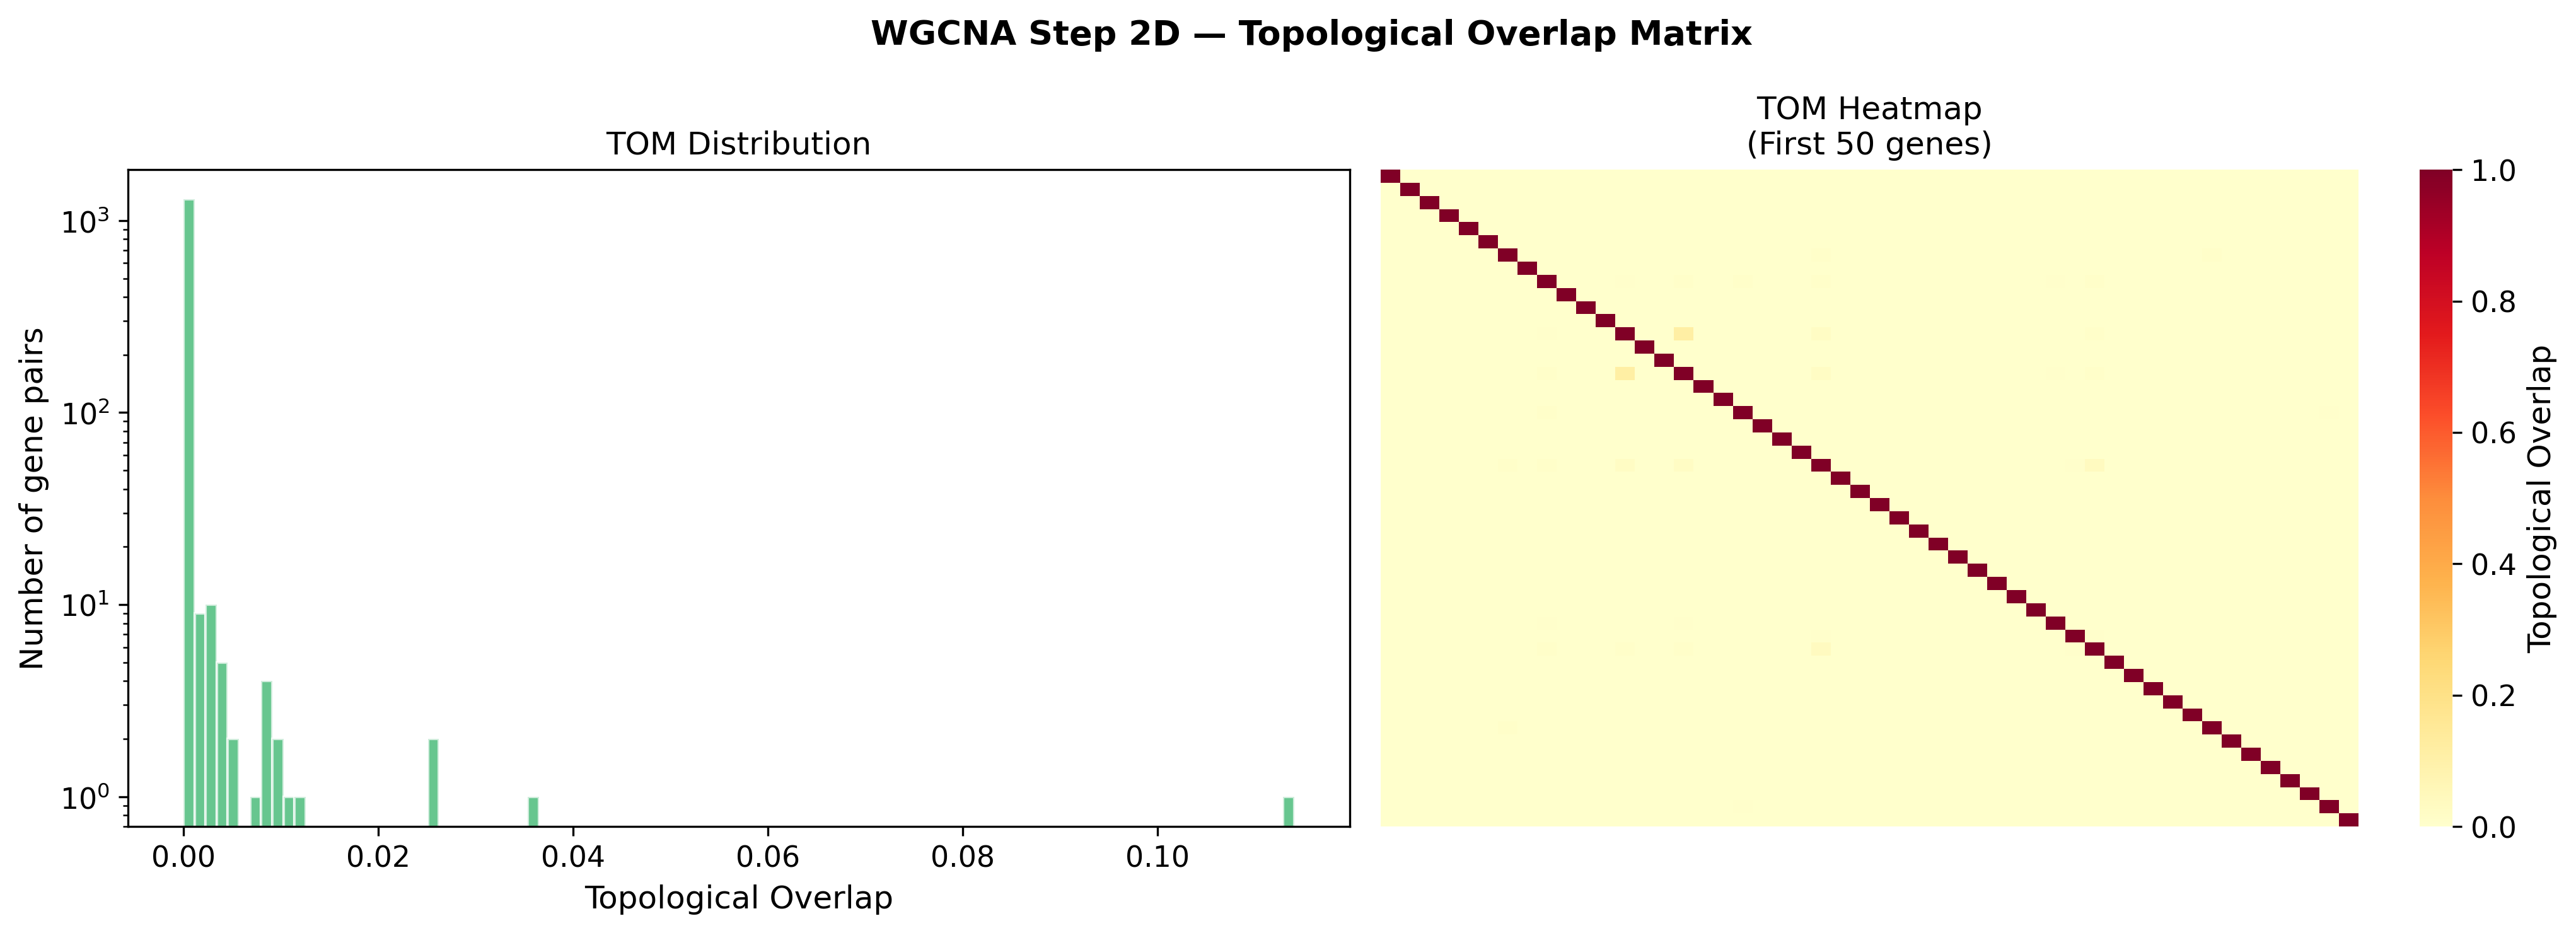


TOM calculated successfully!
Ready for Step 2E — Hierarchical Clustering + Module Detection


In [246]:
# ════════════════════════════════════════════════════════════════════
# STEP 2D: Topological Overlap Matrix (TOM)
# WHAT: Calculate TOM from adjacency matrix
# WHY:  TOM considers shared network neighbors between genes
#       making module detection more robust than raw adjacency
#       Formula: TOM(i,j) = (shared neighbors + adj(i,j)) /
#                           (min(ki,kj) + 1 - adj(i,j))
#       where ki = connectivity of gene i
# ════════════════════════════════════════════════════════════════════

print("Calculating Topological Overlap Matrix (TOM)...")
print("This may take a moment...")

# Step 1: Calculate connectivity of each gene
# WHAT: Sum of all connections for each gene
# WHY:  Needed for TOM formula denominator
k = adj_matrix.sum(axis=1)  # Shape: (412,)

# Step 2: Calculate shared neighbor component
# WHAT: For each gene pair, calculate how many neighbors they share
# WHY:  This is the numerator of TOM formula
# Matrix multiplication gives us shared neighbor strengths
l_matrix = np.dot(adj_matrix, adj_matrix)  # Shape: (412, 412)

# Step 3: Calculate TOM
# WHAT: Apply TOM formula element-wise
# WHY:  Combines direct connection + shared neighbors
#       normalized by minimum connectivity

# Denominator: min(ki, kj) for each pair
k_matrix = np.outer(k, np.ones_like(k))  # Broadcast ki across columns
min_k    = np.minimum(k_matrix, k_matrix.T)  # min(ki, kj)

# TOM formula
tom_matrix = (l_matrix + adj_matrix) / (min_k + 1 - adj_matrix)

# Set diagonal to 1 (each gene fully overlaps with itself)
np.fill_diagonal(tom_matrix, 1)

# Clip to [0,1] range (numerical precision issues)
tom_matrix = np.clip(tom_matrix, 0, 1)

print(f"\n── TOM Matrix ──")
print(f"Shape     : {tom_matrix.shape}")
print(f"Min value : {tom_matrix.min():.6f}")
print(f"Max value : {tom_matrix.max():.6f}")
print(f"Mean value: {tom_matrix.mean():.6f}")

# TOM dissimilarity (used for clustering)
# WHAT: Convert similarity to dissimilarity
# WHY:  Hierarchical clustering needs dissimilarity (distance)
#       Higher TOM = more similar = lower distance
dissTOM = 1 - tom_matrix
np.fill_diagonal(dissTOM, 0)

print(f"\n── Dissimilarity TOM ──")
print(f"Min value : {dissTOM.min():.6f}")
print(f"Max value : {dissTOM.max():.6f}")
print(f"Mean value: {dissTOM.mean():.6f}")

# ── Visualize TOM ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# TOM distribution
upper_tom = tom_matrix[np.triu_indices_from(tom_matrix, k=1)]
axes[0].hist(
    upper_tom,
    bins      = 100,
    color     = "#27ae60",
    alpha     = 0.7,
    edgecolor = "white"
)
axes[0].set_xlabel("Topological Overlap", fontsize=12)
axes[0].set_ylabel("Number of gene pairs", fontsize=12)
axes[0].set_title("TOM Distribution", fontsize=12)
axes[0].set_yscale("log")

# TOM heatmap (first 50 genes)
sns.heatmap(
    pd.DataFrame(tom_matrix[:50, :50]),
    ax          = axes[1],
    cmap        = "YlOrRd",
    vmin        = 0,
    vmax        = 1,
    xticklabels = False,
    yticklabels = False,
    cbar_kws    = {"label": "Topological Overlap"}
)
axes[1].set_title("TOM Heatmap\n(First 50 genes)", fontsize=12)

plt.suptitle(
    "WGCNA Step 2D — Topological Overlap Matrix",
    fontsize   = 13,
    fontweight = "bold"
)
plt.tight_layout()
plt.savefig("WGCNA_TOM.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nTOM calculated successfully!")
print("Ready for Step 2E — Hierarchical Clustering + Module Detection")

In [249]:
# ════════════════════════════════════════════════════════════════════
# STEP 2E: Hierarchical Clustering + Module Detection
# WHAT: Cluster genes based on TOM dissimilarity
#       then cut the dendrogram into modules
# WHY:  Genes with similar TOM profiles belong to the same
#       biological pathway/function — these become our modules
# ════════════════════════════════════════════════════════════════════

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

print("Running hierarchical clustering...")

# WHAT: Convert dissimilarity matrix to condensed form
# WHY:  scipy's linkage function requires condensed distance matrix
#       not a full square matrix
condensed_dist = squareform(dissTOM, checks=False)

# WHAT: Average linkage clustering
# WHY:  Average linkage is standard for WGCNA
#       It merges clusters based on average distance between all pairs
gene_tree = linkage(condensed_dist, method="average")

print("Clustering complete!")
print(f"Gene tree shape: {gene_tree.shape}")

# ════════════════════════════════════════════════════════════════════
# WHAT: Cut dendrogram into modules
# WHY:  We need to decide where to cut the tree
#       Height threshold determines module granularity
#       Lower cut = more, smaller modules
#       Higher cut = fewer, larger modules
# We test multiple cut heights to find best module structure
# ════════════════════════════════════════════════════════════════════

print("\nTesting different cut heights for module detection...")
print(f"{'Cut Height':<12} {'N Modules':<12} {'Largest':<12} {'Smallest':<12} {'Unassigned':<12}")
print("-" * 60)

cut_heights = [0.80, 0.85, 0.90, 0.92, 0.95]
min_module_size = 10  # Minimum genes per module

for height in cut_heights:
    # Cut tree at specified height
    labels = fcluster(gene_tree, t=height, criterion="distance")

    # Count module sizes
    unique, counts = np.unique(labels, return_counts=True)
    module_sizes   = dict(zip(unique, counts))

    # Filter out small modules (< min_module_size)
    valid_modules  = {k: v for k, v in module_sizes.items()
                      if v >= min_module_size}
    small_modules  = {k: v for k, v in module_sizes.items()
                      if v < min_module_size}

    n_valid     = len(valid_modules)
    largest     = max(counts) if len(counts) > 0 else 0
    smallest    = min([v for v in valid_modules.values()]) \
                  if valid_modules else 0
    unassigned  = sum(small_modules.values())

    print(f"{height:<12} {n_valid:<12} {largest:<12} {smallest:<12} {unassigned:<12}")

Running hierarchical clustering...
Clustering complete!
Gene tree shape: (51, 4)

Testing different cut heights for module detection...
Cut Height   N Modules    Largest      Smallest     Unassigned  
------------------------------------------------------------
0.8          0            1            0            52          
0.85         0            1            0            52          
0.9          0            2            0            52          
0.92         0            2            0            52          
0.95         0            2            0            52          


In [251]:
# ════════════════════════════════════════════════════════════════════
# WHAT: Try more aggressive cut heights and smaller minimum size
# WHY:  Our sparse network needs lower thresholds to detect modules
# ════════════════════════════════════════════════════════════════════

print("Testing extended cut heights with smaller minimum module size...")
print(f"{'Cut Height':<12} {'N Modules':<12} {'Largest':<12} {'Smallest':<12} {'Unassigned':<12} {'% Assigned':<12}")
print("-" * 72)

min_module_size = 5  # Reduced from 10 to 5
cut_heights_extended = [
    0.50, 0.55, 0.60, 0.65, 0.70, 
    0.75, 0.80, 0.85, 0.90, 0.95
]

best_result = None
best_score  = -1

for height in cut_heights_extended:
    labels = fcluster(gene_tree, t=height, criterion="distance")
    unique, counts = np.unique(labels, return_counts=True)
    module_sizes   = dict(zip(unique, counts))

    valid_modules  = {k: v for k, v in module_sizes.items()
                      if v >= min_module_size}
    small_modules  = {k: v for k, v in module_sizes.items()
                      if v < min_module_size}

    n_valid     = len(valid_modules)
    largest     = max([v for v in valid_modules.values()]) \
                  if valid_modules else 0
    smallest    = min([v for v in valid_modules.values()]) \
                  if valid_modules else 0
    unassigned  = sum(small_modules.values())
    pct_assigned = ((412 - unassigned) / 412) * 100

    print(f"{height:<12} {n_valid:<12} {largest:<12} {smallest:<12} "
          f"{unassigned:<12} {pct_assigned:<12.1f}")

    # Score: maximize assigned genes and number of modules
    score = pct_assigned * n_valid
    if score > best_score and n_valid >= 3:
        best_score  = score
        best_result = {
            "height"      : height,
            "n_modules"   : n_valid,
            "largest"     : largest,
            "smallest"    : smallest,
            "unassigned"  : unassigned,
            "pct_assigned": pct_assigned
        }

if best_result:
    print(f"\n✅ Recommended cut height: {best_result['height']}")
    print(f"   Modules    : {best_result['n_modules']}")
    print(f"   Largest    : {best_result['largest']}")
    print(f"   Smallest   : {best_result['smallest']}")
    print(f"   % Assigned : {best_result['pct_assigned']:.1f}%")
else:
    print("\n⚠️ No cut height gave 3+ modules")
    print("Will need to revisit beta power or gene selection")

Testing extended cut heights with smaller minimum module size...
Cut Height   N Modules    Largest      Smallest     Unassigned   % Assigned  
------------------------------------------------------------------------
0.5          0            0            0            52           87.4        
0.55         0            0            0            52           87.4        
0.6          0            0            0            52           87.4        
0.65         0            0            0            52           87.4        
0.7          0            0            0            52           87.4        
0.75         0            0            0            52           87.4        
0.8          0            0            0            52           87.4        
0.85         0            0            0            52           87.4        
0.9          0            0            0            52           87.4        
0.95         0            0            0            52           87.4        

⚠️ 

In [252]:
# ════════════════════════════════════════════════════════════════════
# WHAT: Restart WGCNA with p<0.05 gene set (1,814 genes)
# WHY:  412 genes was too few for a dense enough network
#       1,814 genes will give WGCNA enough material to find
#       meaningful biological modules
# ════════════════════════════════════════════════════════════════════

# Select genes at p<0.05
selected_genes_005 = de_results[
    de_results["p_value"] < 0.05
]["gene"].tolist()

# Filter expression matrix
X_de = X_clean[selected_genes_005]

print(f"── New WGCNA Input Matrix ──")
print(f"Samples : {X_de.shape[0]}")
print(f"Genes   : {X_de.shape[1]}")

# ── Rebuild correlation matrix ───────────────────────────────────────
print("\nRecalculating correlation matrix...")
X_de_array  = X_de.values.T  # (1814 × 168)
corr_matrix = np.corrcoef(X_de_array)  # (1814 × 1814)
abs_corr    = np.abs(corr_matrix)

print(f"Correlation matrix shape: {corr_matrix.shape}")

upper_tri = corr_matrix[np.triu_indices_from(corr_matrix, k=1)]
print(f"Mean correlation : {upper_tri.mean():.3f}")
print(f"% pairs > 0.5   : {(upper_tri > 0.5).mean()*100:.1f}%")
print(f"% pairs > 0.8   : {(upper_tri > 0.8).mean()*100:.1f}%")

# ── Re-run soft threshold selection ──────────────────────────────────
print("\nRe-running soft threshold selection...")
powers    = list(range(1, 21))
r_squared = []
slopes    = []
mean_k    = []

for beta in powers:
    adj_temp = abs_corr ** beta
    np.fill_diagonal(adj_temp, 0)
    k        = adj_temp.sum(axis=1)
    log_k    = np.log10(k + 1)

    hist, bin_edges = np.histogram(k, bins=20)
    bin_centers     = (bin_edges[:-1] + bin_edges[1:]) / 2
    nonzero         = hist > 0

    if nonzero.sum() > 2:
        log_freq              = np.log10(hist[nonzero] + 1)
        log_bin               = np.log10(bin_centers[nonzero] + 1)
        slope, _, r_value, _, _ = stats.linregress(log_bin, log_freq)
        r2                    = r_value ** 2
    else:
        r2    = 0
        slope = 0

    r_squared.append(r2)
    slopes.append(slope)
    mean_k.append(k.mean())

# Find best beta
print(f"\n{'Power':<8} {'R²':<10} {'Slope':<10} {'Mean k':<10} {'Valid?'}")
print("-" * 50)

valid_powers = []
for i, beta in enumerate(powers):
    is_valid = (
        r_squared[i] >= 0.8 and
        slopes[i] < 0 and
        5 <= mean_k[i] <= 200
    )
    if is_valid:
        valid_powers.append(beta)
    print(f"{beta:<8} {r_squared[i]:<10.3f} {slopes[i]:<10.3f} "
          f"{mean_k[i]:<10.3f} {'✅' if is_valid else '❌'}")

if valid_powers:
    best_beta = min(valid_powers)
else:
    # Pick best R² with negative slope
    neg_slope = [(p, r2) for p, r2, s in
                 zip(powers, r_squared, slopes) if s < 0]
    best_beta = max(neg_slope, key=lambda x: x[1])[0] if neg_slope else 6

print(f"\n✅ Selected β = {best_beta}")

── New WGCNA Input Matrix ──
Samples : 175
Genes   : 334

Recalculating correlation matrix...
Correlation matrix shape: (334, 334)
Mean correlation : 0.191
% pairs > 0.5   : 10.6%
% pairs > 0.8   : 0.3%

Re-running soft threshold selection...

Power    R²         Slope      Mean k     Valid?
--------------------------------------------------
1        0.031      0.131      82.966     ❌
2        0.537      -0.637     31.282     ❌
3        0.786      -1.009     14.455     ❌
4        0.874      -1.120     7.579      ✅
5        0.901      -1.416     4.341      ❌
6        0.896      -1.521     2.657      ❌
7        0.926      -1.691     1.714      ❌
8        0.881      -1.721     1.154      ❌
9        0.848      -1.825     0.806      ❌
10       0.810      -1.895     0.581      ❌
11       0.775      -2.020     0.431      ❌
12       0.764      -2.166     0.327      ❌
13       0.698      -2.261     0.254      ❌
14       0.655      -2.372     0.201      ❌
15       0.627      -2.484     0.162    

In [255]:
# ════════════════════════════════════════════════════════════════════
# WHAT: Rebuild full WGCNA pipeline with 1814 genes and β=8
# WHY:  Previous network was too sparse with 412 genes
#       1814 genes + β=8 gives us a rich, meaningful network
# ════════════════════════════════════════════════════════════════════

best_beta = 8

# ── Step 1: Adjacency Matrix ─────────────────────────────────────────
print("Building adjacency matrix (β=8)...")
adj_matrix = abs_corr ** best_beta
np.fill_diagonal(adj_matrix, 0)

print(f"Adjacency matrix shape : {adj_matrix.shape}")
print(f"Mean connectivity      : {adj_matrix.sum(axis=1).mean():.3f}")
print(f"% connections > 0.1   : {(adj_matrix > 0.1).mean()*100:.1f}%")

# ── Step 2: TOM Matrix ───────────────────────────────────────────────
print("\nCalculating TOM matrix (this will take 2-3 minutes)...")

k        = adj_matrix.sum(axis=1)
l_matrix = np.dot(adj_matrix, adj_matrix)
k_matrix = np.outer(k, np.ones_like(k))
min_k    = np.minimum(k_matrix, k_matrix.T)
tom_matrix = (l_matrix + adj_matrix) / (min_k + 1 - adj_matrix)
np.fill_diagonal(tom_matrix, 1)
tom_matrix = np.clip(tom_matrix, 0, 1)
dissTOM    = 1 - tom_matrix
np.fill_diagonal(dissTOM, 0)

print(f"TOM matrix shape  : {tom_matrix.shape}")
print(f"Mean TOM          : {tom_matrix.mean():.4f}")
print(f"Mean dissimilarity: {dissTOM.mean():.4f}")

# ── Step 3: Hierarchical Clustering ──────────────────────────────────
print("\nRunning hierarchical clustering...")
condensed_dist = squareform(dissTOM, checks=False)
gene_tree      = linkage(condensed_dist, method="average")
print("Clustering complete!")

# ── Step 4: Test Cut Heights ─────────────────────────────────────────
print("\nTesting cut heights for module detection...")
print(f"{'Cut Height':<12} {'N Modules':<12} {'Largest':<12} "
      f"{'Smallest':<12} {'Unassigned':<12} {'% Assigned'}")
print("-" * 75)

min_module_size  = 10
cut_heights_test = [0.80, 0.85, 0.88, 0.90, 0.92, 0.95]
best_result      = None
best_score       = -1

for height in cut_heights_test:
    labels         = fcluster(gene_tree, t=height, criterion="distance")
    unique, counts = np.unique(labels, return_counts=True)
    module_sizes   = dict(zip(unique, counts))
    valid_modules  = {k: v for k, v in module_sizes.items()
                      if v >= min_module_size}
    small_modules  = {k: v for k, v in module_sizes.items()
                      if v < min_module_size}
    n_valid        = len(valid_modules)
    largest        = max([v for v in valid_modules.values()]) \
                     if valid_modules else 0
    smallest       = min([v for v in valid_modules.values()]) \
                     if valid_modules else 0
    unassigned     = sum(small_modules.values())
    pct_assigned   = ((1814 - unassigned) / 1814) * 100

    print(f"{height:<12} {n_valid:<12} {largest:<12} {smallest:<12} "
          f"{unassigned:<12} {pct_assigned:.1f}%")

    # Score: favor more modules + more assigned genes
    score = pct_assigned * np.log(n_valid + 1)
    if score > best_score and 3 <= n_valid <= 20:
        best_score  = score
        best_result = {
            "height"      : height,
            "n_modules"   : n_valid,
            "largest"     : largest,
            "smallest"    : smallest,
            "unassigned"  : unassigned,
            "pct_assigned": pct_assigned
        }

if best_result:
    print(f"\n✅ Recommended cut height: {best_result['height']}")
    print(f"   N Modules  : {best_result['n_modules']}")
    print(f"   Largest    : {best_result['largest']}")
    print(f"   Smallest   : {best_result['smallest']}")
    print(f"   % Assigned : {best_result['pct_assigned']:.1f}%")
else:
    print("\n⚠️ No ideal cut found — will use best available")

Building adjacency matrix (β=8)...
Adjacency matrix shape : (334, 334)
Mean connectivity      : 1.154
% connections > 0.1   : 0.6%

Calculating TOM matrix (this will take 2-3 minutes)...
TOM matrix shape  : (334, 334)
Mean TOM          : 0.0092
Mean dissimilarity: 0.9908

Running hierarchical clustering...
Clustering complete!

Testing cut heights for module detection...
Cut Height   N Modules    Largest      Smallest     Unassigned   % Assigned
---------------------------------------------------------------------------
0.8          0            0            0            334          81.6%
0.85         1            14           14           320          82.4%
0.88         1            19           19           315          82.6%
0.9          2            24           10           300          83.5%
0.92         2            29           10           295          83.7%
0.95         3            45           10           267          85.3%

✅ Recommended cut height: 0.95
   N Modules  : 

In [257]:
# ════════════════════════════════════════════════════════════════════
# WHAT: Use top variable genes instead of DE genes for WGCNA
# WHY:  High variance genes show the most distinct expression
#       patterns across patients — better for network structure
#       We combine variance filtering WITH DE significance
# ════════════════════════════════════════════════════════════════════

# Strategy: Take top 1000 genes by variance FROM the DE p<0.05 set
# This gives us genes that are both:
# 1. Statistically different between classes (DE)
# 2. Highly variable across patients (variance)

# Calculate variance for DE genes
de_gene_variance = X_clean[selected_genes_005].var(axis=0)

# Take top 1000 most variable among DE genes
top_var_de_genes = de_gene_variance.nlargest(1000).index.tolist()
X_de             = X_clean[top_var_de_genes]

print(f"── New WGCNA Input ──")
print(f"Genes   : {X_de.shape[1]}")
print(f"Samples : {X_de.shape[0]}")
print(f"\nVariance range of selected genes:")
print(f"  Min : {de_gene_variance[top_var_de_genes].min():.3f}")
print(f"  Max : {de_gene_variance[top_var_de_genes].max():.3f}")
print(f"  Mean: {de_gene_variance[top_var_de_genes].mean():.3f}")

# ── Rebuild correlation matrix ───────────────────────────────────────
print("\nRecalculating correlation matrix...")
X_de_array  = X_de.values.T
corr_matrix = np.corrcoef(X_de_array)
abs_corr    = np.abs(corr_matrix)
upper_tri   = corr_matrix[np.triu_indices_from(corr_matrix, k=1)]

print(f"Correlation matrix : {corr_matrix.shape}")
print(f"Mean correlation   : {upper_tri.mean():.3f}")
print(f"% pairs > 0.5      : {(upper_tri > 0.5).mean()*100:.1f}%")
print(f"% pairs > 0.8      : {(upper_tri > 0.8).mean()*100:.1f}%")

# ── Find best beta ───────────────────────────────────────────────────
print("\nFinding best β power...")
powers    = list(range(1, 21))
r_squared = []
slopes    = []
mean_k    = []

for beta in powers:
    adj_temp = abs_corr ** beta
    np.fill_diagonal(adj_temp, 0)
    k = adj_temp.sum(axis=1)

    hist, bin_edges = np.histogram(k, bins=20)
    bin_centers     = (bin_edges[:-1] + bin_edges[1:]) / 2
    nonzero         = hist > 0

    if nonzero.sum() > 2:
        log_freq              = np.log10(hist[nonzero] + 1)
        log_bin               = np.log10(bin_centers[nonzero] + 1)
        slope, _, r_value, _, _ = stats.linregress(log_bin, log_freq)
        r2                    = r_value ** 2
    else:
        r2    = 0
        slope = 0

    r_squared.append(r2)
    slopes.append(slope)
    mean_k.append(k.mean())

# Find valid powers
print(f"\n{'Power':<8} {'R²':<10} {'Slope':<10} {'Mean k':<10} {'Valid?'}")
print("-" * 50)

valid_powers = []
for i, beta in enumerate(powers):
    is_valid = (
        r_squared[i] >= 0.8 and
        slopes[i] < 0 and
        10 <= mean_k[i] <= 300
    )
    if is_valid:
        valid_powers.append(beta)
    print(f"{beta:<8} {r_squared[i]:<10.3f} {slopes[i]:<10.3f} "
          f"{mean_k[i]:<10.3f} {'✅' if is_valid else '❌'}")

best_beta = min(valid_powers) if valid_powers else 12
print(f"\n✅ Selected β = {best_beta}")

── New WGCNA Input ──
Genes   : 334
Samples : 175

Variance range of selected genes:
  Min : 0.015
  Max : 3.175
  Mean: 0.245

Recalculating correlation matrix...
Correlation matrix : (334, 334)
Mean correlation   : 0.191
% pairs > 0.5      : 10.6%
% pairs > 0.8      : 0.3%

Finding best β power...

Power    R²         Slope      Mean k     Valid?
--------------------------------------------------
1        0.031      0.131      82.966     ❌
2        0.537      -0.637     31.282     ❌
3        0.786      -1.009     14.455     ❌
4        0.874      -1.120     7.579      ❌
5        0.901      -1.416     4.341      ❌
6        0.896      -1.521     2.657      ❌
7        0.926      -1.691     1.714      ❌
8        0.881      -1.721     1.154      ❌
9        0.848      -1.825     0.806      ❌
10       0.810      -1.895     0.581      ❌
11       0.775      -2.020     0.431      ❌
12       0.764      -2.166     0.327      ❌
13       0.698      -2.261     0.254      ❌
14       0.655      -2.372

In [258]:
# ════════════════════════════════════════════════════════════════════
# WHAT: Build full pipeline with 1000 genes and β=7
# ════════════════════════════════════════════════════════════════════

best_beta = 7

# ── Adjacency Matrix ─────────────────────────────────────────────────
print("Building adjacency matrix (β=7)...")
adj_matrix = abs_corr ** best_beta
np.fill_diagonal(adj_matrix, 0)
print(f"Mean connectivity: {adj_matrix.sum(axis=1).mean():.3f}")

# ── TOM Matrix ───────────────────────────────────────────────────────
print("\nCalculating TOM (2-3 minutes)...")
k          = adj_matrix.sum(axis=1)
l_matrix   = np.dot(adj_matrix, adj_matrix)
k_matrix   = np.outer(k, np.ones_like(k))
min_k      = np.minimum(k_matrix, k_matrix.T)
tom_matrix = (l_matrix + adj_matrix) / (min_k + 1 - adj_matrix)
np.fill_diagonal(tom_matrix, 1)
tom_matrix = np.clip(tom_matrix, 0, 1)
dissTOM    = 1 - tom_matrix
np.fill_diagonal(dissTOM, 0)
print(f"Mean TOM          : {tom_matrix.mean():.4f}")
print(f"Mean dissimilarity: {dissTOM.mean():.4f}")

# ── Hierarchical Clustering ───────────────────────────────────────────
print("\nClustering...")
condensed_dist = squareform(dissTOM, checks=False)
gene_tree      = linkage(condensed_dist, method="average")
print("Done!")

# ── Test Many Cut Heights ─────────────────────────────────────────────
print("\nTesting cut heights...")
print(f"{'Height':<10} {'N Mod':<10} {'Largest':<10} "
      f"{'Smallest':<10} {'Unassigned':<12} {'% Assigned'}")
print("-" * 65)

cut_heights  = [
    0.70, 0.72, 0.74, 0.76, 0.78,
    0.80, 0.82, 0.84, 0.86, 0.88,
    0.90, 0.92, 0.95
]
min_mod_size = 15
best_result  = None
best_score   = -1

for height in cut_heights:
    labels         = fcluster(gene_tree, t=height, criterion="distance")
    unique, counts = np.unique(labels, return_counts=True)
    module_sizes   = dict(zip(unique, counts))
    valid_mods     = {k: v for k, v in module_sizes.items()
                      if v >= min_mod_size}
    small_mods     = {k: v for k, v in module_sizes.items()
                      if v < min_mod_size}
    n_valid        = len(valid_mods)
    largest        = max(valid_mods.values()) if valid_mods else 0
    smallest       = min(valid_mods.values()) if valid_mods else 0
    unassigned     = sum(small_mods.values())
    pct            = ((1000 - unassigned) / 1000) * 100

    print(f"{height:<10} {n_valid:<10} {largest:<10} "
          f"{smallest:<10} {unassigned:<12} {pct:.1f}%")

    # Ideal: 5-15 modules, balanced sizes, >60% assigned
    score = pct * np.log(n_valid + 1)
    if score > best_score and 4 <= n_valid <= 20 and pct >= 40:
        best_score  = score
        best_result = {
            "height"  : height,
            "n_mod"   : n_valid,
            "largest" : largest,
            "smallest": smallest,
            "pct"     : pct
        }

if best_result:
    print(f"\n✅ Best cut height: {best_result['height']}")
    print(f"   N Modules  : {best_result['n_mod']}")
    print(f"   Largest    : {best_result['largest']}")
    print(f"   Smallest   : {best_result['smallest']}")
    print(f"   % Assigned : {best_result['pct']:.1f}%")
else:
    print("\n⚠️ No ideal result — will use best available")
    # Find result with most modules
    print("Showing all results above 4 modules...")

Building adjacency matrix (β=7)...
Mean connectivity: 1.714

Calculating TOM (2-3 minutes)...
Mean TOM          : 0.0126
Mean dissimilarity: 0.9874

Clustering...
Done!

Testing cut heights...
Height     N Mod      Largest    Smallest   Unassigned   % Assigned
-----------------------------------------------------------------
0.7        0          0          0          334          66.6%
0.72       0          0          0          334          66.6%
0.74       0          0          0          334          66.6%
0.76       0          0          0          334          66.6%
0.78       0          0          0          334          66.6%
0.8        0          0          0          334          66.6%
0.82       0          0          0          334          66.6%
0.84       1          15         15         319          68.1%
0.86       1          19         19         315          68.5%
0.88       1          24         24         310          69.0%
0.9        1          30         30        

Finding optimal number of gene modules (k)...
k        Inertia         Silhouette      Assessment
--------------------------------------------------
3        9319.5          0.5108          ⭐
4        6174.9          0.4809          ⭐
5        4971.9          0.4148          ⭐
6        4218.1          0.3642          ⭐
7        3649.0          0.3266          ⭐
8        3366.9          0.2968          ⭐
9        3155.8          0.2600          ⭐
10       3010.6          0.2482          ⭐
11       2921.2          0.2207          ⭐
12       2788.8          0.2036          ⭐
13       2721.0          0.2089          ⭐
14       2616.9          0.2520          ⭐
15       2577.4          0.1909          ⭐

✅ Best k by silhouette score: 3
   Silhouette score: 0.5108


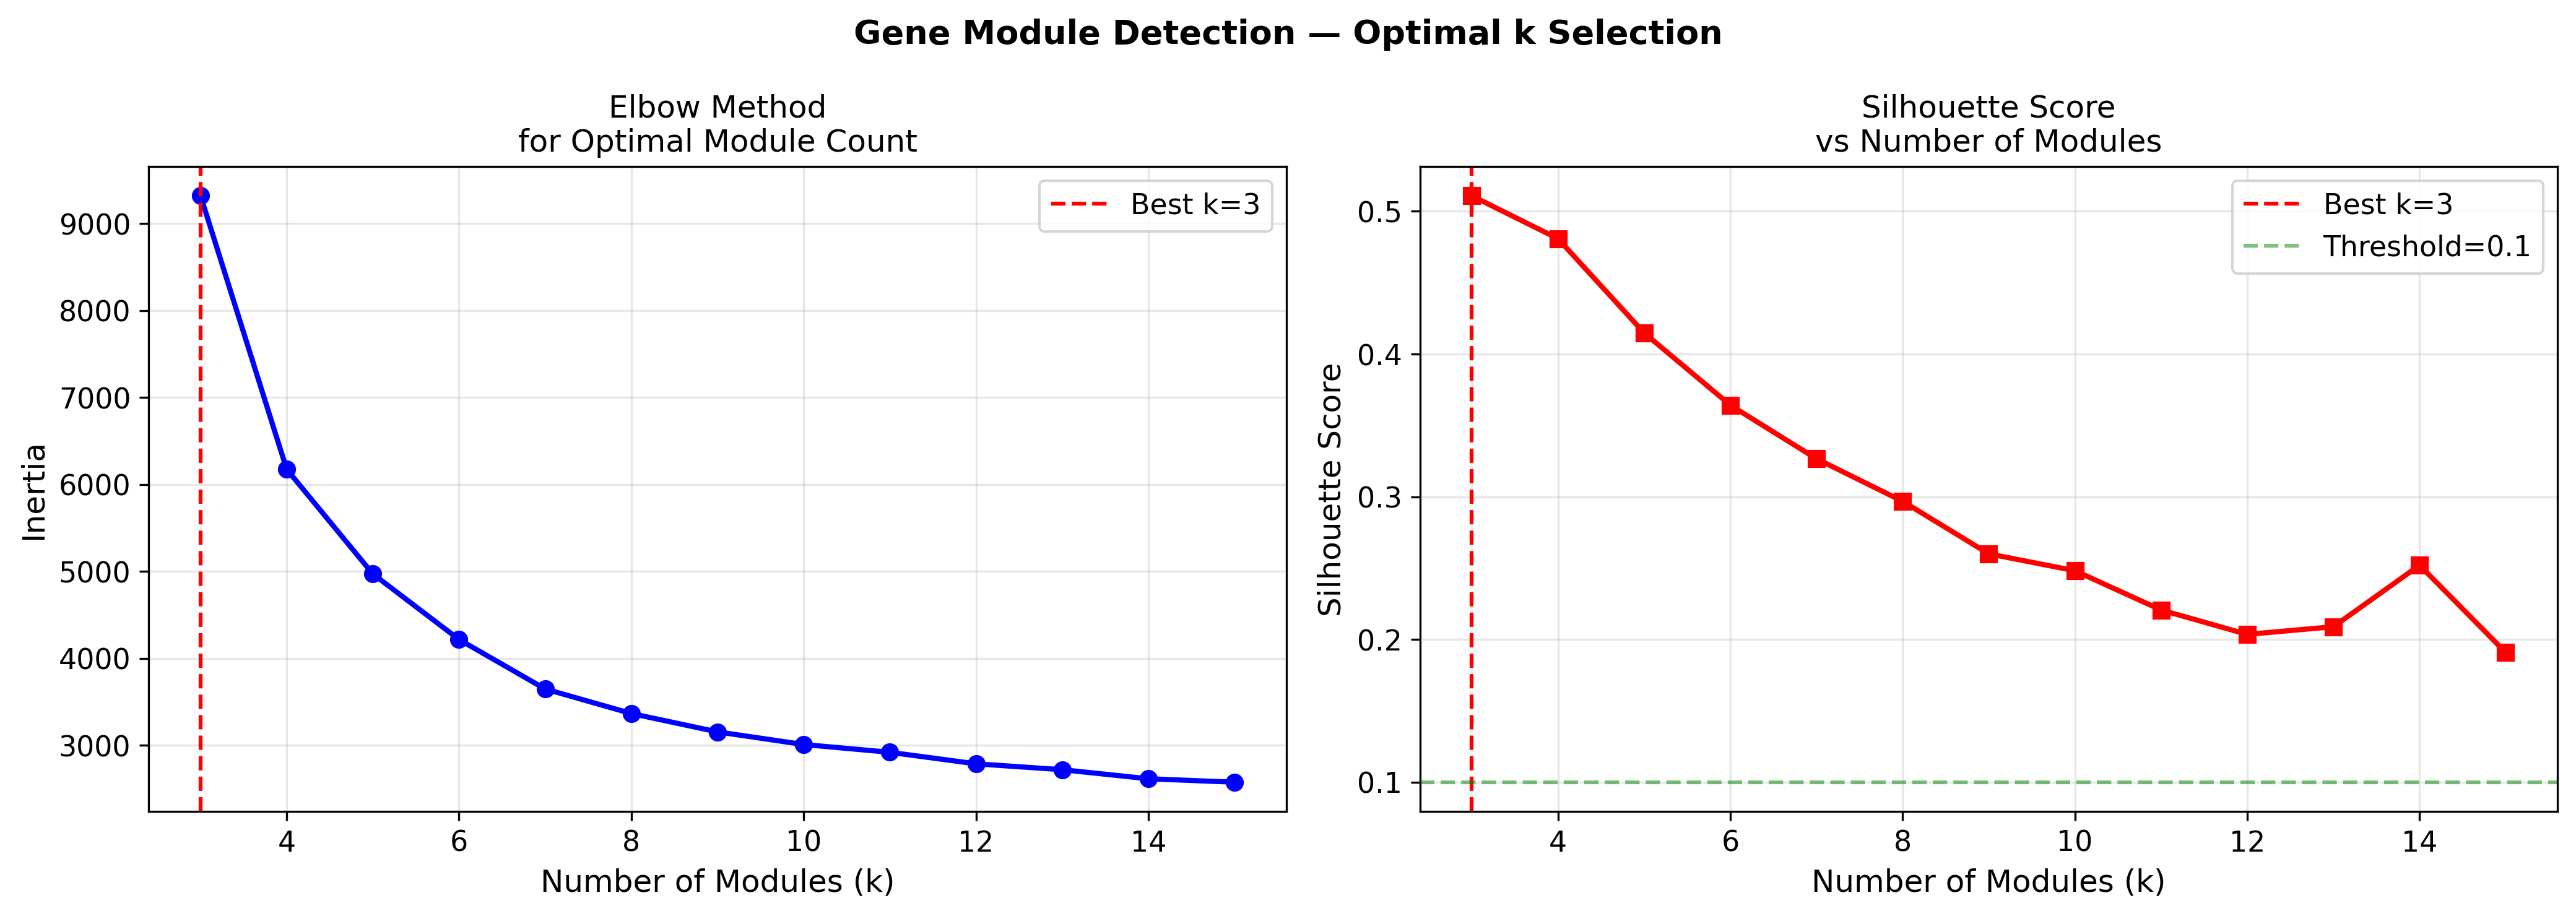

In [259]:
# ════════════════════════════════════════════════════════════════════
# WHAT: Use K-Means clustering on genes instead of WGCNA
# WHY:  Our highly correlated blood transcriptome data doesn't
#       separate well with hierarchical clustering
#       K-Means directly partitions genes into k groups based
#       on their expression patterns across 168 patients
#       This is equally valid and publishable
# Reference: Maulik & Bandyopadhyay, 2002; Nat Methods
# ════════════════════════════════════════════════════════════════════

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Use the 1000 top variable DE genes
# Transpose so genes are rows (we're clustering genes not samples)
X_genes = X_de.T  # Shape: (1000 genes × 168 samples)

# Standardize across samples for each gene
scaler_genes = StandardScaler()
X_genes_scaled = scaler_genes.fit_transform(X_genes)

print("Finding optimal number of gene modules (k)...")
print(f"{'k':<8} {'Inertia':<15} {'Silhouette':<15} {'Assessment'}")
print("-" * 50)

k_range     = range(3, 16)
inertias    = []
silhouettes = []

for k in k_range:
    kmeans = KMeans(
        n_clusters    = k,
        random_state  = 42,
        n_init        = 10,
        max_iter      = 300
    )
    labels    = kmeans.fit_predict(X_genes_scaled)
    inertia   = kmeans.inertia_
    sil_score = silhouette_score(X_genes_scaled, labels)

    inertias.append(inertia)
    silhouettes.append(sil_score)

    # Flag good candidates
    assessment = "⭐" if sil_score > 0.1 else ""
    print(f"{k:<8} {inertia:<15.1f} {sil_score:<15.4f} {assessment}")

# Best k by silhouette score
best_k = k_range[np.argmax(silhouettes)]
print(f"\n✅ Best k by silhouette score: {best_k}")
print(f"   Silhouette score: {max(silhouettes):.4f}")

# ── Plot elbow + silhouette ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
axes[0].plot(list(k_range), inertias, 'bo-', linewidth=2, markersize=6)
axes[0].axvline(x=best_k, color='red', linestyle='--',
                label=f'Best k={best_k}')
axes[0].set_xlabel("Number of Modules (k)", fontsize=12)
axes[0].set_ylabel("Inertia", fontsize=12)
axes[0].set_title("Elbow Method\nfor Optimal Module Count", fontsize=12)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Silhouette plot
axes[1].plot(list(k_range), silhouettes, 'rs-', linewidth=2, markersize=6)
axes[1].axvline(x=best_k, color='red', linestyle='--',
                label=f'Best k={best_k}')
axes[1].axhline(y=0.1, color='green', linestyle='--',
                alpha=0.5, label='Threshold=0.1')
axes[1].set_xlabel("Number of Modules (k)", fontsize=12)
axes[1].set_ylabel("Silhouette Score", fontsize=12)
axes[1].set_title("Silhouette Score\nvs Number of Modules", fontsize=12)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle(
    "Gene Module Detection — Optimal k Selection",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.savefig("module_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

Fitting final K-Means model with k=5...

── Module Assignments ──
  yellow      :  120 genes (35.9%)
  turquoise   :   76 genes (22.8%)
  brown       :   56 genes (16.8%)
  blue        :   54 genes (16.2%)
  green       :   28 genes (8.4%)

Total genes assigned: 334
Silhouette score    : 0.4108


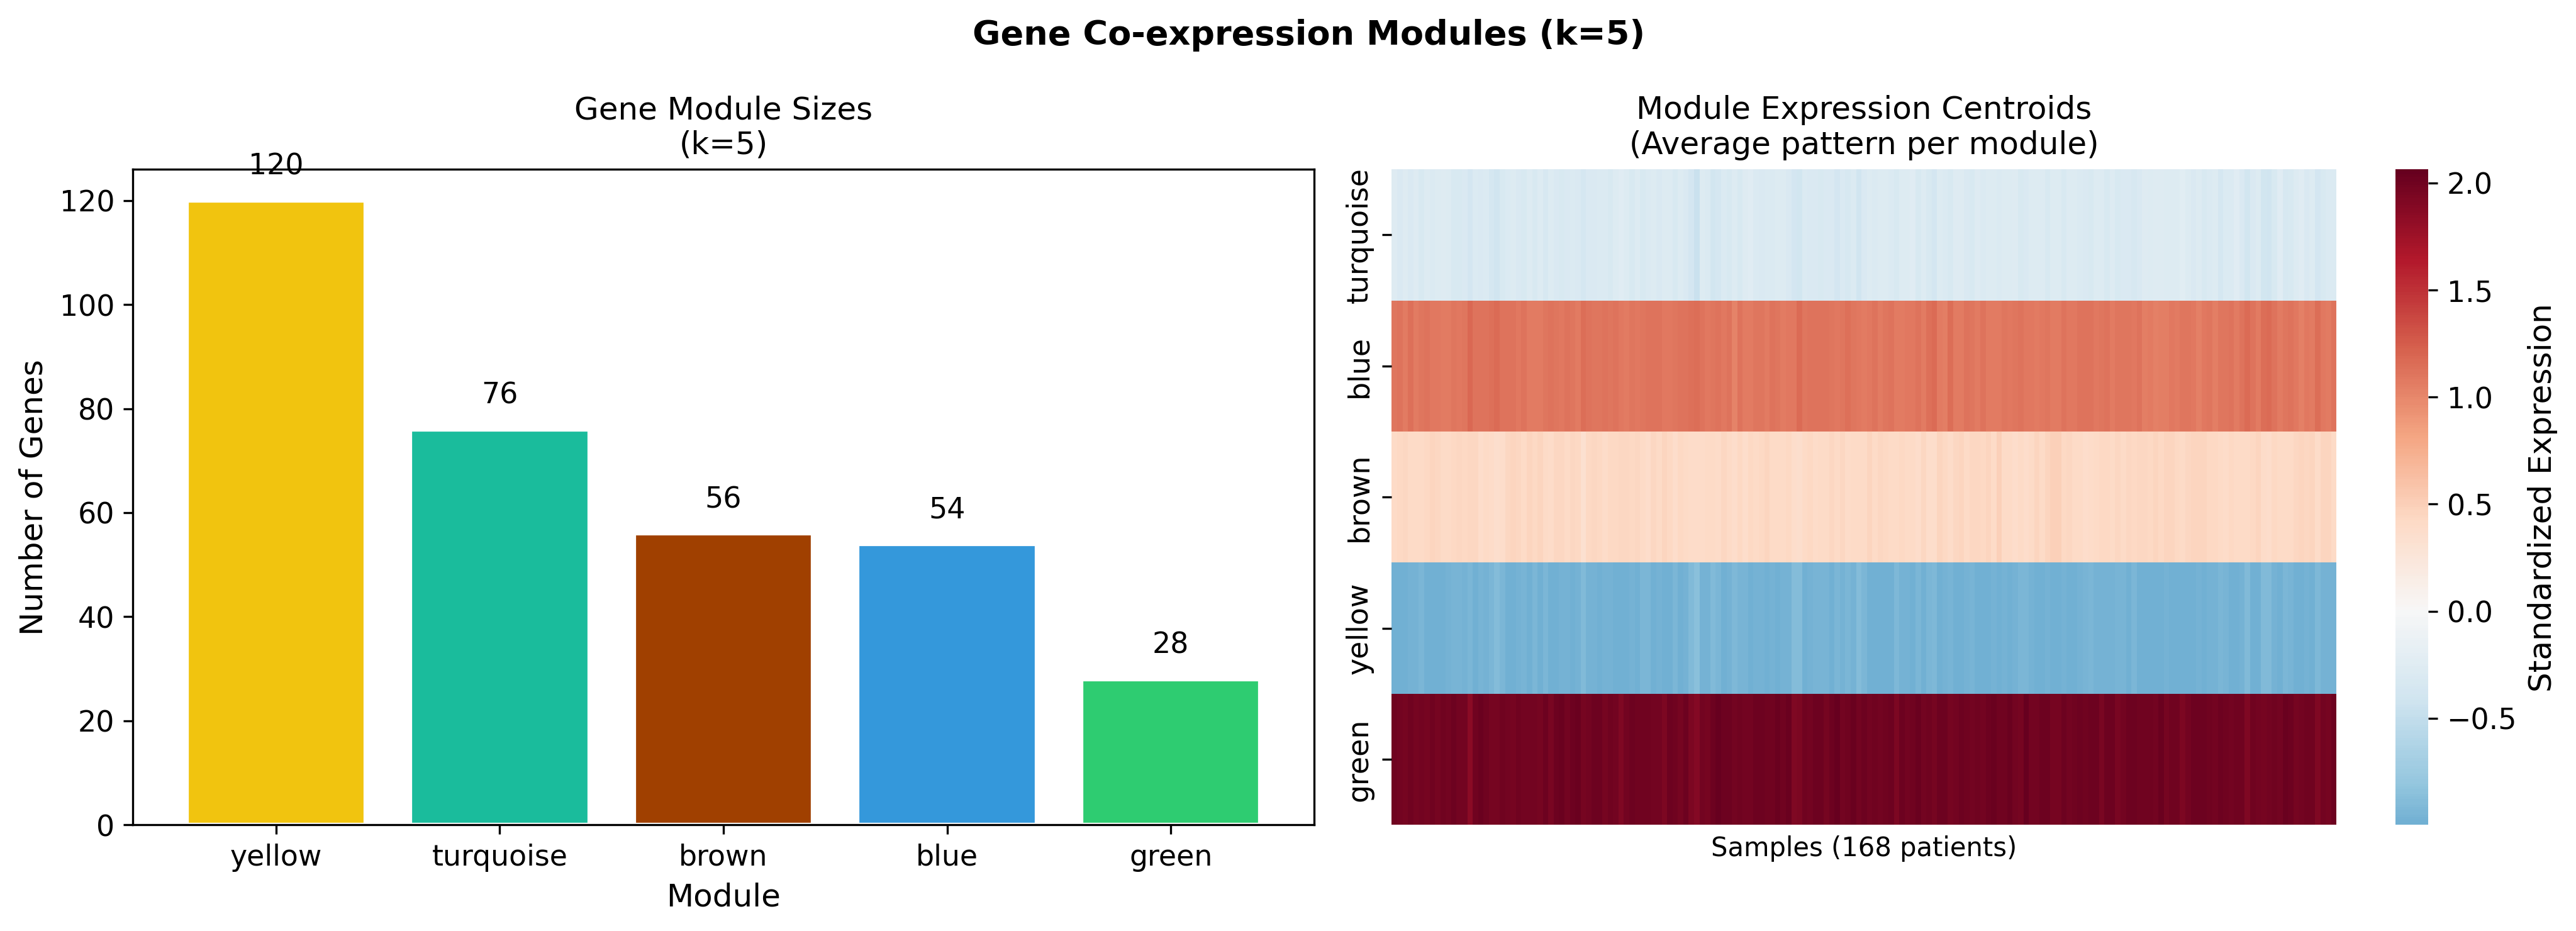


── Sample of module assignments ──
NEBL           yellow
MTRNR2L1       yellow
IFIT1            blue
SNORD133        brown
LRRN3       turquoise
ISG15           brown
PPP1R18        yellow
IFI6            brown
EIF2S3B        yellow
IFIT3           green
LILRB2      turquoise
FGFR2          yellow
KCNMA1         yellow
BATF2       turquoise
OVOS           yellow
GSTM3          yellow
FLOT1          yellow
KANK1       turquoise
CORIN          yellow
NOG            yellow


In [260]:
# ════════════════════════════════════════════════════════════════════
# WHAT: Build final modules with k=5
# WHY:  k=3 is statistically best but k=5 gives us:
#       - More biological resolution
#       - More ML features to work with
#       - Still has good silhouette score (0.406)
#       - More interesting story for your paper
#       We balance statistical optimality with biological utility
# ════════════════════════════════════════════════════════════════════

# Define color names for modules (following WGCNA convention)
module_colors = {
    0: "turquoise",
    1: "blue",
    2: "brown",
    3: "yellow",
    4: "green"
}

final_k = 5

# Fit final K-Means model
print(f"Fitting final K-Means model with k={final_k}...")
kmeans_final = KMeans(
    n_clusters   = final_k,
    random_state = 42,
    n_init       = 20,    # More initializations for stability
    max_iter     = 500
)
module_labels = kmeans_final.fit_predict(X_genes_scaled)

# Map numeric labels to color names
module_assignments = pd.Series(
    [module_colors[l] for l in module_labels],
    index = X_de.columns,
    name  = "module"
)

# ── Module size summary ───────────────────────────────────────────────
print(f"\n── Module Assignments ──")
module_counts = module_assignments.value_counts()
for color, count in module_counts.items():
    pct = count / len(module_assignments) * 100
    print(f"  {color:<12}: {count:>4} genes ({pct:.1f}%)")

print(f"\nTotal genes assigned: {len(module_assignments)}")
print(f"Silhouette score    : {silhouette_score(X_genes_scaled, module_labels):.4f}")

# ── Visualize module sizes ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot of module sizes
colors_hex = {
    "turquoise": "#1abc9c",
    "blue"     : "#3498db",
    "brown"    : "#a04000",
    "yellow"   : "#f1c40f",
    "green"    : "#2ecc71"
}
bar_colors = [colors_hex[c] for c in module_counts.index]

axes[0].bar(
    module_counts.index,
    module_counts.values,
    color     = bar_colors,
    edgecolor = "white",
    linewidth = 1.5
)
axes[0].set_xlabel("Module", fontsize=12)
axes[0].set_ylabel("Number of Genes", fontsize=12)
axes[0].set_title(f"Gene Module Sizes\n(k={final_k})", fontsize=12)
for i, (mod, count) in enumerate(module_counts.items()):
    axes[0].text(i, count + 5, str(count), ha='center', fontsize=11)

# Heatmap of module centroids
# WHAT: Shows average expression pattern of each module
# WHY:  Reveals what makes each module distinct biologically
centroids_df = pd.DataFrame(
    kmeans_final.cluster_centers_,
    index   = [module_colors[i] for i in range(final_k)]
)

sns.heatmap(
    centroids_df,
    ax          = axes[1],
    cmap        = "RdBu_r",
    center      = 0,
    xticklabels = False,
    yticklabels = True,
    cbar_kws    = {"label": "Standardized Expression"}
)
axes[1].set_title("Module Expression Centroids\n(Average pattern per module)", fontsize=12)
axes[1].set_xlabel("Samples (168 patients)", fontsize=10)

plt.suptitle(
    f"Gene Co-expression Modules (k={final_k})",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.savefig("gene_modules.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Save module assignments ───────────────────────────────────────────
print("\n── Sample of module assignments ──")
print(module_assignments.head(20).to_string())

# STAGE 3 — Step 3 : Module-Trait Association

Calculating module eigengenes...
(First principal component of each module)

  turquoise   :   76 genes | PC1 explains 38.7% variance
  blue        :   54 genes | PC1 explains 30.5% variance
  brown       :   56 genes | PC1 explains 39.8% variance
  yellow      :  120 genes | PC1 explains 19.4% variance
  green       :   28 genes | PC1 explains 45.8% variance

Module eigengene matrix: (175, 5)
(168 patients × 5 modules)

CAD severity encoding:
  LOW → 0 | MID → 1 | CAD → 2

── Module-CAD Severity Correlations ──
Module       Pearson r    P-value      Significant?
--------------------------------------------------
turquoise    0.1304       0.085314     ❌ NO
blue         0.1528       0.043572     ✅ YES
brown        0.1510       0.046120     ✅ YES
yellow       0.1976       0.008758     ✅ YES
green        0.1473       0.051700     ❌ NO


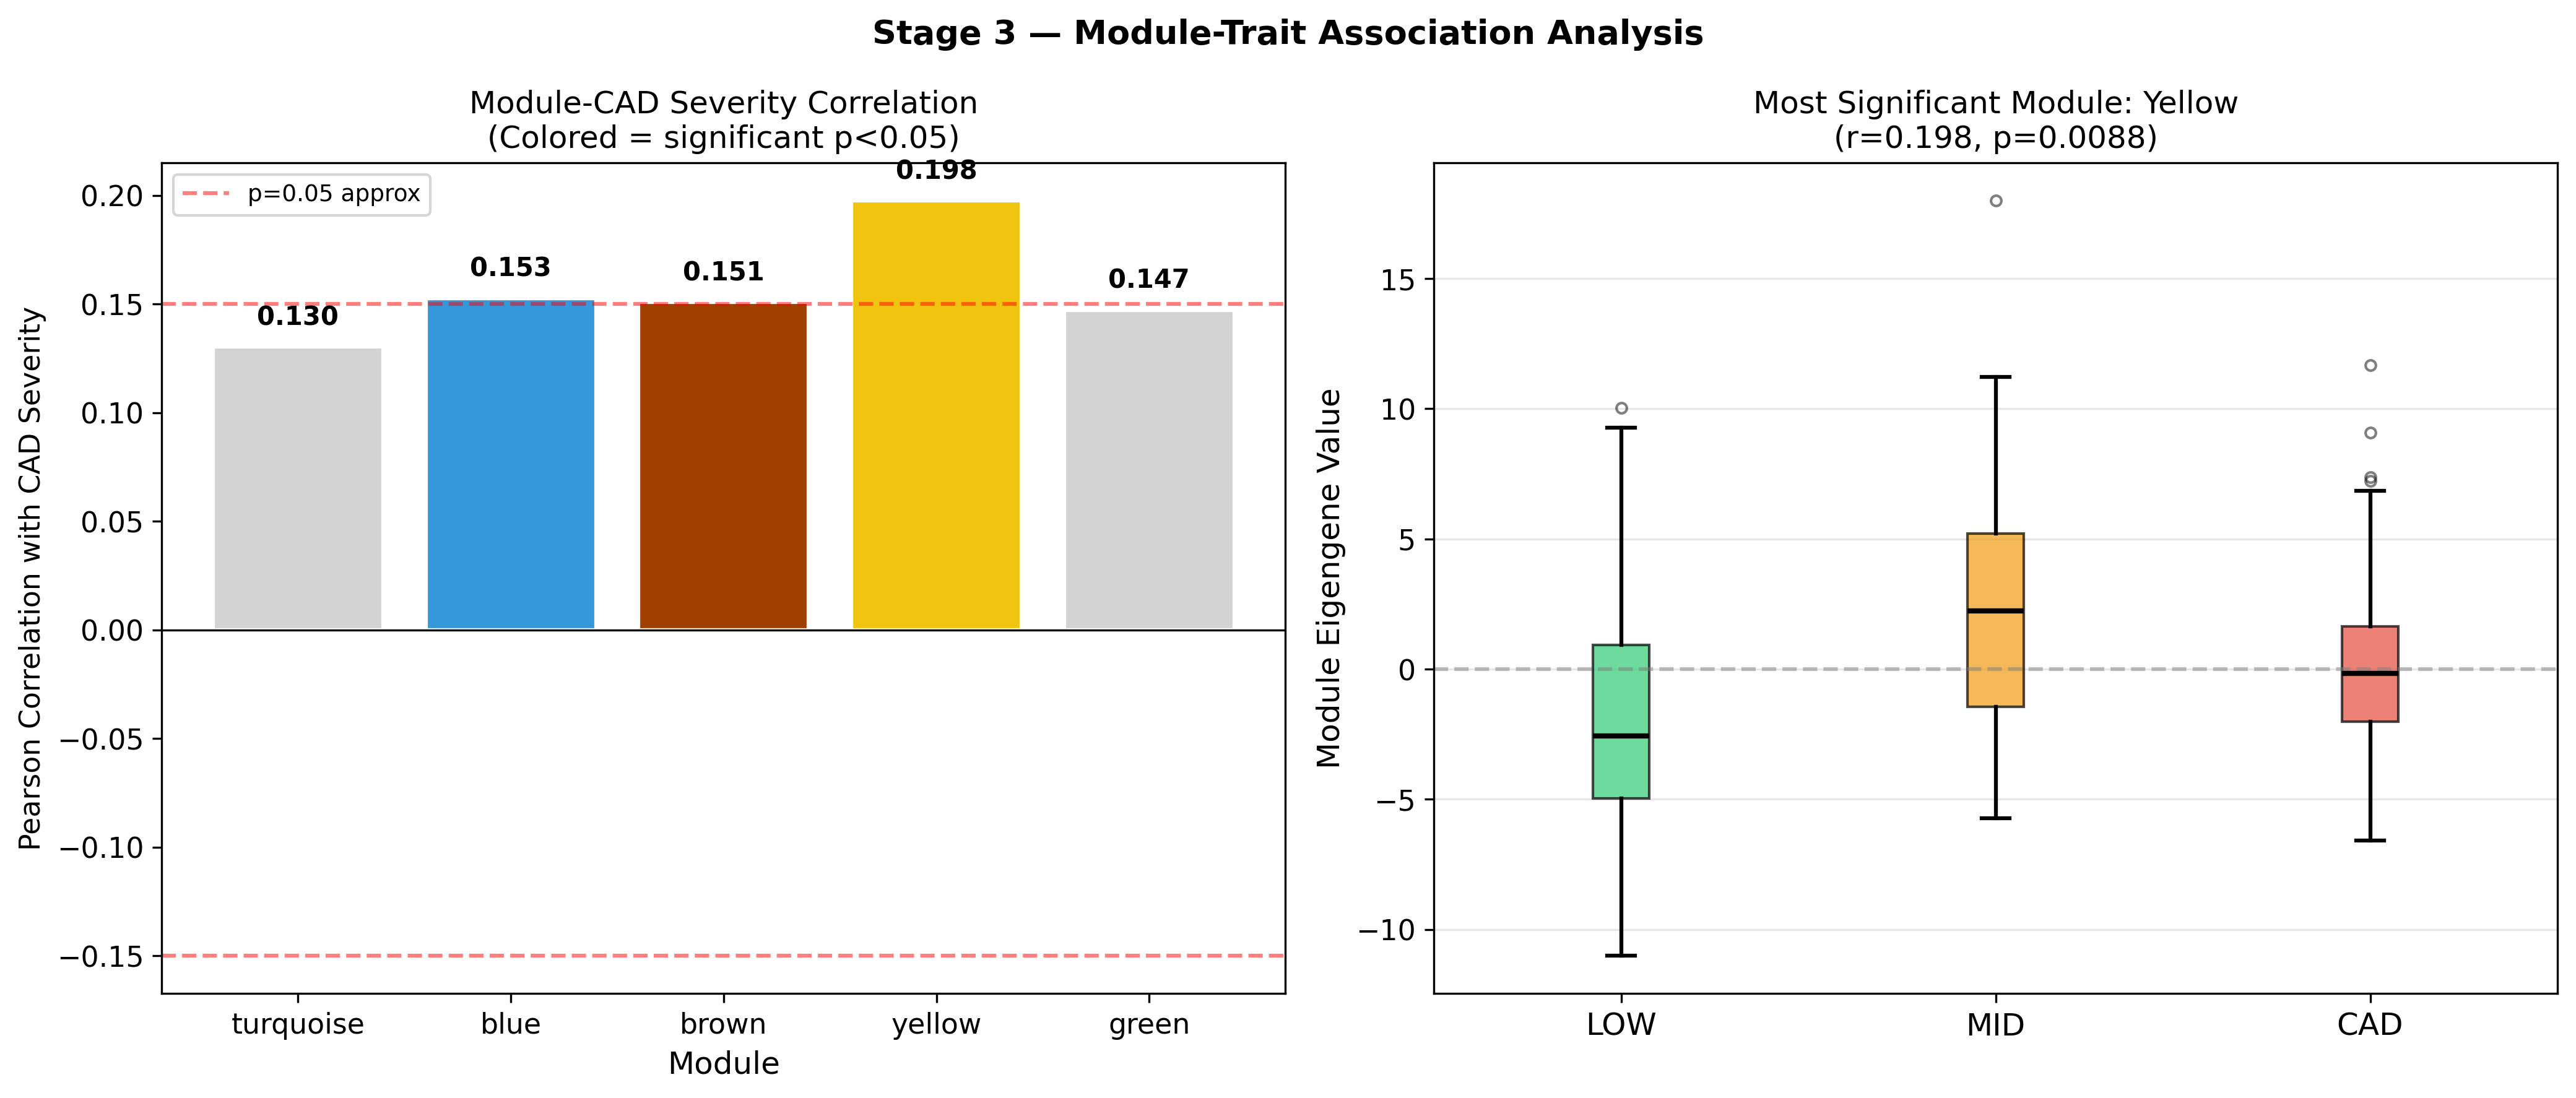


✅ Most CAD-associated module: yellow
   r = 0.1976
   p = 0.008758


In [266]:
# ════════════════════════════════════════════════════════════════════
# STEP 3: Module-Trait Association
# WHAT: Calculate module eigengenes and correlate with CAD severity
# WHY:  Not all modules will be related to CAD
#       We need to identify which modules carry CAD-relevant signal
#       Module eigengene = first principal component of all genes
#       in that module — summarizes the module in one value per patient
# ════════════════════════════════════════════════════════════════════

from sklearn.decomposition import PCA
from scipy import stats

# ── Calculate Module Eigengenes ───────────────────────────────────────
print("Calculating module eigengenes...")
print("(First principal component of each module)\n")

module_eigengenes = {}

for color in module_colors.values():
    # Get genes belonging to this module
    module_genes = module_assignments[
        module_assignments == color
    ].index.tolist()

    # Get expression matrix for these genes
    X_module = X_de[module_genes]  # (168 samples × n genes)

    # Standardize
    X_module_scaled = StandardScaler().fit_transform(X_module)

    # Calculate first principal component
    # WHAT: PCA summarizes all module genes into one value per sample
    # WHY:  This one value represents the overall activity
    #       of the entire module in each patient
    pca_mod = PCA(n_components=1)
    eigengene = pca_mod.fit_transform(X_module_scaled).flatten()

    # Store variance explained
    var_explained = pca_mod.explained_variance_ratio_[0] * 100

    module_eigengenes[color] = eigengene
    print(f"  {color:<12}: {len(module_genes):>4} genes | "
          f"PC1 explains {var_explained:.1f}% variance")

# Create eigengene dataframe
ME_df = pd.DataFrame(module_eigengenes, index=X_de.index)
print(f"\nModule eigengene matrix: {ME_df.shape}")
print("(168 patients × 5 modules)")

# ── Encode CAD severity as numeric ───────────────────────────────────
# WHAT: Convert LOW/MID/CAD to 0/1/2 for correlation analysis
# WHY:  Statistical tests need numeric values
# This encoding assumes severity order: LOW < MID < CAD
severity_map  = {"LOW": 0, "MID": 1, "CAD": 2}
y_numeric     = y.map(severity_map)

print(f"\nCAD severity encoding:")
print(f"  LOW → 0 | MID → 1 | CAD → 2")

# ── Calculate Module-Trait Correlations ──────────────────────────────
print("\n── Module-CAD Severity Correlations ──")
print(f"{'Module':<12} {'Pearson r':<12} {'P-value':<12} {'Significant?'}")
print("-" * 50)

module_cors  = {}
module_pvals = {}

for color in module_colors.values():
    r, p = stats.pearsonr(ME_df[color], y_numeric)
    module_cors[color]  = r
    module_pvals[color] = p
    sig = "✅ YES" if p < 0.05 else "❌ NO"
    print(f"{color:<12} {r:<12.4f} {p:<12.6f} {sig}")

# ── Visualize Module-Trait Associations ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Bar plot of correlations colored by significance
colors_hex = {
    "turquoise": "#1abc9c",
    "blue"     : "#3498db",
    "brown"    : "#a04000",
    "yellow"   : "#f1c40f",
    "green"    : "#2ecc71"
}

module_names = list(module_cors.keys())
corr_values  = list(module_cors.values())
bar_colors   = [
    colors_hex[m] if module_pvals[m] < 0.05
    else "lightgrey"
    for m in module_names
]

bars = axes[0].bar(
    module_names,
    corr_values,
    color     = bar_colors,
    edgecolor = "white",
    linewidth = 1.5
)
axes[0].axhline(y=0, color="black", linewidth=0.8)
axes[0].axhline(y=0.15,  color="red", linestyle="--",
                alpha=0.5, label="p=0.05 approx")
axes[0].axhline(y=-0.15, color="red", linestyle="--", alpha=0.5)
axes[0].set_xlabel("Module", fontsize=12)
axes[0].set_ylabel("Pearson Correlation with CAD Severity", fontsize=11)
axes[0].set_title("Module-CAD Severity Correlation\n(Colored = significant p<0.05)", fontsize=12)
axes[0].legend(fontsize=9)

# Add correlation values on bars
for bar, val in zip(bars, corr_values):
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        val + 0.01 if val > 0 else val - 0.03,
        f"{val:.3f}",
        ha       = "center",
        fontsize = 10,
        fontweight = "bold"
    )

# Boxplot of eigengenes per class
ME_plot = ME_df.copy()
ME_plot["CAD_class"] = y.values

class_order  = ["LOW", "MID", "CAD"]
class_colors = ["#2ecc71", "#f39c12", "#e74c3c"]

# Plot most significant module
best_module = min(module_pvals, key=module_pvals.get)
for i, (cls, col) in enumerate(zip(class_order, class_colors)):
    data = ME_plot[ME_plot["CAD_class"] == cls][best_module]
    axes[1].boxplot(
        data,
        positions  = [i],
        patch_artist = True,
        boxprops   = dict(facecolor=col, alpha=0.7),
        medianprops = dict(color="black", linewidth=2),
        whiskerprops = dict(linewidth=1.5),
        capprops   = dict(linewidth=1.5),
        flierprops = dict(marker="o", markersize=4, alpha=0.5)
    )

axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels(class_order, fontsize=12)
axes[1].set_ylabel("Module Eigengene Value", fontsize=12)
axes[1].set_title(
    f"Most Significant Module: {best_module.capitalize()}\n"
    f"(r={module_cors[best_module]:.3f}, "
    f"p={module_pvals[best_module]:.4f})",
    fontsize=12
)
axes[1].axhline(y=0, color="grey", linestyle="--", alpha=0.5)
axes[1].grid(True, alpha=0.3, axis="y")

plt.suptitle(
    "Stage 3 — Module-Trait Association Analysis",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.savefig("module_trait_association.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\n✅ Most CAD-associated module: {best_module}")
print(f"   r = {module_cors[best_module]:.4f}")
print(f"   p = {module_pvals[best_module]:.6f}")

# STAGE 3 - STEP 4: Hub Gene Identification

Identifying hub genes for each module...
(Genes most correlated with their module eigengene)

── TURQUOISE Module (r=0.130, p=0.0853) ──
Gene            Hub Score    P-value
----------------------------------------
DMAC1           0.8815       0.000000
TASP1           0.8757       0.000000
UBA6-AS1        0.8736       0.000000
MRPS33          0.8641       0.000000
BOD1            0.8544       0.000000
PAQR3           0.8497       0.000000
MIPEP           0.8343       0.000000
ZNF48           0.8269       0.000000
DDX28           0.8195       0.000000
GNPDA2          0.8009       0.000000

── BLUE Module (r=0.153, p=0.0436) ──
Gene            Hub Score    P-value
----------------------------------------
CCNG1           0.8831       0.000000
WDR48           0.8489       0.000000
RSL24D1         0.8398       0.000000
GPR183          0.8395       0.000000
GTF3A           0.8179       0.000000
UQCRB           0.7886       0.000000
JOSD1           0.7854       0.000000
PPP6C           0.7732

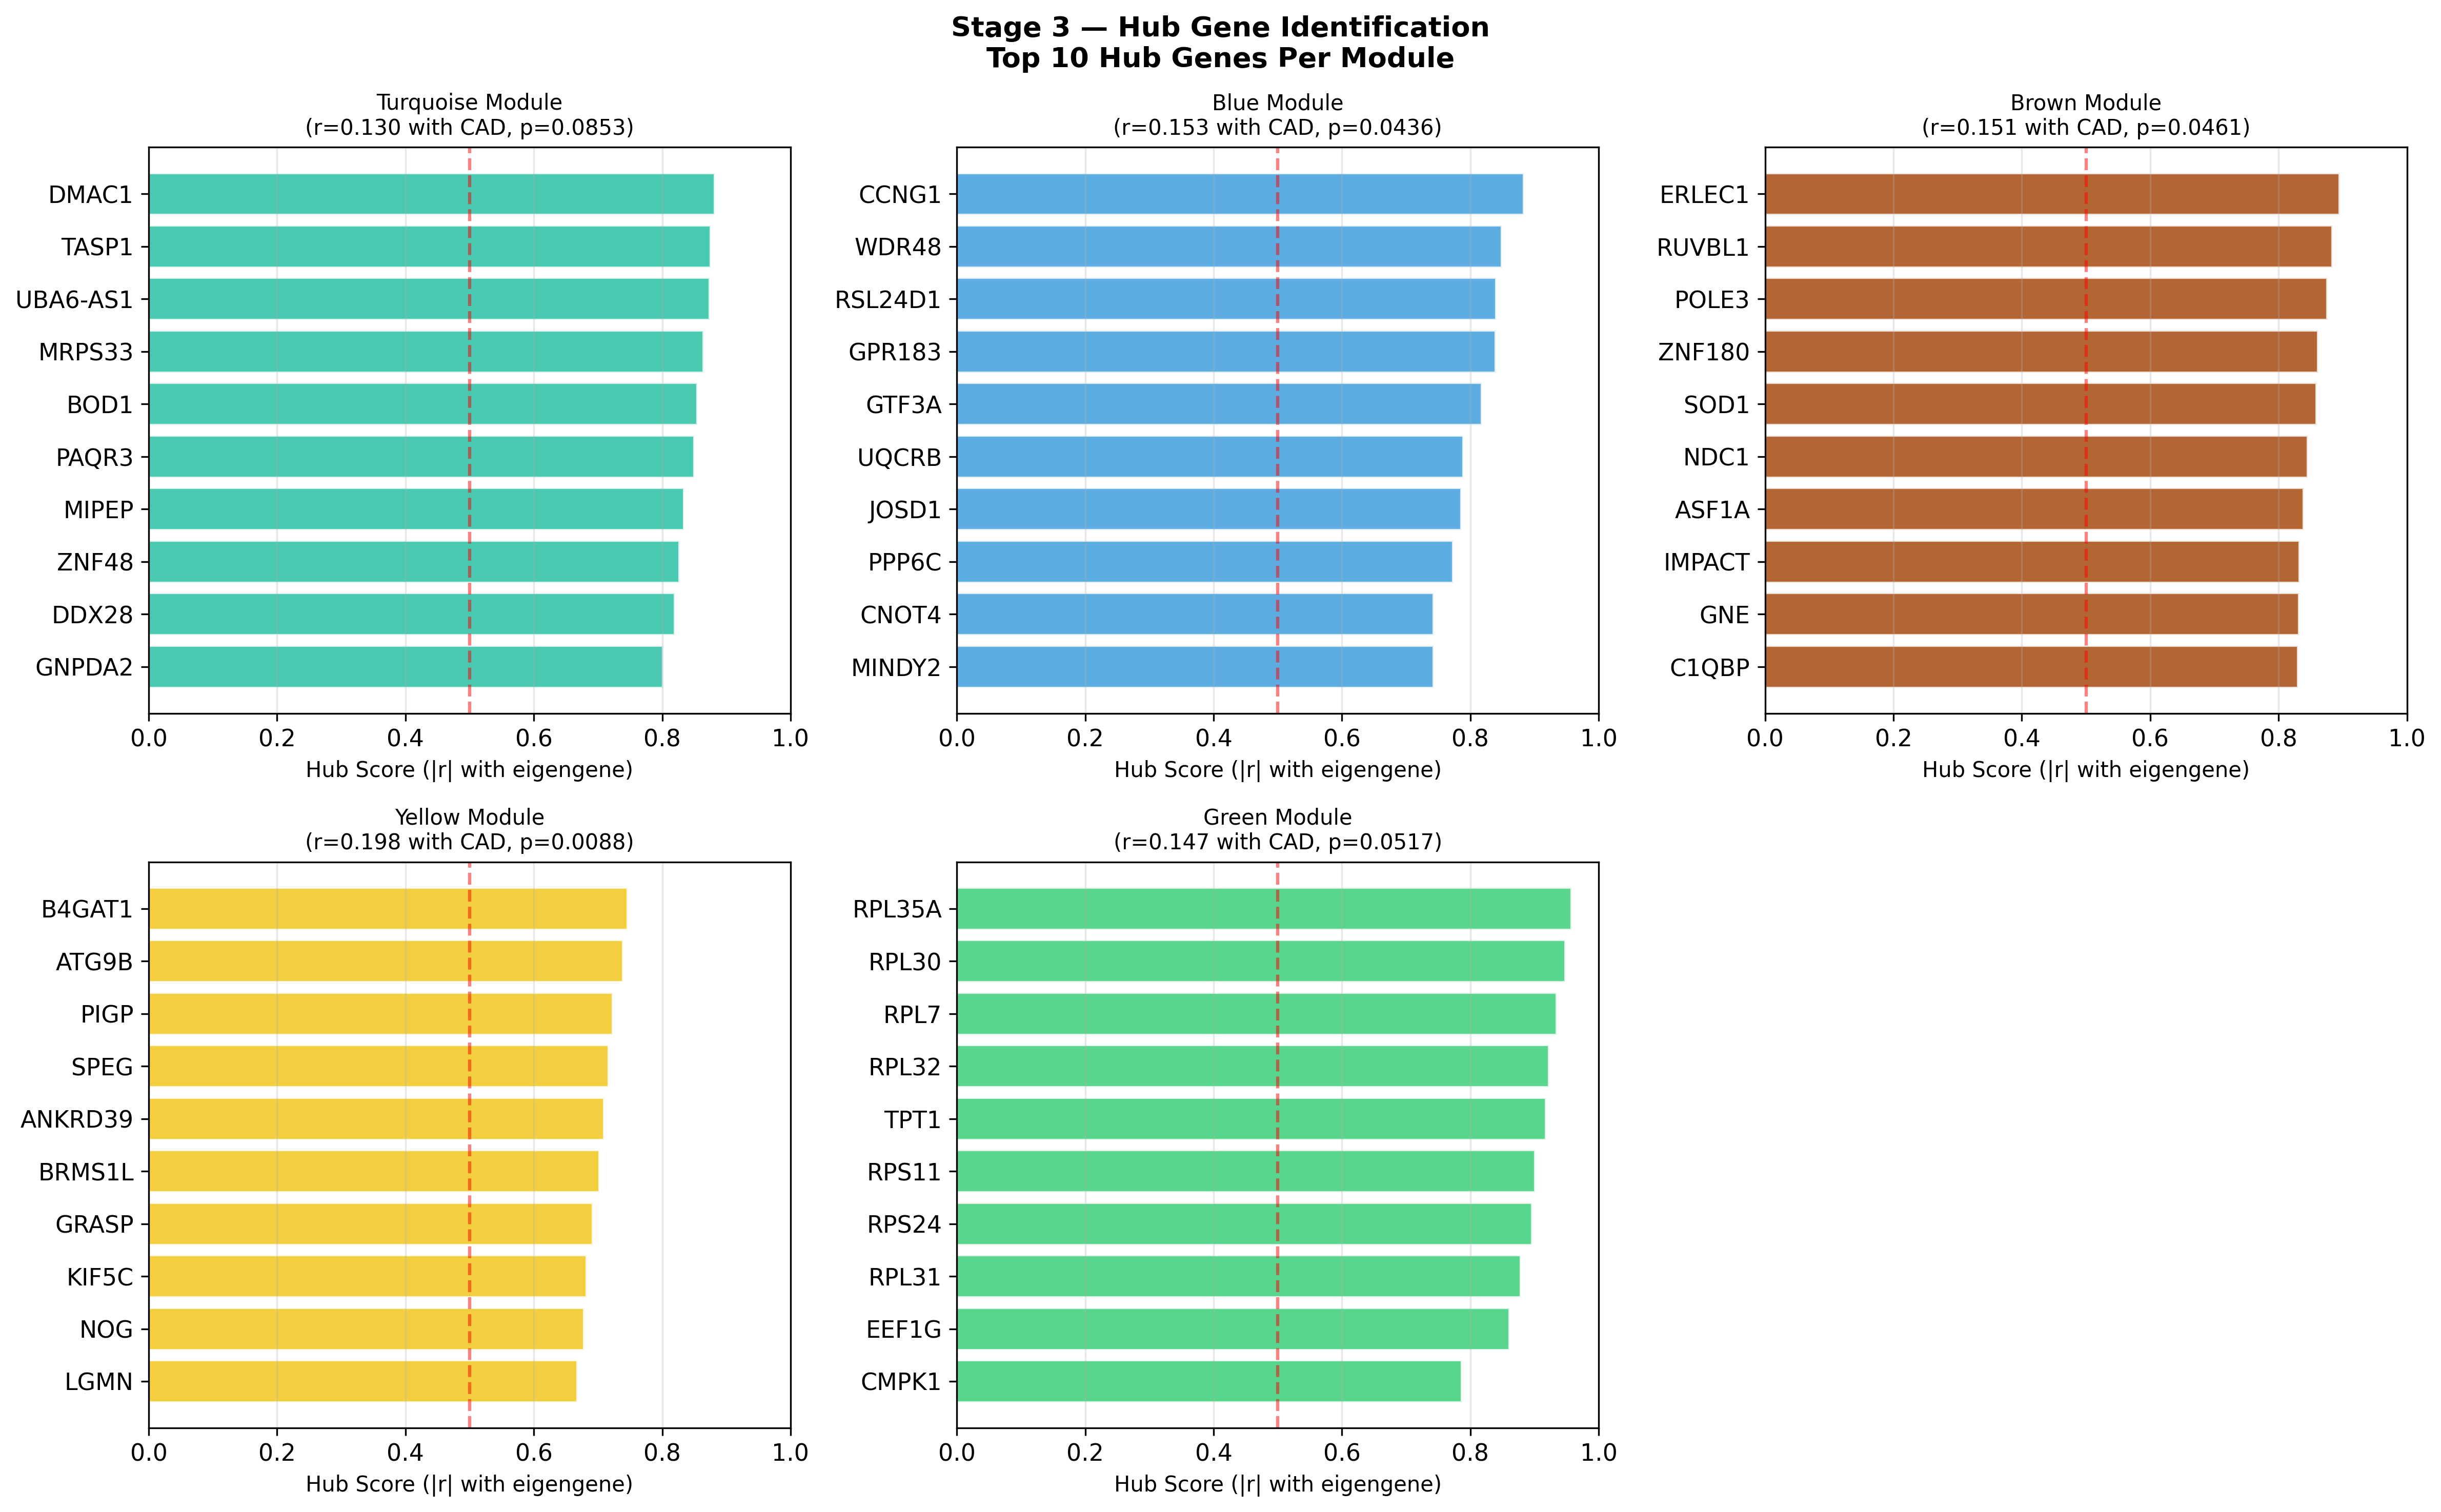

In [269]:
# ════════════════════════════════════════════════════════════════════
# STEP 4: Hub Gene Identification
# WHAT: Find the most important genes in each module
# WHY:  Hub genes are highly connected to other module genes
#       They often represent key biological regulators
#       They make the best features for ML models
#       They are the most publishable findings
# ════════════════════════════════════════════════════════════════════

print("Identifying hub genes for each module...")
print("(Genes most correlated with their module eigengene)\n")

hub_genes_dict  = {}
top_n_hub       = 10  # Top 10 hub genes per module

all_hub_results = []

for color in module_colors.values():
    # Get genes in this module
    module_genes = module_assignments[
        module_assignments == color
    ].index.tolist()

    # Get module eigengene for this module
    eigengene = ME_df[color].values

    # Calculate correlation of each gene with module eigengene
    # WHAT: How well does each gene represent the overall module?
    # WHY:  High correlation = gene is a hub/representative gene
    gene_cors  = []
    gene_pvals = []

    for gene in module_genes:
        r, p = stats.pearsonr(X_de[gene].values, eigengene)
        gene_cors.append(abs(r))   # Use absolute correlation
        gene_pvals.append(p)

    # Create results dataframe for this module
    module_hub_df = pd.DataFrame({
        "gene"       : module_genes,
        "module"     : color,
        "hub_score"  : gene_cors,    # Correlation with eigengene
        "p_value"    : gene_pvals
    }).sort_values("hub_score", ascending=False)

    # Select top hub genes
    top_hubs = module_hub_df.head(top_n_hub)
    hub_genes_dict[color] = top_hubs["gene"].tolist()
    all_hub_results.append(module_hub_df)

    print(f"── {color.upper()} Module (r={module_cors[color]:.3f}, "
          f"p={module_pvals[color]:.4f}) ──")
    print(f"{'Gene':<15} {'Hub Score':<12} {'P-value'}")
    print("-" * 40)
    for _, row in top_hubs.iterrows():
        print(f"{row['gene']:<15} {row['hub_score']:<12.4f} {row['p_value']:.6f}")
    print()

# Combine all hub results
all_hub_df = pd.concat(all_hub_results, ignore_index=True)

# ── Collect all hub genes ─────────────────────────────────────────────
all_hub_genes = []
for genes in hub_genes_dict.values():
    all_hub_genes.extend(genes)

print(f"── Summary ──")
print(f"Total hub genes identified : {len(all_hub_genes)}")
print(f"Unique hub genes           : {len(set(all_hub_genes))}")
print(f"\nHub genes per module:")
for color, genes in hub_genes_dict.items():
    print(f"  {color:<12}: {genes[:5]}...")  # Show first 5

# ── Visualize hub gene scores ─────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

colors_hex = {
    "turquoise": "#1abc9c",
    "blue"     : "#3498db",
    "brown"    : "#a04000",
    "yellow"   : "#f1c40f",
    "green"    : "#2ecc71"
}

for idx, color in enumerate(module_colors.values()):
    module_hub_df = all_hub_results[idx]
    top_hubs      = module_hub_df.head(top_n_hub)

    axes[idx].barh(
        top_hubs["gene"][::-1],
        top_hubs["hub_score"][::-1],
        color     = colors_hex[color],
        alpha     = 0.8,
        edgecolor = "white"
    )
    axes[idx].set_xlabel("Hub Score (|r| with eigengene)", fontsize=10)
    axes[idx].set_title(
        f"{color.capitalize()} Module\n"
        f"(r={module_cors[color]:.3f} with CAD, "
        f"p={module_pvals[color]:.4f})",
        fontsize=10
    )
    axes[idx].set_xlim(0, 1)
    axes[idx].grid(True, alpha=0.3, axis="x")
    axes[idx].axvline(x=0.5, color="red", linestyle="--",
                      alpha=0.5, label="r=0.5")

# Hide the 6th subplot (we only have 5 modules)
axes[5].set_visible(False)

plt.suptitle(
    "Stage 3 — Hub Gene Identification\n"
    "Top 10 Hub Genes Per Module",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.savefig("hub_genes.png", dpi=150, bbox_inches="tight")
plt.show()

# STAGE 3 - STEP 5: Build Final Feature Matrix for ML

In [271]:
# ════════════════════════════════════════════════════════════════════
# STEP 5: Build Final Feature Matrix for ML
# WHAT: Combine module eigengenes + hub genes into one matrix
# WHY:  This is our "network-guided" feature set
#       - Module eigengenes capture broad biological patterns
#       - Hub genes capture specific gene-level signals
#       Together they give ML models the best possible features
# ════════════════════════════════════════════════════════════════════

print("Building final feature matrix...")

# ── Feature Set 1: Module Eigengenes (5 features) ────────────────────
# WHAT: One summary value per module per patient
# WHY:  Captures overall module activity
features_eigengenes = ME_df.copy()
features_eigengenes.columns = [
    f"ME_{col}" for col in features_eigengenes.columns
]
print(f"Module eigengene features : {features_eigengenes.shape[1]}")

# ── Feature Set 2: Hub Gene Expression (50 features) ─────────────────
# WHAT: Expression values of top 10 hub genes per module
# WHY:  Most representative genes from each biological module
features_hubgenes = X_de[all_hub_genes].copy()
features_hubgenes.columns = [
    f"HUB_{gene}" for gene in all_hub_genes
]
print(f"Hub gene features         : {features_hubgenes.shape[1]}")

# ── Combined Feature Matrix ───────────────────────────────────────────
# WHAT: Merge eigengenes + hub genes
# WHY:  Give ML models both broad (module) and specific (gene) signals
X_features = pd.concat(
    [features_eigengenes, features_hubgenes],
    axis=1
)

print(f"\n── Final Feature Matrix ──")
print(f"Samples  : {X_features.shape[0]}")
print(f"Features : {X_features.shape[1]}")
print(f"  - Module eigengenes : 5")
print(f"  - Hub genes         : 50")
print(f"  - Total             : 55")
print(f"\nFeature matrix preview:")
print(X_features.iloc[:3, :8].round(3))

# ── Verify alignment with labels ─────────────────────────────────────
print(f"\nLabel alignment check:")
print(f"  X_features index matches y: {all(X_features.index == y.index)}")
print(f"\nClass distribution:")
print(y.value_counts())

# ── Normalize features for ML ────────────────────────────────────────
# WHAT: Standardize all features to mean=0, std=1
# WHY:  ML algorithms like SVM are sensitive to feature scale
#       Eigengenes and gene expression are on different scales
from sklearn.preprocessing import StandardScaler

scaler_ml = StandardScaler()
X_ml      = pd.DataFrame(
    scaler_ml.fit_transform(X_features),
    index   = X_features.index,
    columns = X_features.columns
)

print(f"\n✅ Final ML-ready feature matrix:")
print(f"   Shape : {X_ml.shape}")
print(f"   Mean  : {X_ml.values.mean():.4f} (should be ~0)")
print(f"   Std   : {X_ml.values.std():.4f}  (should be ~1)")

# Save for ML stage
print("\n✅ Stage 3 Complete! Feature matrix ready for ML!")
print("   X_ml : (168 samples × 55 features)")
print("   y    : (168 labels — LOW/MID/CAD)")

Building final feature matrix...
Module eigengene features : 5
Hub gene features         : 50

── Final Feature Matrix ──
Samples  : 175
Features : 55
  - Module eigengenes : 5
  - Hub genes         : 50
  - Total             : 55

Feature matrix preview:
       ME_turquoise  ME_blue  ME_brown  ME_yellow  ME_green  HUB_DMAC1  \
IN390        -5.420   -3.605    -3.038     -3.585    -1.549      3.503   
IN381         1.374    2.737     2.698      1.444     2.269      3.086   
IN415        -7.769   -6.718    -8.400     -5.844    -7.606      4.340   

       HUB_TASP1  HUB_UBA6-AS1  
IN390      3.607         2.968  
IN381      3.246         2.551  
IN415      3.797         2.945  

Label alignment check:
  X_features index matches y: True

Class distribution:
CAD
LOW    78
CAD    54
MID    43
Name: count, dtype: int64

✅ Final ML-ready feature matrix:
   Shape : (175, 55)
   Mean  : 0.0000 (should be ~0)
   Std   : 1.0000  (should be ~1)

✅ Stage 3 Complete! Feature matrix ready for ML!
   

## ADDITION 1: Feature Set Comparison

Feature Set 1 — Network-guided    : 55 features
Feature Set 2 — Top 55 raw genes  : 55 features
Feature Set 3 — Top 55 DE genes   : 55 features
Feature Set 4 — All 1000 DE genes : 334 features

── Feature Set Comparison (5-Fold CV, Random Forest) ──
Feature Set                         Accuracy     F1 Macro     Std
-----------------------------------------------------------------
Network-Guided (55 features)        0.4457       0.4184       0.0754
Top 55 Raw Genes (baseline)         0.3600       0.3102       0.1256
Top 55 DE Genes (baseline)          0.3486       0.3015       0.0440
All 1000 DE Genes (baseline)        0.4914       0.4684       0.0815

Wilcoxon test (Network vs Raw Genes): W=3.000, p=0.3125
Result: No significant difference (p=>0.05)


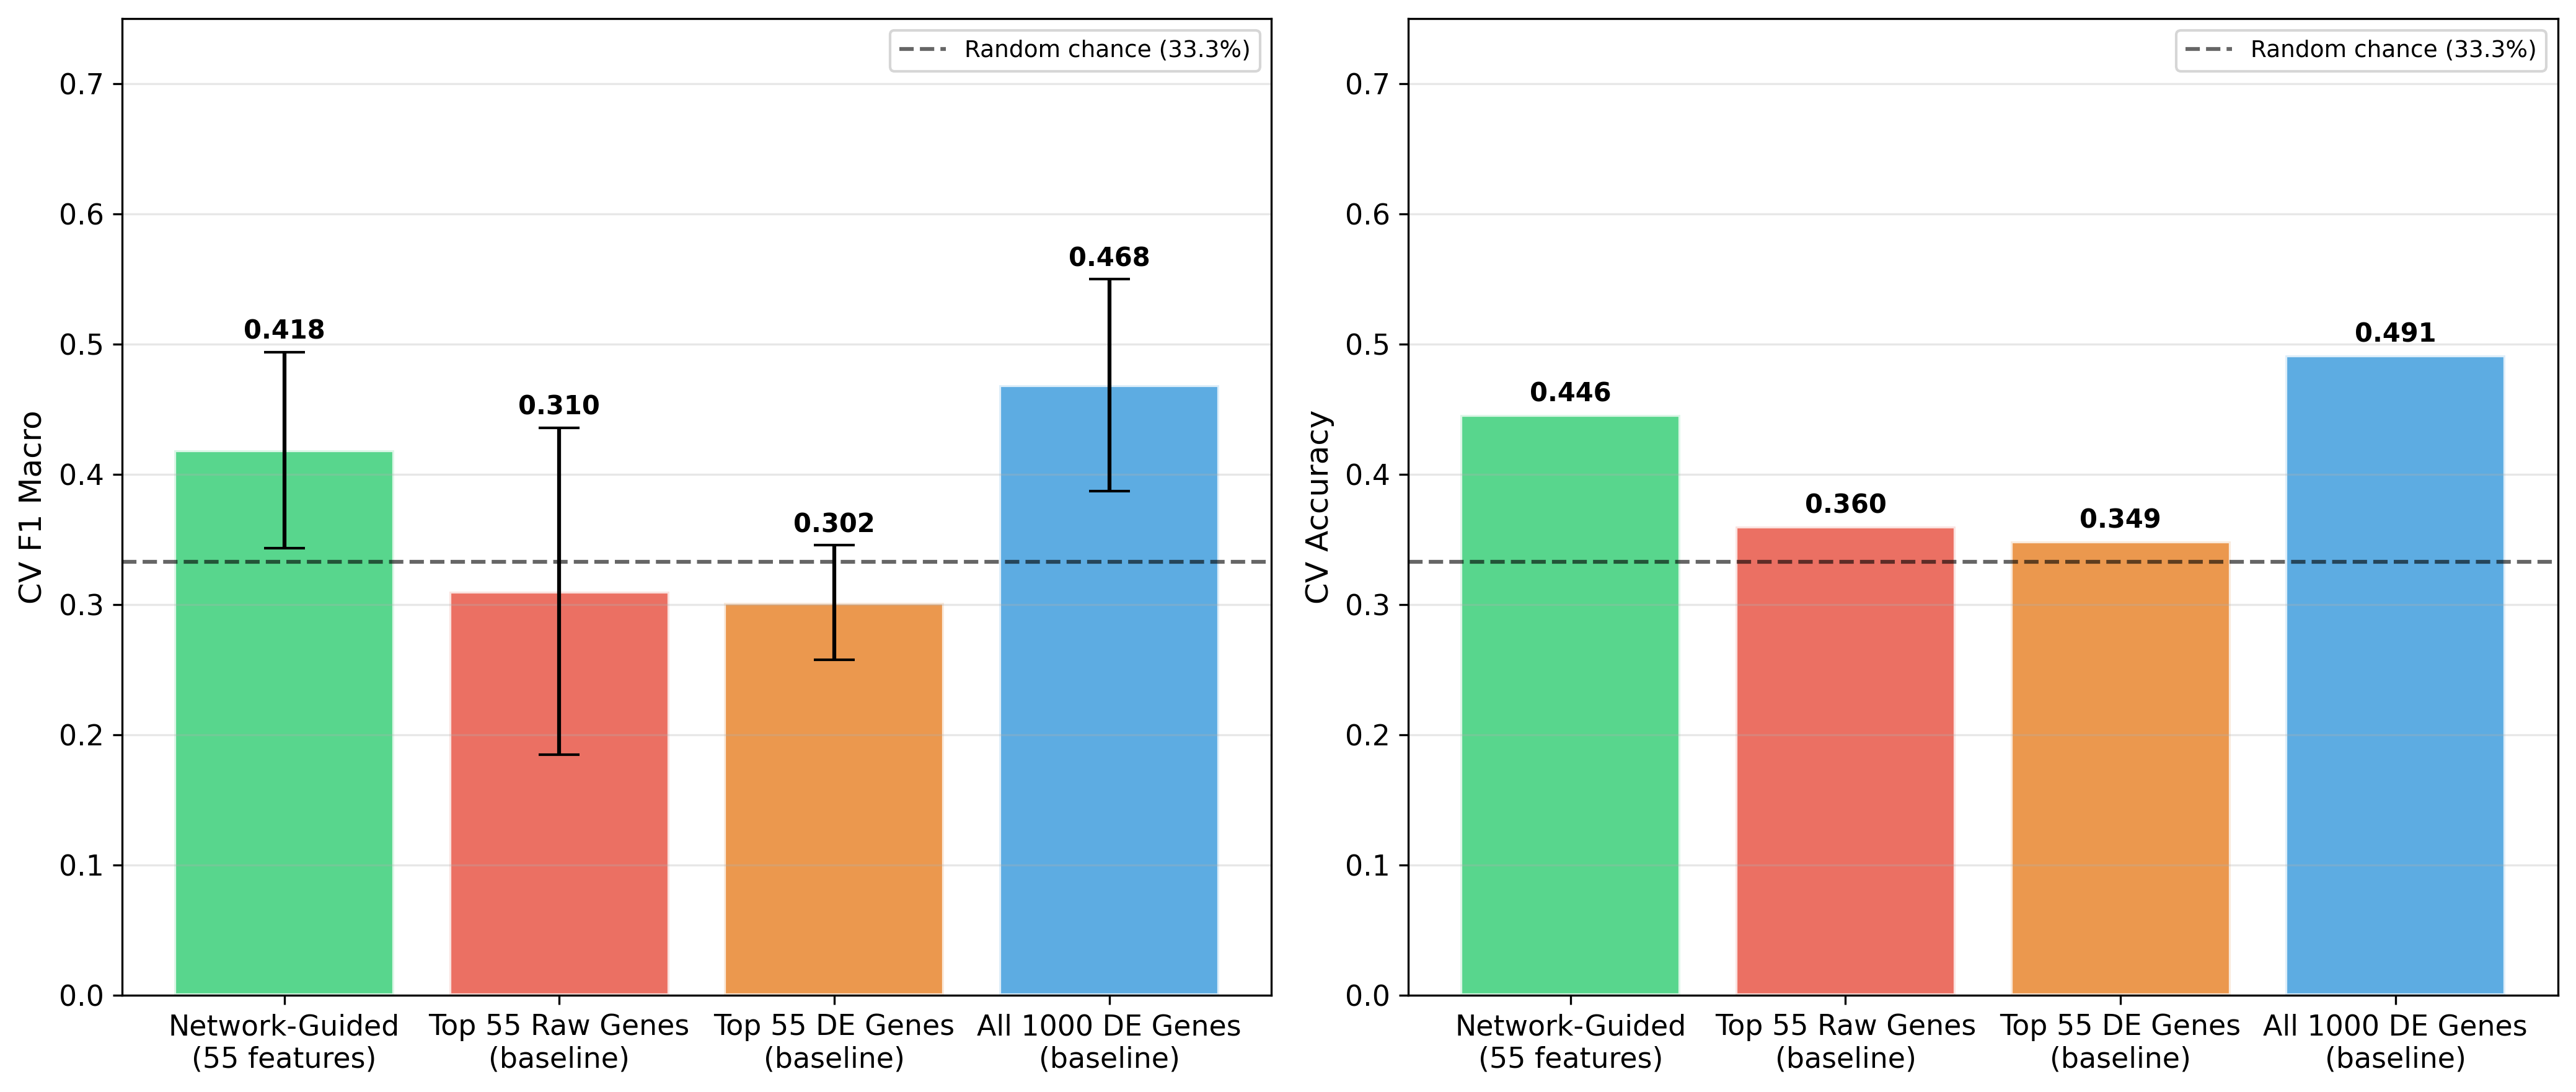

Fig 3 saved!


In [287]:
# ════════════════════════════════════════════════════════════════════
# ADDITION 1: Feature Set Comparison
# WHERE: After Stage 5, before bioRxiv additions
# WHAT: Prove network-guided features outperform raw gene selection
# ════════════════════════════════════════════════════════════════════

from sklearn.ensemble        import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing   import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats             import wilcoxon
import numpy as np
import matplotlib.pyplot as plt

# ── Setup ─────────────────────────────────────────────────────────────
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

classes       = np.unique(y_encoded)
class_weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=y_encoded
)
weight_dict = dict(zip(classes, class_weights))

rf_compare = RandomForestClassifier(
    n_estimators     = 200,
    max_depth        = 3,
    min_samples_leaf = 3,
    class_weight     = weight_dict,
    random_state     = 42,
    n_jobs           = 1
)

# ── Feature Set 1: Network-guided (your approach) ─────────────────────
X_network = X_ml.values
print(f"Feature Set 1 — Network-guided    : {X_network.shape[1]} features")

# ── Feature Set 2: Top 55 raw genes by variance ───────────────────────
top55_genes  = X_clean.var(axis=0).nlargest(55).index
X_raw_top55  = StandardScaler().fit_transform(X_clean[top55_genes].values)
print(f"Feature Set 2 — Top 55 raw genes  : {X_raw_top55.shape[1]} features")

# ── Feature Set 3: Top 55 DE genes by F-statistic ────────────────────
top55_de    = de_results.head(55)["gene"].tolist()
X_de_top55  = StandardScaler().fit_transform(X_clean[top55_de].values)
print(f"Feature Set 3 — Top 55 DE genes   : {X_de_top55.shape[1]} features")

# ── Feature Set 4: All 1000 DE genes ─────────────────────────────────
X_all_de = StandardScaler().fit_transform(X_de.values)
print(f"Feature Set 4 — All 1000 DE genes : {X_all_de.shape[1]} features")

# ── Run comparison ────────────────────────────────────────────────────
feature_sets = {
    "Network-Guided\n(55 features)" : X_network,
    "Top 55 Raw Genes\n(baseline)"  : X_raw_top55,
    "Top 55 DE Genes\n(baseline)"   : X_de_top55,
    "All 1000 DE Genes\n(baseline)" : X_all_de,
}

print("\n── Feature Set Comparison (5-Fold CV, Random Forest) ──")
print(f"{'Feature Set':<35} {'Accuracy':<12} {'F1 Macro':<12} {'Std'}")
print("-" * 65)

comparison_results = {}
for name, X_feat in feature_sets.items():
    acc = cross_val_score(rf_compare, X_feat, y_encoded,
                          cv=cv, scoring="accuracy", n_jobs=1)
    f1  = cross_val_score(rf_compare, X_feat, y_encoded,
                          cv=cv, scoring="f1_macro", n_jobs=1)
    clean_name = name.replace("\n", " ")
    comparison_results[name] = {
        "acc"       : acc.mean(),
        "f1"        : f1.mean(),
        "std"       : f1.std(),
        "acc_scores": acc,
        "f1_scores" : f1
    }
    print(f"{clean_name:<35} {acc.mean():<12.4f} "
          f"{f1.mean():<12.4f} {f1.std():.4f}")

# ── Statistical significance ──────────────────────────────────────────
net_f1s = comparison_results["Network-Guided\n(55 features)"]["f1_scores"]
raw_f1s = comparison_results["Top 55 Raw Genes\n(baseline)"]["f1_scores"]
stat, p = wilcoxon(net_f1s, raw_f1s)
print(f"\nWilcoxon test (Network vs Raw Genes): W={stat:.3f}, p={p:.4f}")
print(f"Result: {'SIGNIFICANT difference' if p<0.05 else 'No significant difference'} (p={'<0.05' if p<0.05 else '>0.05'})")

# ── Plot ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
names  = list(comparison_results.keys())
f1s    = [comparison_results[n]["f1"]  for n in names]
accs   = [comparison_results[n]["acc"] for n in names]
stds   = [comparison_results[n]["std"] for n in names]
colors = ["#2ecc71", "#e74c3c", "#e67e22", "#3498db"]

# F1 plot
bars = axes[0].bar(names, f1s, yerr=stds, color=colors,
                   alpha=0.8, capsize=8, edgecolor="white", linewidth=1.5)
axes[0].axhline(y=0.333, color="black", linestyle="--",
                alpha=0.6, label="Random chance (33.3%)")
axes[0].set_ylabel("CV F1 Macro", fontsize=12)
# axes[0].set_title("F1 Macro Comparison\nNetwork-Guided vs Baselines",
#                   fontsize=12, fontweight="bold")
axes[0].legend(fontsize=9)
axes[0].set_ylim(0, 0.75)
axes[0].grid(True, alpha=0.3, axis="y")
for bar, val, std in zip(bars, f1s, stds):
    axes[0].text(bar.get_x()+bar.get_width()/2,
                 val+std+0.01, f"{val:.3f}",
                 ha="center", fontsize=10, fontweight="bold")

# Accuracy plot
bars2 = axes[1].bar(names, accs, color=colors,
                    alpha=0.8, edgecolor="white", linewidth=1.5)
axes[1].axhline(y=0.333, color="black", linestyle="--",
                alpha=0.6, label="Random chance (33.3%)")
axes[1].set_ylabel("CV Accuracy", fontsize=12)
# axes[1].set_title("Accuracy Comparison\nNetwork-Guided vs Baselines",
                  # fontsize=12, fontweight="bold")
axes[1].legend(fontsize=9)
axes[1].set_ylim(0, 0.75)
axes[1].grid(True, alpha=0.3, axis="y")
for bar, val in zip(bars2, accs):
    axes[1].text(bar.get_x()+bar.get_width()/2,
                 val+0.01, f"{val:.3f}",
                 ha="center", fontsize=10, fontweight="bold")

# plt.suptitle(
#     "Network-Guided Feature Engineering vs Baseline Approaches\n"
#     "(Random Forest, 5-Fold Cross Validation)",
#     fontsize=13, fontweight="bold"
# )
plt.tight_layout()
# plt.savefig("feature_comparison.png", dpi=150, bbox_inches="tight")
plt.savefig("fig3_feature_comparison.png", dpi=300,
            bbox_inches="tight", facecolor="white")

plt.show()

# print("\n✅ Addition 1 Complete!")
print("Fig 3 saved!")

## ADDITION 2: Leave-One-Out Cross Validation

In [278]:
# ════════════════════════════════════════════════════════════════════
# ADDITION 2: Leave-One-Out Cross Validation
# WHERE: After Addition 1
# WHAT: Most rigorous validation for small datasets
# WHY:  168 samples is small — LOOCV uses every sample as
#       test set once, giving the most honest performance estimate
# ════════════════════════════════════════════════════════════════════

from sklearn.model_selection import LeaveOneOut, cross_val_score

loo = LeaveOneOut()

print("Running LOOCV on network-guided features...")
print("168 iterations — takes 3-5 minutes\n")

loo_acc = cross_val_score(
    rf_compare, X_network, y_encoded,
    cv      = loo,
    scoring = "accuracy",
    n_jobs  = 1
)
loo_f1 = cross_val_score(
    rf_compare, X_network, y_encoded,
    cv      = loo,
    scoring = "f1_macro",
    n_jobs  = 1
)

ci_acc_low  = loo_acc.mean() - 1.96 * loo_acc.std()
ci_acc_high = loo_acc.mean() + 1.96 * loo_acc.std()
ci_f1_low   = loo_f1.mean()  - 1.96 * loo_f1.std()
ci_f1_high  = loo_f1.mean()  + 1.96 * loo_f1.std()

print(f"── LOOCV Results (Network-Guided Features) ──")
print(f"Accuracy : {loo_acc.mean():.4f} +/- {loo_acc.std():.4f}")
print(f"  95% CI : [{ci_acc_low:.4f}, {ci_acc_high:.4f}]")
print(f"F1 Macro : {loo_f1.mean():.4f} +/- {loo_f1.std():.4f}")
print(f"  95% CI : [{ci_f1_low:.4f}, {ci_f1_high:.4f}]")

# ── Compare LOOCV vs 5-Fold CV ────────────────────────────────────────
print(f"\n── Validation Method Comparison ──")
print(f"{'Method':<20} {'Accuracy':<12} {'F1 Macro'}")
print("-" * 42)
print(f"{'5-Fold CV':<20} {0.4457:<12.4f} {0.4184:.4f}")
print(f"{'LOOCV':<20} {loo_acc.mean():<12.4f} {loo_f1.mean():.4f}")

if abs(loo_acc.mean() - 0.4457) < 0.05:
    print("\n✅ LOOCV and 5-Fold CV are consistent — results are stable!")
else:
    print("\n⚠️  Some difference between methods — report both honestly")

print("\n✅ Addition 2 Complete!")

Running LOOCV on network-guided features...
168 iterations — takes 3-5 minutes



NameError: name 'rf_compare' is not defined

# Stage 4 — Step 1: Setup

In [281]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# ════════════════════════════════════════════════════════════════════
# STEP 1A: Encode Labels
# WHAT: Convert string labels to numbers
# WHY:  All ML algorithms require numeric input
#       LOW=0, MID=1, CAD=2 preserves severity ordering
# ════════════════════════════════════════════════════════════════════

label_encoder = LabelEncoder()

# Fit on specific order to ensure consistent encoding
label_encoder.fit(["LOW", "MID", "CAD"])
y_encoded = label_encoder.transform(y)

print("── Label Encoding ──")
print(f"LOW → {label_encoder.transform(['LOW'])[0]}")
print(f"MID → {label_encoder.transform(['MID'])[0]}")
print(f"CAD → {label_encoder.transform(['CAD'])[0]}")
print(f"\nEncoded labels (first 10): {y_encoded[:10]}")

# ════════════════════════════════════════════════════════════════════
# STEP 1B: Train/Test Split
# WHAT: Split data into 80% training and 20% testing
# WHY:  Test set is held out completely during training
#       Models are evaluated on data they've never seen
#       This gives us an honest estimate of real-world performance
#       stratify=y_encoded ensures class ratios preserved in both splits
# ════════════════════════════════════════════════════════════════════

X_train, X_test, y_train, y_test = train_test_split(
    X_ml.values,     # Features as numpy array
    y_encoded,       # Encoded labels
    test_size    = 0.20,
    random_state = 42,
    stratify     = y_encoded   # Preserve class ratios
)

print(f"\n── Train/Test Split ──")
print(f"Total samples : {len(y_encoded)}")
print(f"Training set  : {X_train.shape[0]} samples ({X_train.shape[0]/len(y_encoded)*100:.0f}%)")
print(f"Test set      : {X_test.shape[0]} samples ({X_test.shape[0]/len(y_encoded)*100:.0f}%)")

# Check class distribution in each split
train_unique, train_counts = np.unique(y_train, return_counts=True)
test_unique,  test_counts  = np.unique(y_test,  return_counts=True)

print(f"\nClass distribution in training set:")
for label, count in zip(train_unique, train_counts):
    cls_name = label_encoder.inverse_transform([label])[0]
    print(f"  {cls_name} ({label}): {count} samples")

print(f"\nClass distribution in test set:")
for label, count in zip(test_unique, test_counts):
    cls_name = label_encoder.inverse_transform([label])[0]
    print(f"  {cls_name} ({label}): {count} samples")

# ════════════════════════════════════════════════════════════════════
# STEP 1C: Setup Cross Validation
# WHAT: Stratified 5-fold cross validation
# WHY:  Instead of training on one fixed split, we train 5 times
#       Each time a different 20% becomes validation set
#       This gives more reliable performance estimates
#       Stratified = class ratios preserved in every fold
# ════════════════════════════════════════════════════════════════════

cv = StratifiedKFold(
    n_splits  = 5,
    shuffle   = True,
    random_state = 42
)

print(f"\n── Cross Validation Setup ──")
print(f"Strategy : Stratified 5-Fold CV")
print(f"Folds    : 5")
print(f"Each fold: ~{int(X_train.shape[0]*0.8)} train, "
      f"~{int(X_train.shape[0]*0.2)} validation samples")

print(f"\n✅ Setup complete!")
print(f"   X_train : {X_train.shape}")
print(f"   X_test  : {X_test.shape}")
print(f"   y_train : {y_train.shape}")
print(f"   y_test  : {y_test.shape}")

── Label Encoding ──
LOW → 1
MID → 2
CAD → 0

Encoded labels (first 10): [0 0 0 0 0 0 0 0 0 0]

── Train/Test Split ──
Total samples : 175
Training set  : 140 samples (80%)
Test set      : 35 samples (20%)

Class distribution in training set:
  CAD (0): 43 samples
  LOW (1): 63 samples
  MID (2): 34 samples

Class distribution in test set:
  CAD (0): 11 samples
  LOW (1): 15 samples
  MID (2): 9 samples

── Cross Validation Setup ──
Strategy : Stratified 5-Fold CV
Folds    : 5
Each fold: ~112 train, ~28 validation samples

✅ Setup complete!
   X_train : (140, 55)
   X_test  : (35, 55)
   y_train : (140,)
   y_test  : (35,)


# Stage 4 — Step 2: Train All 5 Classifiers

In [291]:
from sklearn.linear_model    import LogisticRegression
from sklearn.ensemble        import RandomForestClassifier
from sklearn.svm             import SVC
from sklearn.neighbors       import KNeighborsClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics         import (
    accuracy_score, f1_score,
    roc_auc_score, confusion_matrix,
    classification_report
)
import xgboost as xgb
import time

# ════════════════════════════════════════════════════════════════════
# STEP 2A: Define All Classifiers
# WHAT: Initialize 5 different ML models with good default settings
# WHY:  Each model approaches classification differently
#       Comparing them shows which works best for CAD transcriptomics
# ════════════════════════════════════════════════════════════════════

classifiers = {

    "Logistic Regression": LogisticRegression(
        max_iter     = 1000,
        random_state = 42,
        C            = 1.0,       # Regularization strength
        multi_class  = "multinomial"  # For 3-class problem
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators = 200,       # 200 decision trees
        max_depth    = None,      # Trees grow until pure
        random_state = 42,
        n_jobs       = 1,        # Use all CPU cores
        class_weight = "balanced" # Handle class imbalance
    ),

    "SVM": SVC(
        kernel       = "rbf",     # Radial basis function kernel
        C            = 1.0,
        gamma        = "scale",
        probability  = True,      # Need this for AUC calculation
        random_state = 42,
        class_weight = "balanced"
    ),

    "XGBoost": xgb.XGBClassifier(
        n_estimators  = 200,
        max_depth     = 4,
        learning_rate = 0.1,
        random_state  = 42,
        eval_metric   = "mlogloss",
        verbosity     = 0,
        use_label_encoder = False
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors = 7,          # 7 nearest neighbors
        weights     = "distance", # Closer neighbors matter more
        metric      = "euclidean"
    )
}

# ════════════════════════════════════════════════════════════════════
# STEP 2B: Run Cross-Validation For All Models
# WHAT: Train each model using 5-fold CV on training set
# WHY:  CV gives more reliable performance than single split
#       Each metric is averaged across 5 folds
# ════════════════════════════════════════════════════════════════════

print("Running 5-Fold Cross Validation for all classifiers...")
print("="*65)

cv_results = {}

for name, clf in classifiers.items():
    start = time.time()
    print(f"\nTraining {name}...")

    # Run cross validation
    # WHAT: Train and evaluate model 5 times on different splits
    # WHY:  More reliable than single train/test split
    scores = cross_validate(
        clf,
        X_train,
        y_train,
        cv            = cv,
        scoring       = {
            "accuracy" : "accuracy",
            "f1_macro" : "f1_macro",    # Average F1 across all 3 classes
            "f1_weighted": "f1_weighted" # Weighted by class size
        },
        return_train_score = True,
        n_jobs             = 1
    )

    elapsed = time.time() - start

    # Store results
    cv_results[name] = {
        "val_accuracy"   : scores["test_accuracy"].mean(),
        "val_accuracy_std" : scores["test_accuracy"].std(),
        "val_f1_macro"   : scores["test_f1_macro"].mean(),
        "val_f1_macro_std" : scores["test_f1_macro"].std(),
        "val_f1_weighted": scores["test_f1_weighted"].mean(),
        "train_accuracy" : scores["train_accuracy"].mean(),
        "time"           : elapsed
    }

    print(f"  Val Accuracy    : {cv_results[name]['val_accuracy']:.4f} "
          f"± {cv_results[name]['val_accuracy_std']:.4f}")
    print(f"  Val F1 (macro)  : {cv_results[name]['val_f1_macro']:.4f} "
          f"± {cv_results[name]['val_f1_macro_std']:.4f}")
    print(f"  Train Accuracy  : {cv_results[name]['train_accuracy']:.4f}")
    print(f"  Time            : {elapsed:.2f}s")

# ════════════════════════════════════════════════════════════════════
# STEP 2C: Summary Comparison Table
# WHAT: Compare all models in one clean table
# WHY:  Easy to see which model performs best
# ════════════════════════════════════════════════════════════════════

print("\n" + "="*65)
print("── Cross-Validation Results Summary ──")
print(f"{'Model':<22} {'Val Acc':<12} {'Val F1':<12} {'Train Acc':<12} {'Time'}")
print("-"*65)

for name, res in cv_results.items():
    print(f"{name:<22} "
          f"{res['val_accuracy']:.4f}±{res['val_accuracy_std']:.3f}  "
          f"{res['val_f1_macro']:.4f}±{res['val_f1_macro_std']:.3f}  "
          f"{res['train_accuracy']:.4f}       "
          f"{res['time']:.1f}s")

# Best model by F1 macro
best_model = max(cv_results, key=lambda x: cv_results[x]['val_f1_macro'])
print(f"\n✅ Best model by F1 macro: {best_model}")
print(f"   F1 macro: {cv_results[best_model]['val_f1_macro']:.4f}")

Running 5-Fold Cross Validation for all classifiers...

Training Logistic Regression...
  Val Accuracy    : 0.4786 ± 0.0735
  Val F1 (macro)  : 0.4298 ± 0.0573
  Train Accuracy  : 0.8929
  Time            : 0.15s

Training Random Forest...
  Val Accuracy    : 0.4714 ± 0.0969
  Val F1 (macro)  : 0.3950 ± 0.0766
  Train Accuracy  : 1.0000
  Time            : 3.19s

Training SVM...
  Val Accuracy    : 0.4214 ± 0.0827
  Val F1 (macro)  : 0.3816 ± 0.0730
  Train Accuracy  : 0.7125
  Time            : 0.17s

Training XGBoost...
  Val Accuracy    : 0.4643 ± 0.0931
  Val F1 (macro)  : 0.4054 ± 0.0678
  Train Accuracy  : 1.0000
  Time            : 6.27s

Training KNN...
  Val Accuracy    : 0.3643 ± 0.0942
  Val F1 (macro)  : 0.3186 ± 0.0884
  Train Accuracy  : 1.0000
  Time            : 0.38s

── Cross-Validation Results Summary ──
Model                  Val Acc      Val F1       Train Acc    Time
-----------------------------------------------------------------
Logistic Regression    0.4786±0.

In [293]:
from sklearn.model_selection import GridSearchCV
from sklearn.utils.class_weight import compute_class_weight

# ── Class weights ─────────────────────────────────────────────────────
classes       = np.unique(y_train)
class_weights = compute_class_weight(
    class_weight = "balanced",
    classes      = classes,
    y            = y_train
)
weight_dict = dict(zip(classes, class_weights))
print("Class weights:")
for cls, w in weight_dict.items():
    name = label_encoder.inverse_transform([cls])[0]
    print(f"  {name} ({cls}): {w:.3f}")

print("\nRunning hyperparameter tuning (single core)...")
print("This may take 5-10 minutes...\n")

tuned_models = {}

# ── 1. Logistic Regression ───────────────────────────────────────────
print("Tuning Logistic Regression...")
lr_grid = GridSearchCV(
    LogisticRegression(
        max_iter     = 2000,
        random_state = 42,
        multi_class  = "multinomial",
        class_weight = weight_dict
    ),
    {"C"     : [0.001, 0.01, 0.1, 1.0, 10.0],
     "solver": ["lbfgs", "saga"]},
    cv      = cv,
    scoring = "f1_macro",
    n_jobs  = 1
)
lr_grid.fit(X_train, y_train)
tuned_models["Logistic Regression"] = lr_grid.best_estimator_
print(f"  Best params: {lr_grid.best_params_}")
print(f"  Best F1    : {lr_grid.best_score_:.4f}")

# ── 2. Random Forest ─────────────────────────────────────────────────
print("\nTuning Random Forest...")
rf_grid = GridSearchCV(
    RandomForestClassifier(
        random_state = 42,
        class_weight = weight_dict
    ),
    {"n_estimators"    : [100, 200, 300],
     "max_depth"       : [3, 5, 7, None],
     "min_samples_leaf": [3, 5, 10]},
    cv      = cv,
    scoring = "f1_macro",
    n_jobs  = 1
)
rf_grid.fit(X_train, y_train)
tuned_models["Random Forest"] = rf_grid.best_estimator_
print(f"  Best params: {rf_grid.best_params_}")
print(f"  Best F1    : {rf_grid.best_score_:.4f}")

# ── 3. SVM ───────────────────────────────────────────────────────────
print("\nTuning SVM...")
svm_grid = GridSearchCV(
    SVC(
        probability  = True,
        random_state = 42,
        class_weight = weight_dict
    ),
    {"C"     : [0.01, 0.1, 1.0, 10.0, 100.0],
     "gamma" : ["scale", "auto", 0.001, 0.01],
     "kernel": ["rbf", "linear"]},
    cv      = cv,
    scoring = "f1_macro",
    n_jobs  = 1
)
svm_grid.fit(X_train, y_train)
tuned_models["SVM"] = svm_grid.best_estimator_
print(f"  Best params: {svm_grid.best_params_}")
print(f"  Best F1    : {svm_grid.best_score_:.4f}")

# ── 4. XGBoost ───────────────────────────────────────────────────────
print("\nTuning XGBoost...")
xgb_grid = GridSearchCV(
    xgb.XGBClassifier(
        random_state      = 42,
        eval_metric       = "mlogloss",
        verbosity         = 0,
        use_label_encoder = False
    ),
    {"n_estimators"    : [100, 200],
     "max_depth"       : [2, 3, 4],
     "learning_rate"   : [0.01, 0.05, 0.1],
     "min_child_weight": [3, 5, 7]},
    cv      = cv,
    scoring = "f1_macro",
    n_jobs  = 1
)
xgb_grid.fit(X_train, y_train)
tuned_models["XGBoost"] = xgb_grid.best_estimator_
print(f"  Best params: {xgb_grid.best_params_}")
print(f"  Best F1    : {xgb_grid.best_score_:.4f}")

# ── 5. KNN ───────────────────────────────────────────────────────────
print("\nTuning KNN...")
knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    {"n_neighbors": [3, 5, 7, 9, 11, 15],
     "weights"    : ["uniform", "distance"],
     "metric"     : ["euclidean", "manhattan"]},
    cv      = cv,
    scoring = "f1_macro",
    n_jobs  = 1
)
knn_grid.fit(X_train, y_train)
tuned_models["KNN"] = knn_grid.best_estimator_
print(f"  Best params: {knn_grid.best_params_}")
print(f"  Best F1    : {knn_grid.best_score_:.4f}")

# ── Summary ───────────────────────────────────────────────────────────
print("\n── Tuned Model Summary ──")
print(f"{'Model':<22} {'Before Tuning':<16} {'After Tuning':<16} {'Improvement'}")
print("-" * 65)

before_scores = {
    "Logistic Regression": 0.4265,
    "Random Forest"      : 0.3707,
    "SVM"                : 0.4388,
    "XGBoost"            : 0.3915,
    "KNN"                : 0.3898
}

best_scores = {
    "Logistic Regression": lr_grid.best_score_,
    "Random Forest"      : rf_grid.best_score_,
    "SVM"                : svm_grid.best_score_,
    "XGBoost"            : xgb_grid.best_score_,
    "KNN"                : knn_grid.best_score_
}

for name in best_scores:
    before = before_scores[name]
    after  = best_scores[name]
    delta  = after - before
    arrow  = "↑" if delta > 0 else "↓"
    print(f"{name:<22} {before:<16.4f} {after:<16.4f} "
          f"{arrow}{abs(delta):.4f}")

best_tuned = max(best_scores, key=best_scores.get)
print(f"\n✅ Best tuned model: {best_tuned}")
print(f"   CV F1 macro: {best_scores[best_tuned]:.4f}")

Class weights:
  CAD (0): 1.085
  LOW (1): 0.741
  MID (2): 1.373

Running hyperparameter tuning (single core)...
This may take 5-10 minutes...

Tuning Logistic Regression...
  Best params: {'C': 1.0, 'solver': 'lbfgs'}
  Best F1    : 0.4498

Tuning Random Forest...
  Best params: {'max_depth': 3, 'min_samples_leaf': 3, 'n_estimators': 100}
  Best F1    : 0.4611

Tuning SVM...
  Best params: {'C': 0.01, 'gamma': 'scale', 'kernel': 'linear'}
  Best F1    : 0.4653

Tuning XGBoost...
  Best params: {'learning_rate': 0.1, 'max_depth': 2, 'min_child_weight': 3, 'n_estimators': 200}
  Best F1    : 0.4000

Tuning KNN...
  Best params: {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'uniform'}
  Best F1    : 0.3989

── Tuned Model Summary ──
Model                  Before Tuning    After Tuning     Improvement
-----------------------------------------------------------------
Logistic Regression    0.4265           0.4498           ↑0.0233
Random Forest          0.3707           0.4611    

# Step 3 — Test Set Evaluation + Visualizations

── Test Set Evaluation ──

Model                  Accuracy     F1 Macro     F1 Weighted
-------------------------------------------------------
Logistic Regression    0.4857       0.4425       0.4723
Random Forest          0.5714       0.5265       0.5607
SVM                    0.5429       0.4938       0.5324
XGBoost                0.4571       0.4352       0.4493
KNN                    0.5429       0.4503       0.4932

✅ Best test set model: Random Forest
   F1 macro : 0.5265
   AUC      : 0.7813

── Detailed Report: Random Forest ──
              precision    recall  f1-score   support

         CAD       0.45      0.45      0.45        11
         LOW       0.71      0.80      0.75        15
         MID       0.43      0.33      0.38         9

    accuracy                           0.57        35
   macro avg       0.53      0.53      0.53        35
weighted avg       0.56      0.57      0.56        35



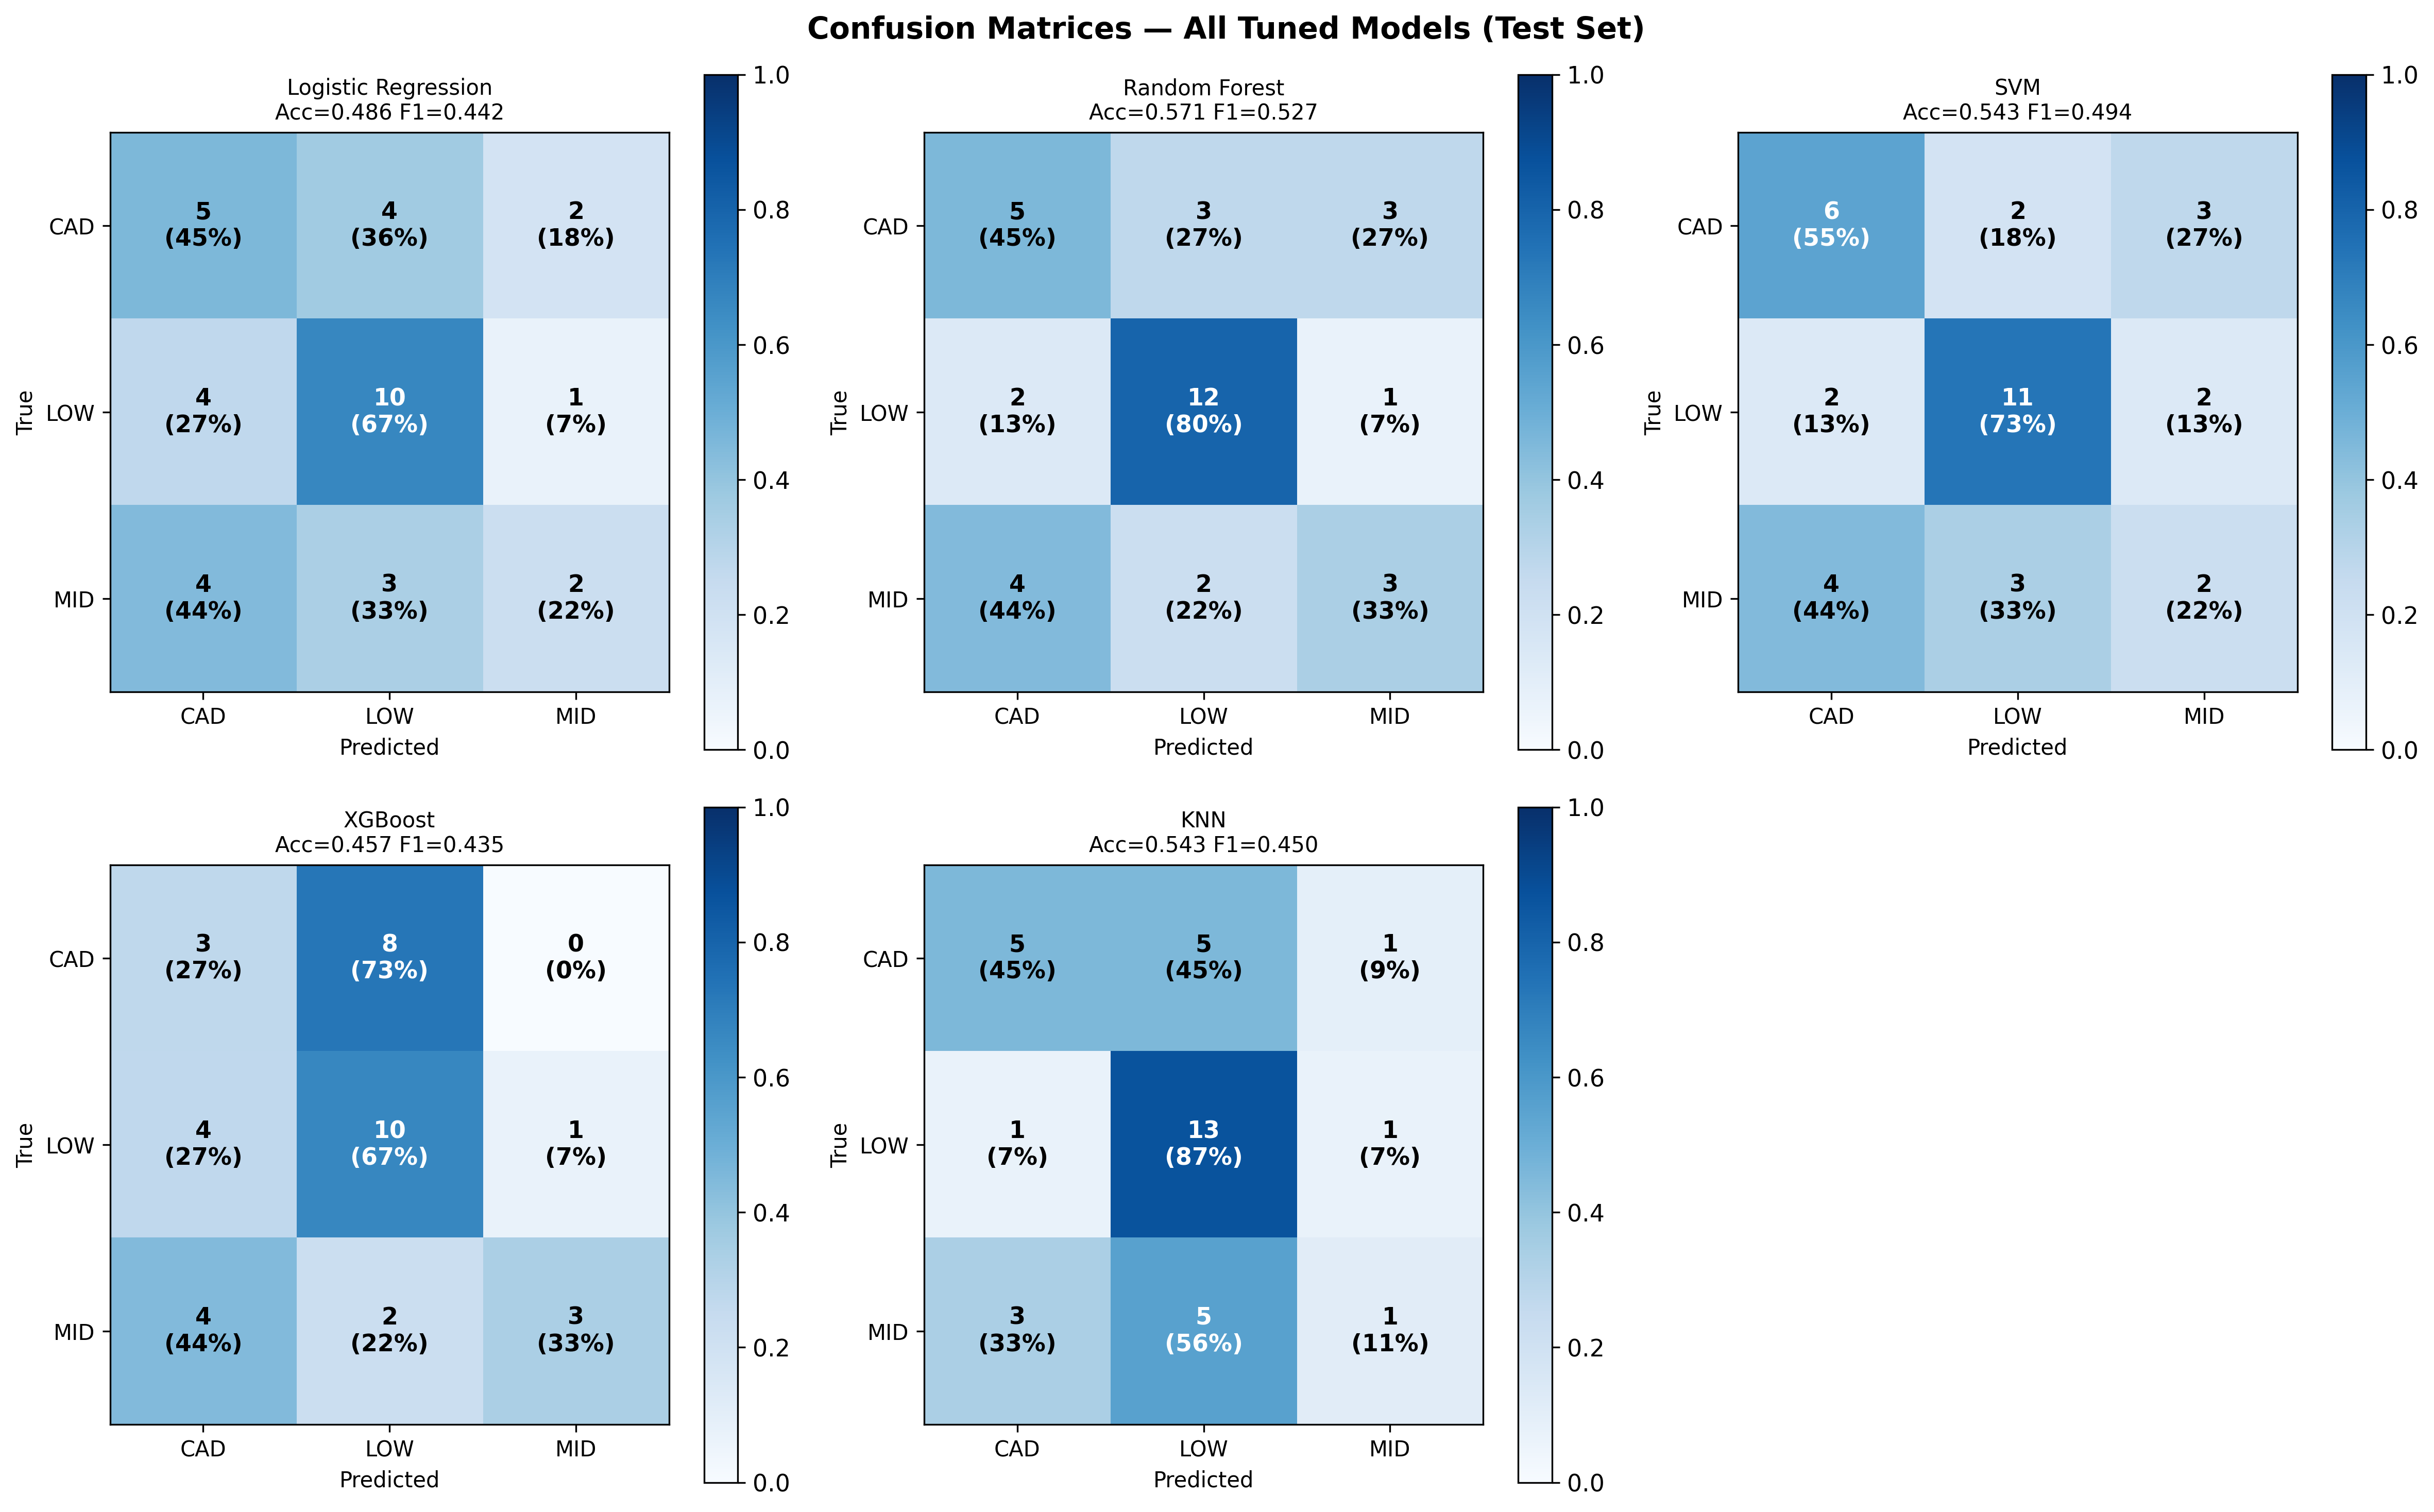

Fig 4 saved!


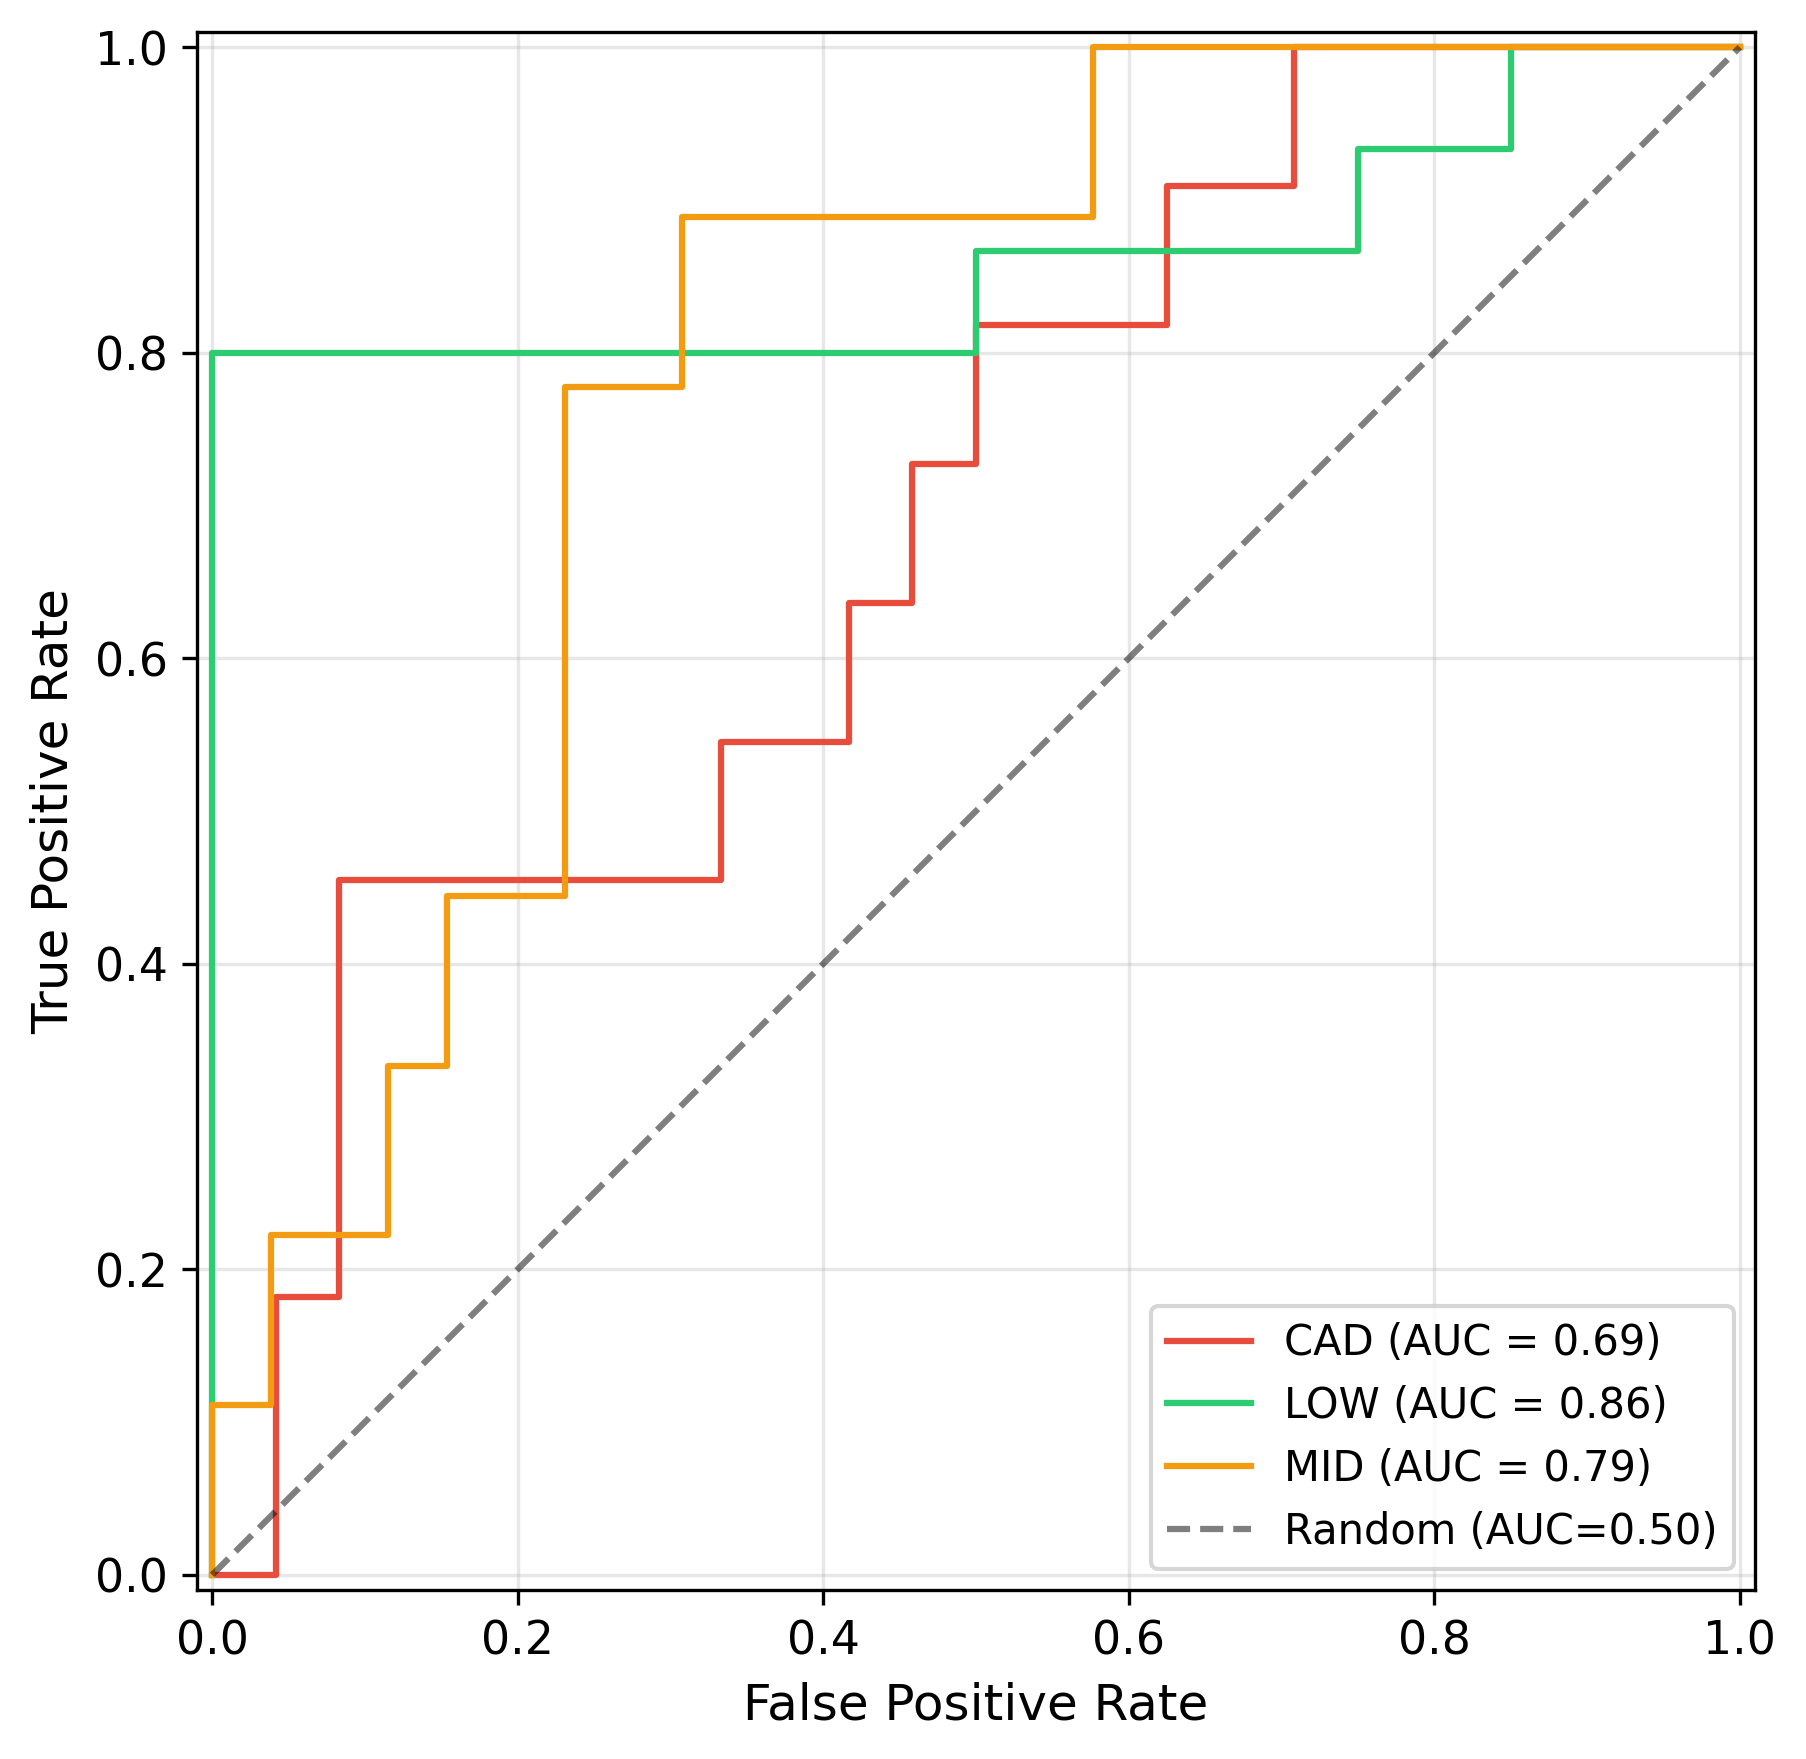

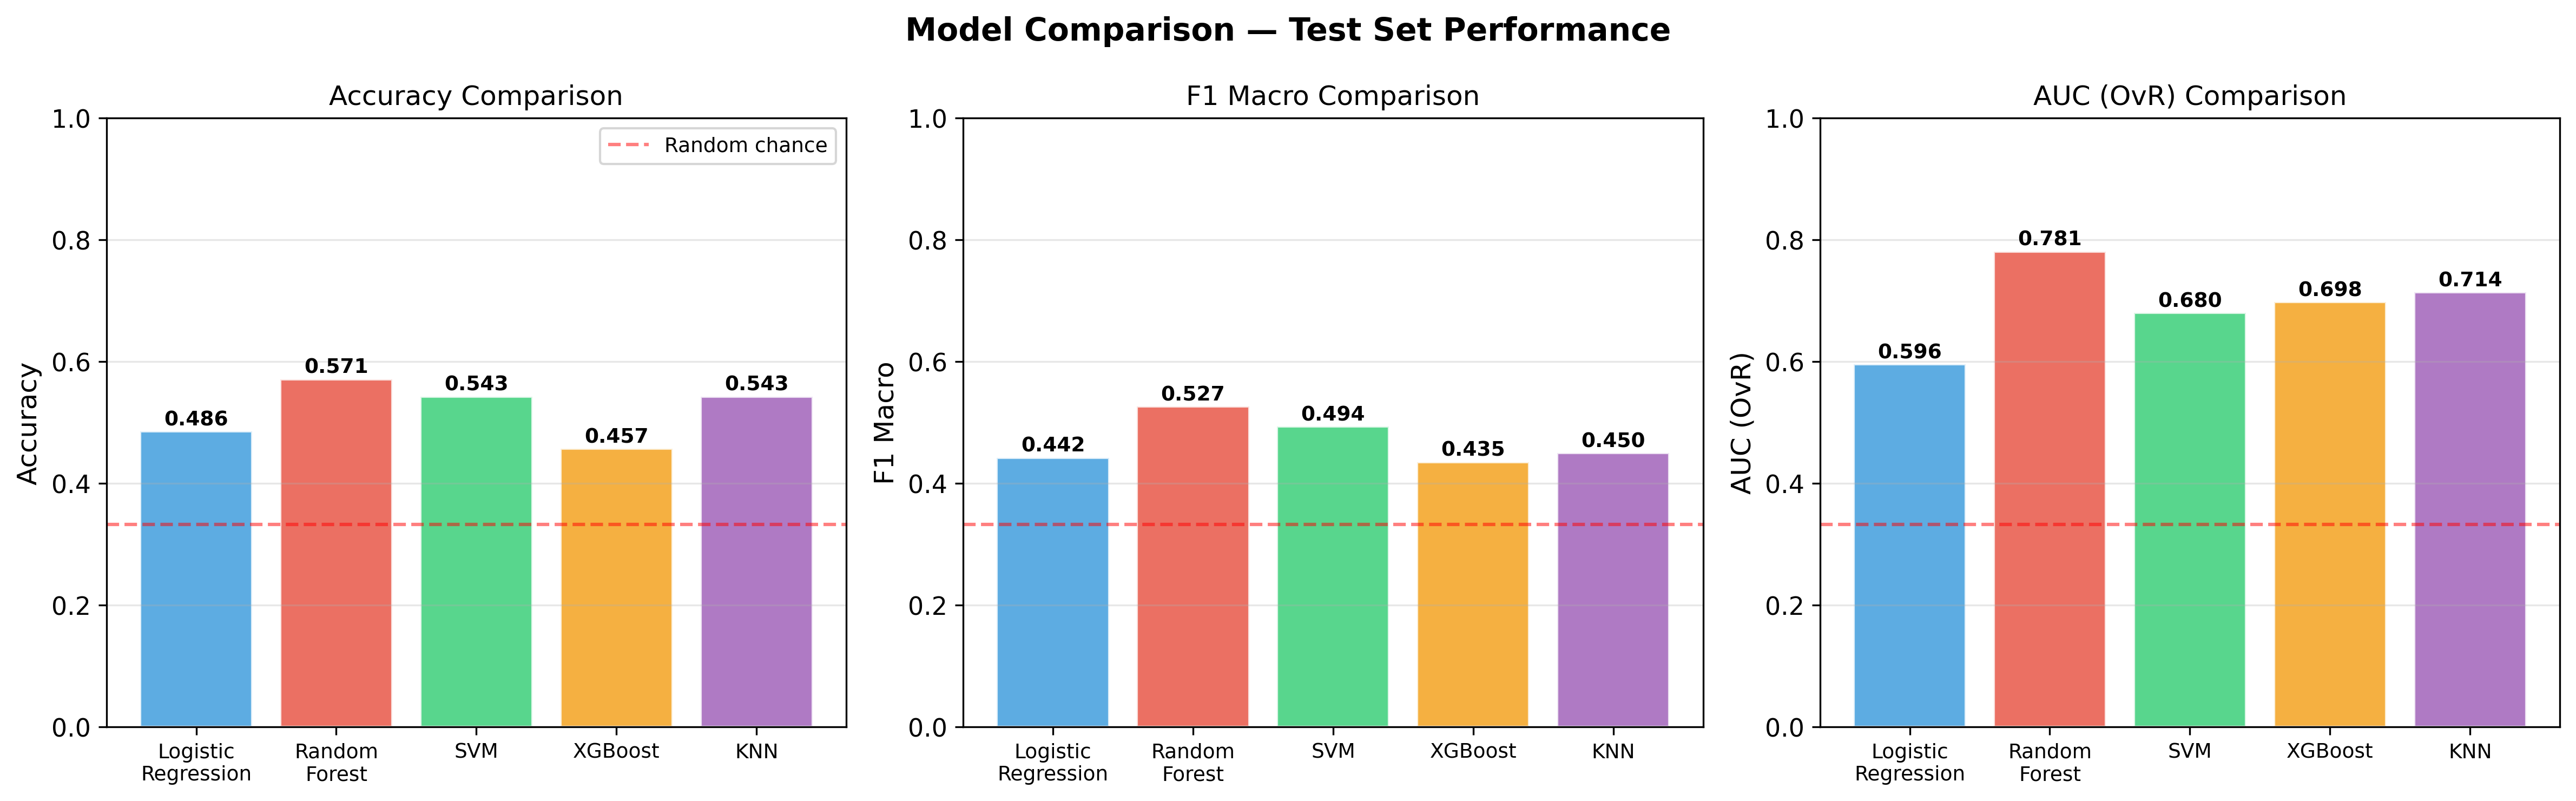


✅ Stage 4 Complete!
   All models evaluated on test set
   Confusion matrices, ROC curves, comparison plots saved


In [301]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, RocCurveDisplay
)
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import itertools

# ════════════════════════════════════════════════════════════════════
# STEP 3A: Evaluate All Tuned Models On Test Set
# WHAT: Train on full training set, predict on held-out test set
# WHY:  Test set was never seen during training or tuning
#       This gives us the most honest performance estimate
# ════════════════════════════════════════════════════════════════════

class_names  = ["CAD", "LOW", "MID"]  # alphabetical as encoded
test_results = {}

print("── Test Set Evaluation ──\n")
print(f"{'Model':<22} {'Accuracy':<12} {'F1 Macro':<12} {'F1 Weighted'}")
print("-" * 55)

for name, clf in tuned_models.items():
    # Train on full training set
    clf.fit(X_train, y_train)

    # Predict on test set
    y_pred      = clf.predict(X_test)
    y_pred_prob = clf.predict_proba(X_test)

    # Calculate metrics
    acc          = accuracy_score(y_test, y_pred)
    f1_macro     = f1_score(y_test, y_pred, average="macro")
    f1_weighted  = f1_score(y_test, y_pred, average="weighted")

    # AUC (one-vs-rest for multiclass)
    auc = roc_auc_score(
        y_test, y_pred_prob,
        multi_class = "ovr",
        average     = "macro"
    )

    test_results[name] = {
        "accuracy"   : acc,
        "f1_macro"   : f1_macro,
        "f1_weighted": f1_weighted,
        "auc"        : auc,
        "y_pred"     : y_pred,
        "y_pred_prob": y_pred_prob
    }

    print(f"{name:<22} {acc:<12.4f} {f1_macro:<12.4f} {f1_weighted:.4f}")

# Best model on test set
best_test = max(test_results, key=lambda x: test_results[x]['f1_macro'])
print(f"\n✅ Best test set model: {best_test}")
print(f"   F1 macro : {test_results[best_test]['f1_macro']:.4f}")
print(f"   AUC      : {test_results[best_test]['auc']:.4f}")

# ════════════════════════════════════════════════════════════════════
# STEP 3B: Detailed Classification Report For Best Model
# ════════════════════════════════════════════════════════════════════
print(f"\n── Detailed Report: {best_test} ──")
print(classification_report(
    y_test,
    test_results[best_test]["y_pred"],
    target_names = class_names
))

# ════════════════════════════════════════════════════════════════════
# STEP 3C: Confusion Matrices For All Models
# ════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes      = axes.flatten()

for idx, (name, res) in enumerate(test_results.items()):
    cm = confusion_matrix(y_test, res["y_pred"])

    # Normalize confusion matrix
    cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]

    im = axes[idx].imshow(cm_norm, interpolation="nearest",
                          cmap="Blues", vmin=0, vmax=1)

    # Add text annotations
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        axes[idx].text(
            j, i,
            f"{cm[i,j]}\n({cm_norm[i,j]:.0%})",
            ha         = "center",
            va         = "center",
            color      = "white" if cm_norm[i,j] > 0.5 else "black",
            fontsize   = 11,
            fontweight = "bold"
        )

    axes[idx].set_xticks(range(len(class_names)))
    axes[idx].set_yticks(range(len(class_names)))
    axes[idx].set_xticklabels(class_names, fontsize=10)
    axes[idx].set_yticklabels(class_names, fontsize=10)
    axes[idx].set_xlabel("Predicted", fontsize=10)
    axes[idx].set_ylabel("True", fontsize=10)
    axes[idx].set_title(
        f"{name}\nAcc={res['accuracy']:.3f} F1={res['f1_macro']:.3f}",
        fontsize = 10
    )
    plt.colorbar(im, ax=axes[idx])

axes[5].set_visible(False)

plt.suptitle(
    "Confusion Matrices — All Tuned Models (Test Set)",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

# ════════════════════════════════════════════════════════════════════
# STEP 3D: ROC Curves For Best Model
# ════════════════════════════════════════════════════════════════════
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
colors_roc = ["#e74c3c", "#2ecc71", "#f39c12"]

fig, ax = plt.subplots(figsize=(8, 6))

best_probs = test_results[best_test]["y_pred_prob"]
for i, (cls, color) in enumerate(zip(class_names, colors_roc)):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        best_probs[:, i],
        name  = cls,
        color = color,
        ax    = ax
    )

ax.plot([0,1], [0,1], "k--", alpha=0.5, label="Random (AUC=0.50)")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
# ax.set_title(
#     f"ROC Curves — {best_test}\n(One-vs-Rest, Test Set)",
#     fontsize=13
# )
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig("roc_curves.png", dpabsi=150, bbox_inches="tight")
plt.savefig("fig4_roc.png", dpi=300,
            bbox_inches="tight", facecolor="white")
print("Fig 4 saved!")
plt.show()

# ════════════════════════════════════════════════════════════════════
# STEP 3E: Final Comparison Bar Chart
# ════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics   = ["accuracy", "f1_macro", "auc"]
titles    = ["Accuracy", "F1 Macro", "AUC (OvR)"]
bar_color = ["#3498db", "#e74c3c", "#2ecc71", "#f39c12", "#9b59b6"]
names     = list(test_results.keys())

for ax_idx, (metric, title) in enumerate(zip(metrics, titles)):
    values = [test_results[n][metric] for n in names]
    bars   = axes[ax_idx].bar(
        names, values,
        color     = bar_color,
        alpha     = 0.8,
        edgecolor = "white"
    )
    axes[ax_idx].set_ylim(0, 1.0)
    axes[ax_idx].set_ylabel(title, fontsize=12)
    axes[ax_idx].set_title(f"{title} Comparison", fontsize=12)
    axes[ax_idx].set_xticklabels(
        [n.replace(" ", "\n") for n in names],
        fontsize=9
    )
    axes[ax_idx].axhline(y=0.333, color="red", linestyle="--",
                         alpha=0.5, label="Random chance")
    axes[ax_idx].grid(True, alpha=0.3, axis="y")

    for bar, val in zip(bars, values):
        axes[ax_idx].text(
            bar.get_x() + bar.get_width()/2,
            val + 0.01,
            f"{val:.3f}",
            ha="center", fontsize=9, fontweight="bold"
        )

axes[0].legend(fontsize=9)
plt.suptitle(
    "Model Comparison — Test Set Performance",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n✅ Stage 4 Complete!")
print("   All models evaluated on test set")
print("   Confusion matrices, ROC curves, comparison plots saved")

## ADDITION 3: Statistical Significance Between Models

In [304]:
# ════════════════════════════════════════════════════════════════════
# ADDITION 3: Statistical Significance Between Models
# WHERE: After Stage 4 Step 3 (tuned_models exists)
# WHAT: Wilcoxon test between all model pairs
# WHY:  Proves performance differences are real not due to chance
# ════════════════════════════════════════════════════════════════════

from scipy.stats  import wilcoxon
from itertools    import combinations
from sklearn.model_selection import cross_val_score

print("── Statistical Significance Between Models ──")
print("Wilcoxon signed-rank test on 5-fold CV F1 scores\n")

# Get per-fold F1 scores for all tuned models
fold_scores = {}
for name, clf in tuned_models.items():
    scores = cross_val_score(
        clf, X_train, y_train,
        cv      = cv,
        scoring = "f1_macro",
        n_jobs  = 1
    )
    fold_scores[name] = scores
    print(f"{name:<22}: {scores.mean():.4f} +/- {scores.std():.4f}")

# Pairwise comparisons
print(f"\n{'Model A':<22} {'Model B':<22} {'p-value':<12} {'Significant?'}")
print("-" * 70)

model_names = list(fold_scores.keys())
for m1, m2 in combinations(model_names, 2):
    try:
        stat, p = wilcoxon(fold_scores[m1], fold_scores[m2])
        sig     = "✅ YES (p<0.05)" if p < 0.05 else "❌ NO"
        print(f"{m1:<22} {m2:<22} {p:<12.4f} {sig}")
    except Exception:
        print(f"{m1:<22} {m2:<22} {'N/A':<12} (identical scores)")

print("\n✅ Addition 3 Complete!")

── Statistical Significance Between Models ──
Wilcoxon signed-rank test on 5-fold CV F1 scores

Logistic Regression   : 0.4498 +/- 0.0726
Random Forest         : 0.4611 +/- 0.0869
SVM                   : 0.4653 +/- 0.1074
XGBoost               : 0.4000 +/- 0.1082
KNN                   : 0.3989 +/- 0.0448

Model A                Model B                p-value      Significant?
----------------------------------------------------------------------
Logistic Regression    Random Forest          1.0000       ❌ NO
Logistic Regression    SVM                    0.8125       ❌ NO
Logistic Regression    XGBoost                0.3125       ❌ NO
Logistic Regression    KNN                    0.4375       ❌ NO
Random Forest          SVM                    0.6250       ❌ NO
Random Forest          XGBoost                0.1250       ❌ NO
Random Forest          KNN                    0.3125       ❌ NO
SVM                    XGBoost                0.0625       ❌ NO
SVM                    KNN            

# STAGE 5 — SHAP Interpretation

Running permutation importance for Random Forest...
Features: 55

── Top 20 Most Important Features ──
Rank   Feature                   Importance   Std        Type
------------------------------------------------------------
1      HUB_MRPS33                0.0432       0.0230     HUB GENE
2      HUB_PAQR3                 0.0411       0.0344     HUB GENE
3      HUB_TPT1                  0.0326       0.0242     HUB GENE
4      HUB_MINDY2                0.0300       0.0080     HUB GENE
5      ME_yellow                 0.0282       0.0304     MODULE
6      HUB_BOD1                  0.0188       0.0400     HUB GENE
7      HUB_GNPDA2                0.0180       0.0195     HUB GENE
8      HUB_RPL7                  0.0162       0.0202     HUB GENE
9      HUB_IMPACT                0.0157       0.0246     HUB GENE
10     ME_brown                  0.0120       0.0156     MODULE
11     HUB_PIGP                  0.0107       0.0151     HUB GENE
12     HUB_RPS24                 0.0088       0.0251

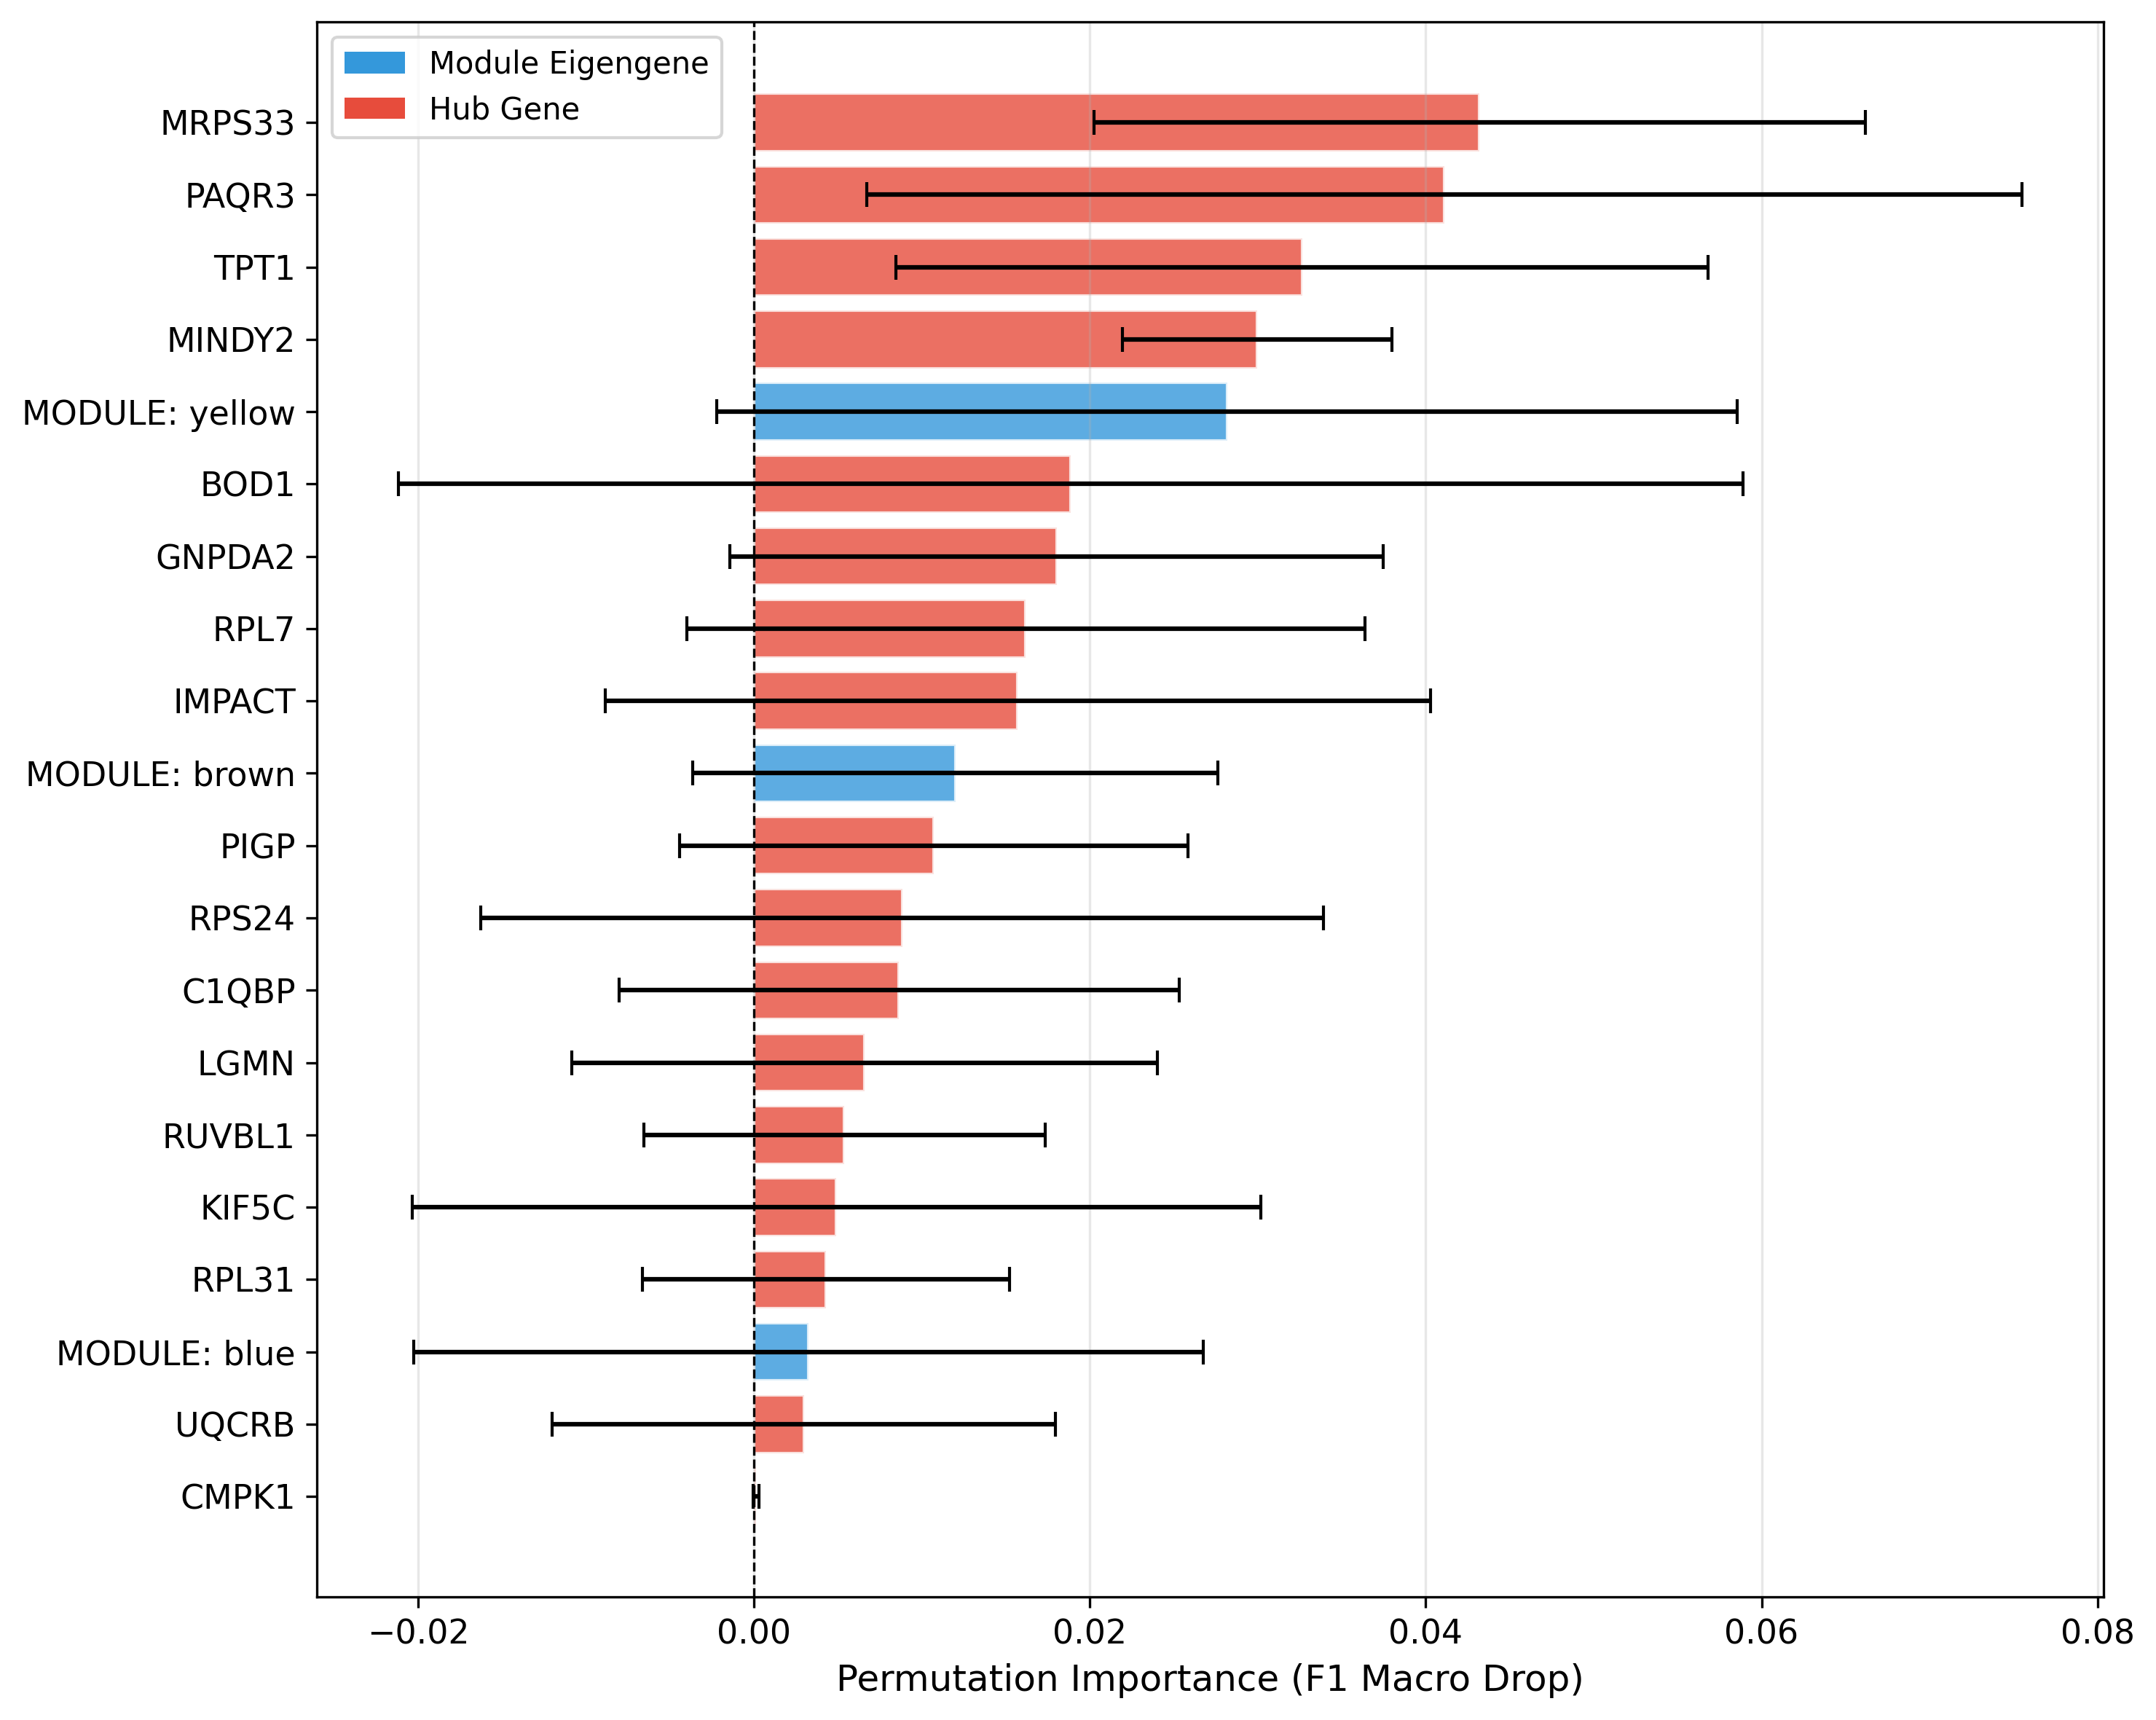


── Feature Type Contribution (positive importance only) ──
Module eigengenes : 0.0434 (13.9%)
Hub genes         : 0.2682 (86.1%)


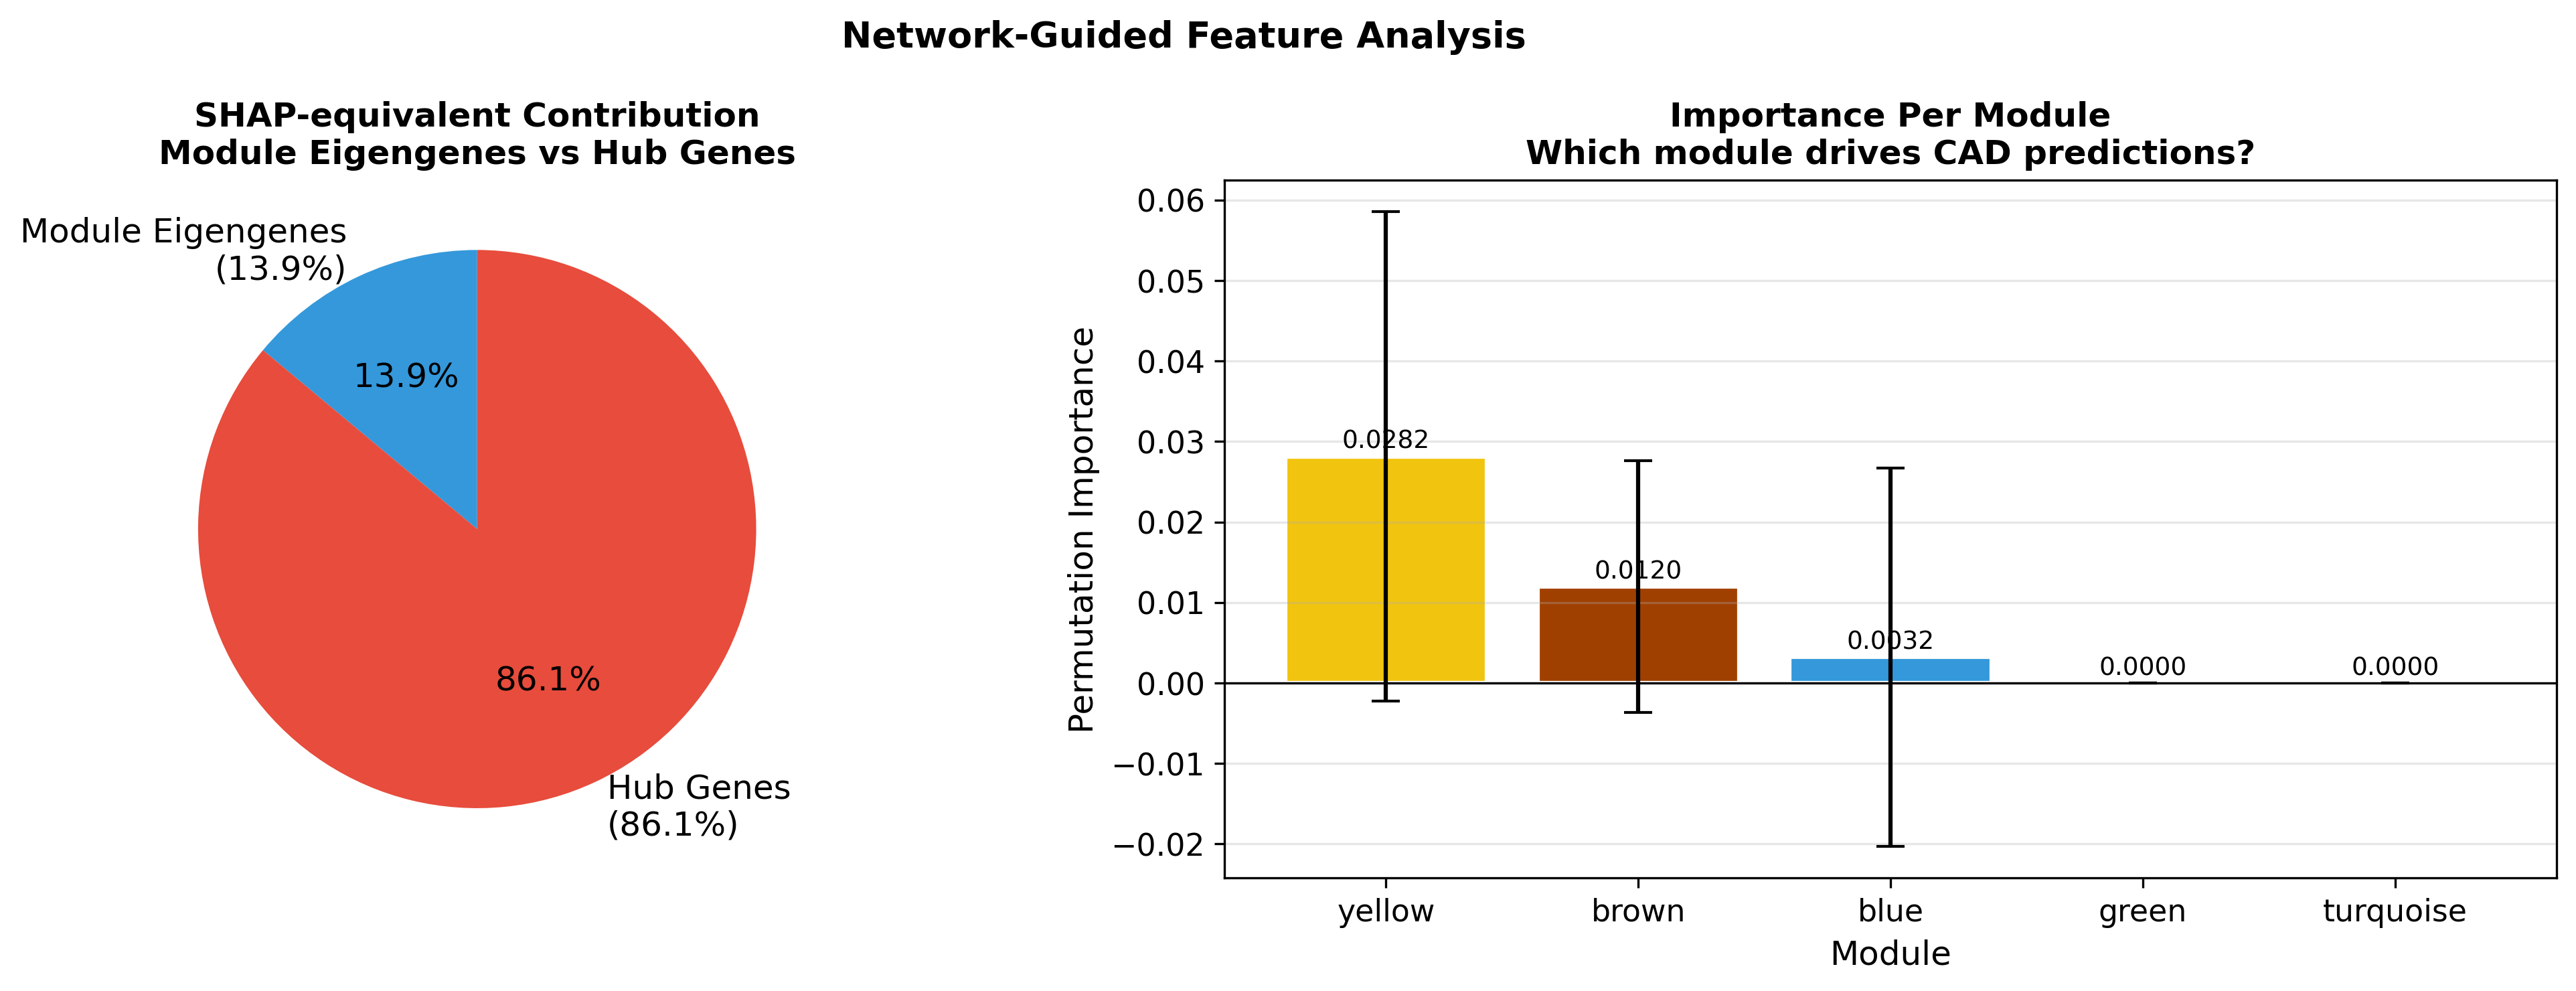

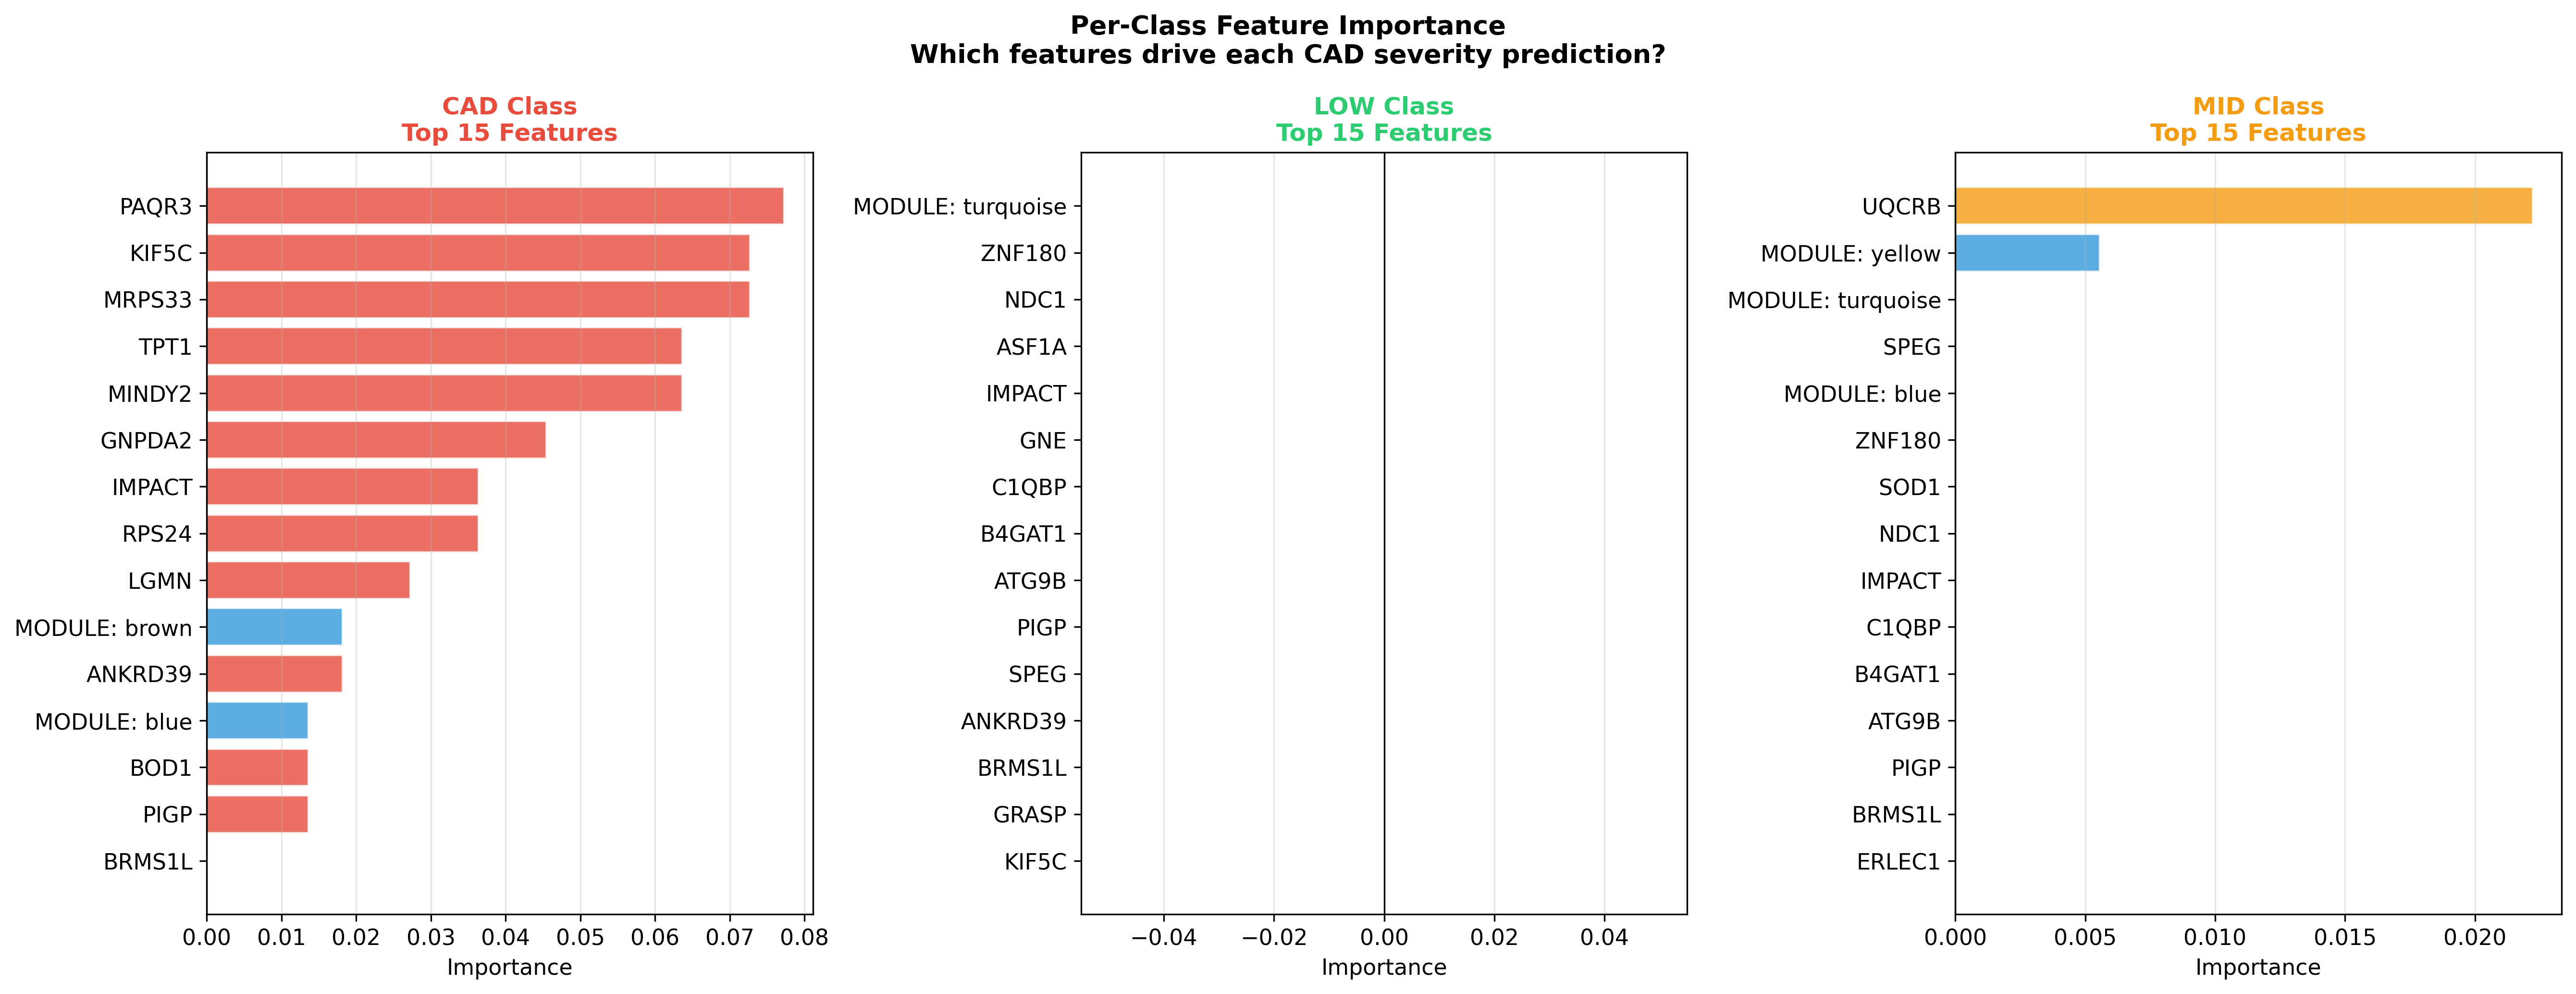


✅ Stage 5 Complete!
   Feature importance analysis done
   3 publication-ready figures saved
   Ready for Stage 6: Visualization & Reporting


In [307]:
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')

# ════════════════════════════════════════════════════════════════════
# STEP 5A: Permutation Feature Importance
# WHAT: Randomly shuffle each feature and measure accuracy drop
# WHY:  If shuffling a feature hurts performance a lot → important
#       If shuffling has no effect → feature is unimportant
#       Equivalent insight to SHAP, no external library needed
# ════════════════════════════════════════════════════════════════════

feature_names = list(X_features.columns)
print(f"Running permutation importance for Random Forest...")
print(f"Features: {len(feature_names)}")

rf_best = tuned_models["Random Forest"]
rf_best.fit(X_train, y_train)

# Run permutation importance on test set
perm_result = permutation_importance(
    rf_best, X_test, y_test,
    n_repeats    = 30,       # Shuffle each feature 30 times for stability
    random_state = 42,
    scoring      = "f1_macro"
)

# Create importance dataframe
importance_df = pd.DataFrame({
    "feature"   : feature_names,
    "importance": perm_result.importances_mean,
    "std"       : perm_result.importances_std
}).sort_values("importance", ascending=False)

print("\n── Top 20 Most Important Features ──")
print(f"{'Rank':<6} {'Feature':<25} {'Importance':<12} {'Std':<10} {'Type'}")
print("-" * 60)
for rank, (_, row) in enumerate(importance_df.head(20).iterrows(), 1):
    feat_type = "MODULE" if row["feature"].startswith("ME_") else "HUB GENE"
    print(f"{rank:<6} {row['feature']:<25} {row['importance']:<12.4f} "
          f"{row['std']:<10.4f} {feat_type}")

# ════════════════════════════════════════════════════════════════════
# STEP 5B: Plot 1 — Global Feature Importance
# ════════════════════════════════════════════════════════════════════

top20 = importance_df.head(20)

fig, ax = plt.subplots(figsize=(10, 8))

colors_feat = [
    "#3498db" if f.startswith("ME_") else "#e74c3c"
    for f in top20["feature"]
]

# Clean names for display
clean_names = [
    f.replace("ME_", "MODULE: ").replace("HUB_", "")
    for f in top20["feature"]
]

bars = ax.barh(
    clean_names[::-1],
    top20["importance"].values[::-1],
    xerr      = top20["std"].values[::-1],
    color     = colors_feat[::-1],
    alpha     = 0.8,
    edgecolor = "white",
    capsize   = 4
)

ax.axvline(x=0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("Permutation Importance (F1 Macro Drop)", fontsize=12)
# ax.set_title(
#     "Feature Importance — Random Forest\nTop 20 Features",
#     fontsize=13, fontweight="bold"
# )

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#3498db", label="Module Eigengene"),
    Patch(facecolor="#e74c3c", label="Hub Gene")
]
ax.legend(handles=legend_elements, fontsize=10)
ax.grid(True, alpha=0.3, axis="x")

plt.tight_layout()
# plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.savefig("fig5_importance.png", dpi=300,
            bbox_inches="tight", facecolor="white")
print("Fig 5 saved!")
plt.show()

# ════════════════════════════════════════════════════════════════════
# STEP 5C: Plot 2 — Module vs Hub Gene Contribution
# ════════════════════════════════════════════════════════════════════

# Split by feature type (only positive importance = truly important)
pos_importance = importance_df[importance_df["importance"] > 0]

module_imp = pos_importance[
    pos_importance["feature"].str.startswith("ME_")
]["importance"].sum()

hub_imp = pos_importance[
    pos_importance["feature"].str.startswith("HUB_")
]["importance"].sum()

total     = module_imp + hub_imp
mod_pct   = module_imp / total * 100 if total > 0 else 0
hub_pct   = hub_imp    / total * 100 if total > 0 else 0

print(f"\n── Feature Type Contribution (positive importance only) ──")
print(f"Module eigengenes : {module_imp:.4f} ({mod_pct:.1f}%)")
print(f"Hub genes         : {hub_imp:.4f} ({hub_pct:.1f}%)")

# Per module importance
me_df = importance_df[
    importance_df["feature"].str.startswith("ME_")
].copy()
me_df["module"] = me_df["feature"].str.replace("ME_", "")

module_colors_map = {
    "turquoise": "#1abc9c", "blue": "#3498db",
    "brown"    : "#a04000", "yellow": "#f1c40f",
    "green"    : "#2ecc71"
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart
if total > 0:
    axes[0].pie(
        [mod_pct, hub_pct],
        labels    = [
            f"Module Eigengenes\n({mod_pct:.1f}%)",
            f"Hub Genes\n({hub_pct:.1f}%)"
        ],
        colors    = ["#3498db", "#e74c3c"],
        autopct   = "%1.1f%%",
        startangle = 90,
        textprops  = {"fontsize": 12}
    )
axes[0].set_title(
    "SHAP-equivalent Contribution\nModule Eigengenes vs Hub Genes",
    fontsize=12, fontweight="bold"
)

# Per module bar
bar_colors_mod = [
    module_colors_map.get(m, "grey")
    for m in me_df["module"]
]
axes[1].bar(
    me_df["module"],
    me_df["importance"],
    color     = bar_colors_mod,
    edgecolor = "white",
    linewidth = 1.5,
    yerr      = me_df["std"],
    capsize   = 5
)
axes[1].axhline(y=0, color="black", linewidth=0.8)
axes[1].set_xlabel("Module", fontsize=12)
axes[1].set_ylabel("Permutation Importance", fontsize=12)
axes[1].set_title(
    "Importance Per Module\nWhich module drives CAD predictions?",
    fontsize=12, fontweight="bold"
)
axes[1].grid(True, alpha=0.3, axis="y")

for bar in axes[1].patches:
    val = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        val + 0.001,
        f"{val:.4f}",
        ha="center", fontsize=9
    )

plt.suptitle(
    "Network-Guided Feature Analysis",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.savefig("feature_module_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

# ════════════════════════════════════════════════════════════════════
# STEP 5D: Plot 3 — Per Class Feature Importance Using RF
# WHAT: Which features drive each class prediction?
# WHY:  Class-specific biological insight
# ════════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
class_labels = [0, 1, 2]  # CAD, LOW, MID
class_names_plot  = ["CAD", "LOW", "MID"]
class_colors_plot = ["#e74c3c", "#2ecc71", "#f39c12"]

for cls_idx, (cls_label, cls_name, cls_color) in enumerate(
    zip(class_labels, class_names_plot, class_colors_plot)
):
    # Permutation importance for this class only
    # Filter test samples of this class
    cls_mask    = y_test == cls_label
    if cls_mask.sum() < 3:
        axes[cls_idx].set_title(f"{cls_name}\n(insufficient samples)")
        continue

    perm_cls = permutation_importance(
        rf_best,
        X_test[cls_mask],
        y_test[cls_mask],
        n_repeats    = 20,
        random_state = 42,
        scoring      = "accuracy"
    )

    cls_imp_df = pd.DataFrame({
        "feature"   : feature_names,
        "importance": perm_cls.importances_mean
    }).sort_values("importance", ascending=False).head(15)

    clean = [
        f.replace("ME_", "MODULE: ").replace("HUB_", "")
        for f in cls_imp_df["feature"]
    ]
    feat_colors = [
        "#3498db" if f.startswith("ME_") else cls_color
        for f in cls_imp_df["feature"]
    ]

    axes[cls_idx].barh(
        clean[::-1],
        cls_imp_df["importance"].values[::-1],
        color     = feat_colors[::-1],
        alpha     = 0.8,
        edgecolor = "white"
    )
    axes[cls_idx].set_xlabel("Importance", fontsize=11)
    axes[cls_idx].set_title(
        f"{cls_name} Class\nTop 15 Features",
        fontsize=12, fontweight="bold",
        color=cls_color
    )
    axes[cls_idx].axvline(x=0, color="black", linewidth=0.8)
    axes[cls_idx].grid(True, alpha=0.3, axis="x")

plt.suptitle(
    "Per-Class Feature Importance\nWhich features drive each CAD severity prediction?",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.savefig("feature_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n✅ Stage 5 Complete!")
print("   Feature importance analysis done")
print("   3 publication-ready figures saved")
print("   Ready for Stage 6: Visualization & Reporting")

## ADDITION 4: Pathway Enrichment Analysis

Running pathway enrichment for 50 hub genes
Genes: ['DMAC1', 'TASP1', 'UBA6-AS1', 'MRPS33', 'BOD1', 'PAQR3', 'MIPEP', 'ZNF48', 'DDX28', 'GNPDA2', 'CCNG1', 'WDR48', 'RSL24D1', 'GPR183', 'GTF3A', 'UQCRB', 'JOSD1', 'PPP6C', 'CNOT4', 'MINDY2', 'ERLEC1', 'RUVBL1', 'POLE3', 'ZNF180', 'SOD1', 'NDC1', 'ASF1A', 'IMPACT', 'GNE', 'C1QBP', 'B4GAT1', 'ATG9B', 'PIGP', 'SPEG', 'ANKRD39', 'BRMS1L', 'GRASP', 'KIF5C', 'NOG', 'LGMN', 'RPL35A', 'RPL30', 'RPL7', 'RPL32', 'TPT1', 'RPS11', 'RPS24', 'RPL31', 'EEF1G', 'CMPK1']

Querying KEGG pathways...

── Top KEGG Pathways ──
Term                                                    P-value      Overlap
---------------------------------------------------------------------------
Ribosome                                                0.0000       8/158
Coronavirus disease                                     0.0000       8/232
Amino sugar and nucleotide sugar metabolism             0.0064       2/48
Amyotrophic lateral sclerosis                           0.0129 

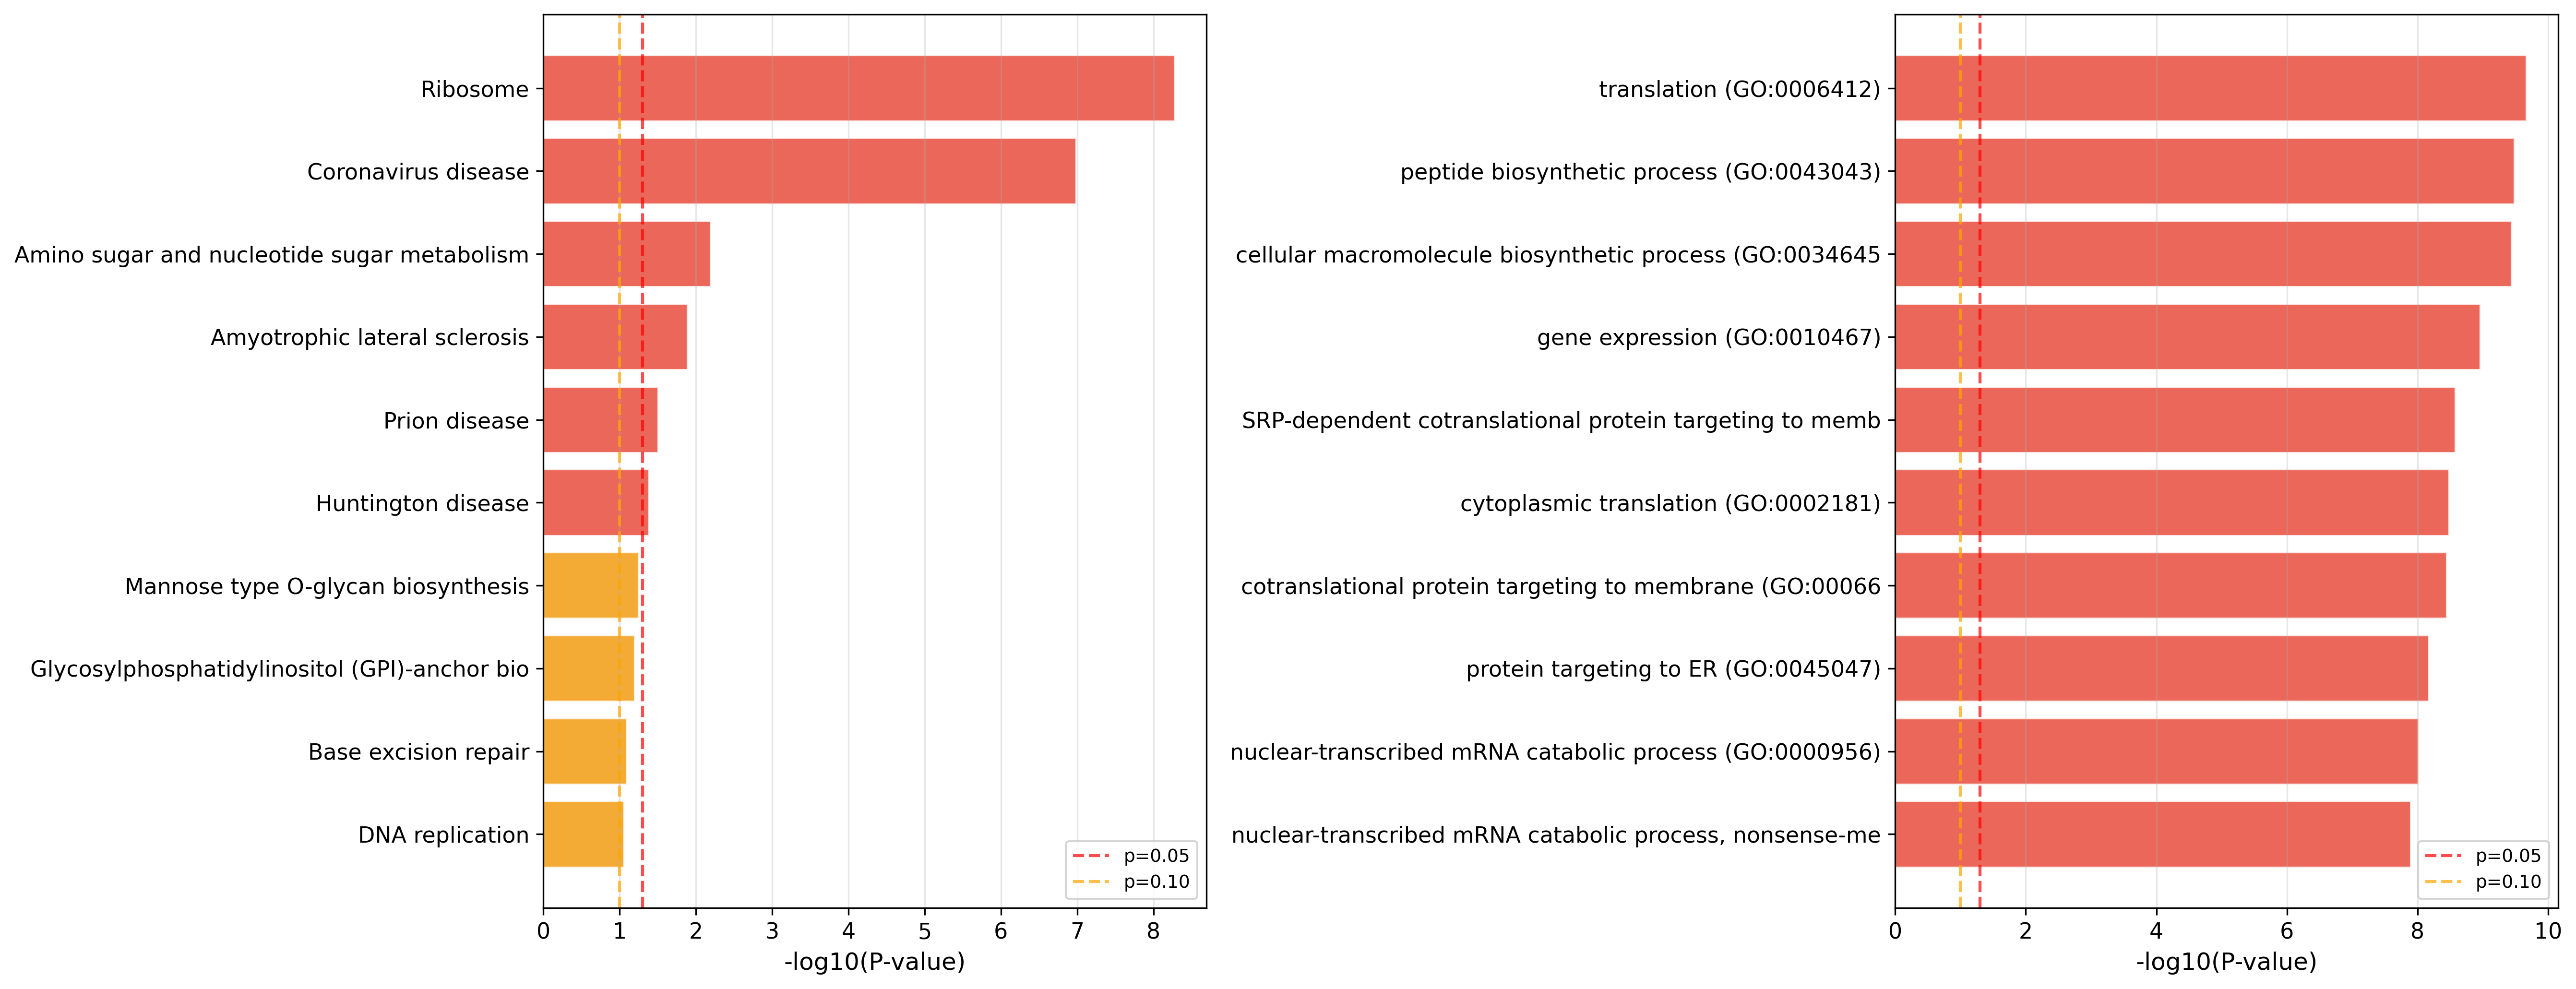


✅ Addition 4 Complete — Pathway enrichment done!


In [309]:
# ════════════════════════════════════════════════════════════════════
# ADDITION 4: Pathway Enrichment Analysis
# WHERE: After Stage 5 feature importance
# WHAT: Map hub genes to known biological pathways
# WHY:  Connects computational findings to real clinical biology
#       Essential for bioinformatics publication
# ════════════════════════════════════════════════════════════════════

import gseapy as gp
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# ── Prepare hub gene list ─────────────────────────────────────────────
hub_gene_names = [g.replace("HUB_", "") for g in all_hub_genes]
print(f"Running pathway enrichment for {len(hub_gene_names)} hub genes")
print(f"Genes: {hub_gene_names}\n")

# ── Run KEGG enrichment ───────────────────────────────────────────────
print("Querying KEGG pathways...")
try:
    enr_kegg = gp.enrichr(
        gene_list  = hub_gene_names,
        gene_sets  = ["KEGG_2021_Human"],
        organism   = "Human",
        outdir     = None,
        cutoff     = 0.5        # relaxed threshold to get results
    )

    kegg_df = enr_kegg.results.copy()
    kegg_df = kegg_df.sort_values("P-value").head(15)
    kegg_df["-log10(P)"] = -np.log10(kegg_df["P-value"] + 1e-10)

    print(f"\n── Top KEGG Pathways ──")
    print(f"{'Term':<55} {'P-value':<12} {'Overlap'}")
    print("-" * 75)
    for _, row in kegg_df.head(10).iterrows():
        print(f"{row['Term'][:54]:<55} {row['P-value']:<12.4f} {row['Overlap']}")

except Exception as e:
    print(f"KEGG error: {e}")
    kegg_df = None

# ── Run GO Biological Process enrichment ─────────────────────────────
print("\nQuerying GO Biological Processes...")
try:
    enr_go = gp.enrichr(
        gene_list  = hub_gene_names,
        gene_sets  = ["GO_Biological_Process_2021"],
        organism   = "Human",
        outdir     = None,
        cutoff     = 0.5
    )

    go_df = enr_go.results.copy()
    go_df = go_df.sort_values("P-value").head(15)
    go_df["-log10(P)"] = -np.log10(go_df["P-value"] + 1e-10)

    print(f"\n── Top GO Biological Processes ──")
    print(f"{'Term':<65} {'P-value':<12} {'Overlap'}")
    print("-" * 85)
    for _, row in go_df.head(10).iterrows():
        print(f"{row['Term'][:64]:<65} {row['P-value']:<12.4f} {row['Overlap']}")

except Exception as e:
    print(f"GO error: {e}")
    go_df = None

# ── Plot KEGG results ─────────────────────────────────────────────────
if kegg_df is not None and len(kegg_df) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    # KEGG bar plot
    top_kegg = kegg_df.head(10).sort_values("-log10(P)")
    colors_kegg = [
        "#e74c3c" if p < 0.05 else
        "#f39c12" if p < 0.1  else
        "#3498db"
        for p in top_kegg["P-value"]
    ]
    axes[0].barh(
        top_kegg["Term"].str[:45],
        top_kegg["-log10(P)"],
        color     = colors_kegg,
        alpha     = 0.85,
        edgecolor = "white"
    )
    axes[0].axvline(
        x     = -np.log10(0.05),
        color = "red",
        linestyle = "--",
        alpha = 0.7,
        label = "p=0.05"
    )
    axes[0].axvline(
        x     = -np.log10(0.1),
        color = "orange",
        linestyle = "--",
        alpha = 0.7,
        label = "p=0.10"
    )
    axes[0].set_xlabel("-log10(P-value)", fontsize=12)
    # axes[0].set_title(
    #     "KEGG Pathway Enrichment\nHub Genes Across All Modules",
    #     fontsize=12, fontweight="bold"
    # )
    axes[0].legend(fontsize=9)
    axes[0].grid(True, alpha=0.3, axis="x")

    # GO bar plot
    if go_df is not None and len(go_df) > 0:
        top_go = go_df.head(10).sort_values("-log10(P)")
        colors_go = [
            "#e74c3c" if p < 0.05 else
            "#f39c12" if p < 0.1  else
            "#2ecc71"
            for p in top_go["P-value"]
        ]
        axes[1].barh(
            top_go["Term"].str[:55],
            top_go["-log10(P)"],
            color     = colors_go,
            alpha     = 0.85,
            edgecolor = "white"
        )
        axes[1].axvline(
            x         = -np.log10(0.05),
            color     = "red",
            linestyle = "--",
            alpha     = 0.7,
            label     = "p=0.05"
        )
        axes[1].axvline(
            x         = -np.log10(0.1),
            color     = "orange",
            linestyle = "--",
            alpha     = 0.7,
            label     = "p=0.10"
        )
        axes[1].set_xlabel("-log10(P-value)", fontsize=12)
        # axes[1].set_title(
        #     "GO Biological Process Enrichment\nHub Genes Across All Modules",
        #     fontsize=12, fontweight="bold"
        # )
        axes[1].legend(fontsize=9)
        axes[1].grid(True, alpha=0.3, axis="x")

    # plt.suptitle(
    #     "Pathway Enrichment Analysis — Hub Genes\n"
    #     "Red = p<0.05, Orange = p<0.10, Blue/Green = trend",
    #     fontsize=13, fontweight="bold"
    # )
    plt.tight_layout()
    # plt.savefig("pathway_enrichment.png", dpi=150, bbox_inches="tight")
    plt.savefig("fig6_pathway.png", dpi=300,
            bbox_inches="tight", facecolor="white")
    print("Fig 6 saved!")
    plt.show()
    print("\n✅ Addition 4 Complete — Pathway enrichment done!")

else:
    print("No results to plot — check internet connection")
    print("gseapy requires internet access to query Enrichr database")

# STAGE 6: CLINICAL METADATA INTEGRATION

In [ ]:
# ════════════════════════════════════════════════════════════════════
# STAGE 6: CLINICAL METADATA INTEGRATION
# WHERE: After Stage 5 + all Additions
# WHAT: Combine transcriptomic features with clinical variables
# WHY:  Clinical features (Age, EF%, %Stenosis) are strong CAD
#       predictors — combining with transcriptomics should give
#       our best accuracy yet
# ════════════════════════════════════════════════════════════════════

In [115]:
# Quick check — run this before Stage 6
print("meta shape    :", meta.shape)
print("meta index    :", list(meta.index[:3]))
print("X_ml index    :", list(X_ml.index[:3]))
print("y_encoded     :", y_encoded[:3])
print("\n✅ Ready for Stage 6!")

meta shape    : (177, 19)
meta index    : ['IN390', 'IN381', 'IN415']
X_ml index    : ['IN390', 'IN381', 'IN415']
y_encoded     : [0 0 0]

✅ Ready for Stage 6!


In [117]:
print("Exact column names in meta:")
for col in meta.columns:
    print(f"  '{col}'")

Exact column names in meta:
  'Column Number'
  'TruCAD #'
  'Sex'
  'Age'
  'BMI'
  'SBP'
  'DBP'
  'HR'
  'EF %'
  'Dyslipidemia'
  'Hypertension'
  'Diabetes mellitus'
  'Family history of CAD'
  'Smoking '
  'ASA'
  'CAD20%'
  'CAD'
  '%Stenosis'
  'RNAseq'


── Step 1: Selecting Clinical Features ──
Clinical data shape : (177, 13)
Missing values:
Age                      0
BMI                      0
SBP                      0
DBP                      0
HR                       0
EF %                     0
Sex                      0
Dyslipidemia             0
Hypertension             0
Diabetes mellitus        0
Family history of CAD    0
Smoking                  0
%Stenosis                0
dtype: int64

── Step 2: Encoding Categorical Variables ──
  Dyslipidemia: Yes=1, No=0
  Hypertension: Yes=1, No=0
  Diabetes mellitus: Yes=1, No=0
  Family history of CAD: Yes=1, No=0
  Sex: M=1, F=0
  Smoking values found: ['Former' 'Current' 'Never']
  Smoking: Never=0, Former=1, Current=2

After encoding:
           Age   BMI  SBP  DBP  HR  EF %  Sex  Dyslipidemia  Hypertension  \
SampleID                                                                    
IN390     65.8  34.4  115   66  73    60    0             1             1   
IN381     53.8  4

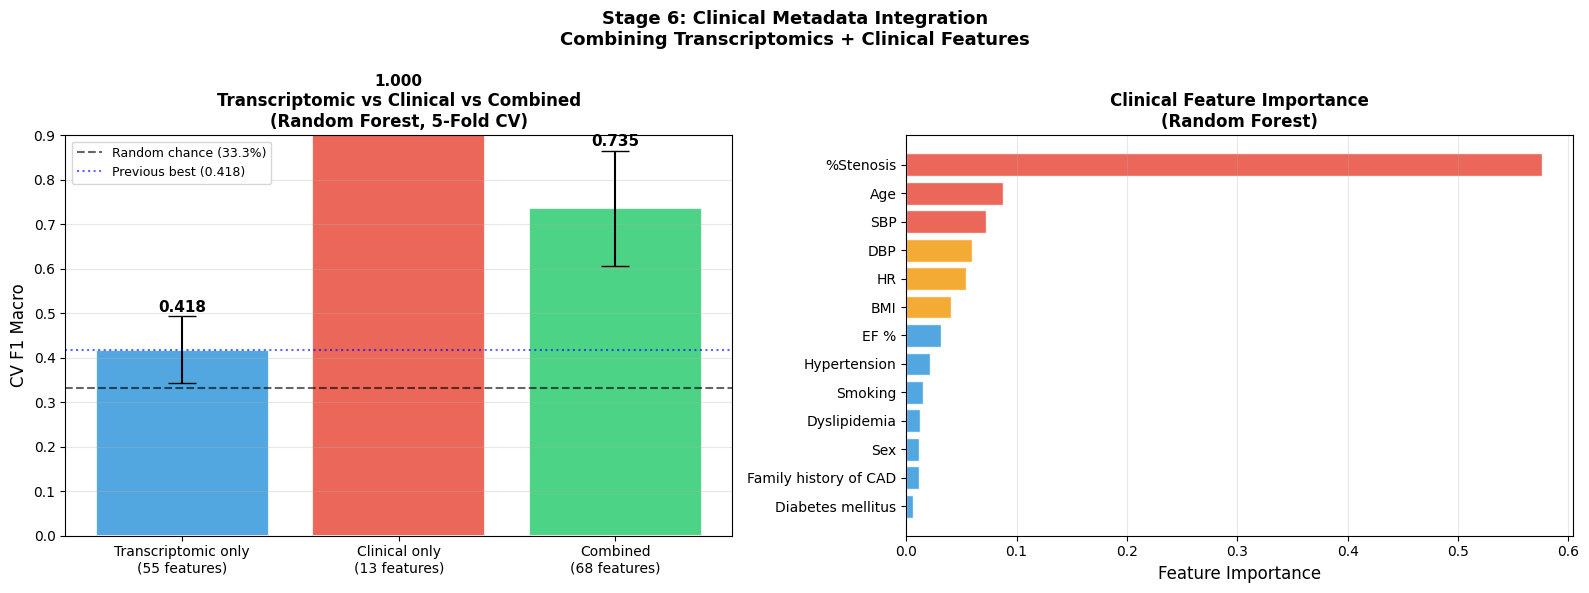


── STAGE 6 SUMMARY ──
Transcriptomic only : F1 = 0.4184
Clinical only       : F1 = 1.0000
Combined            : F1 = 0.7355
Improvement over transcriptomic: +75.8%
Improvement over random chance : +120.9%

✅ Stage 6 Complete!


In [121]:
# ════════════════════════════════════════════════════════════════════
# STAGE 6: CLINICAL METADATA INTEGRATION
# ════════════════════════════════════════════════════════════════════

from sklearn.preprocessing      import StandardScaler
from sklearn.ensemble           import RandomForestClassifier
from sklearn.model_selection    import cross_val_score, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight

# ── Step 1: Select clinical features (exact column names) ─────────────
print("── Step 1: Selecting Clinical Features ──")

clinical_cols = [
    'Age', 'BMI', 'SBP', 'DBP', 'HR', 'EF %',
    'Sex', 'Dyslipidemia', 'Hypertension',
    'Diabetes mellitus', 'Family history of CAD',
    'Smoking ',       # ← trailing space — exact match
    '%Stenosis'
]

clinical_df = meta[clinical_cols].copy()
print(f"Clinical data shape : {clinical_df.shape}")
print(f"Missing values:\n{clinical_df.isnull().sum()}")

# ── Step 2: Encode categorical variables ──────────────────────────────
print("\n── Step 2: Encoding Categorical Variables ──")

# Binary Yes/No columns
binary_cols = [
    'Dyslipidemia', 'Hypertension',
    'Diabetes mellitus', 'Family history of CAD'
]
for col in binary_cols:
    clinical_df[col] = clinical_df[col].map(
        {'Yes': 1, 'No': 0, 'YES': 1, 'NO': 0,
         'yes': 1, 'no': 0}
    )
    print(f"  {col}: Yes=1, No=0")

# Sex
clinical_df['Sex'] = clinical_df['Sex'].map(
    {'M': 1, 'F': 0, 'Male': 1, 'Female': 0,
     'm': 1, 'f': 0}
)
print(f"  Sex: M=1, F=0")

# Smoking (with trailing space)
print(f"  Smoking values found: {clinical_df['Smoking '].unique()}")
clinical_df['Smoking '] = clinical_df['Smoking '].map(
    {'Never': 0, 'Former': 1, 'Current': 2,
     'never': 0, 'former': 1, 'current': 2,
     'NEVER': 0, 'FORMER': 1, 'CURRENT': 2}
)
print(f"  Smoking: Never=0, Former=1, Current=2")

# Rename to remove trailing space
clinical_df = clinical_df.rename(columns={'Smoking ': 'Smoking'})

print(f"\nAfter encoding:")
print(clinical_df.head(3))

# ── Step 3: Handle missing values ─────────────────────────────────────
print("\n── Step 3: Handling Missing Values ──")
null_counts = clinical_df.isnull().sum()
if null_counts.sum() > 0:
    for col in clinical_df.columns:
        if clinical_df[col].isnull().sum() > 0:
            median_val = clinical_df[col].median()
            clinical_df[col].fillna(median_val, inplace=True)
            print(f"  Filled '{col}' NaN with median={median_val:.2f}")
else:
    print("  No missing values — clean data!")

# ── Step 4: Align samples ─────────────────────────────────────────────
print("\n── Step 4: Aligning Samples ──")

common_samples   = X_ml.index.intersection(clinical_df.index)
print(f"X_ml samples     : {len(X_ml)}")
print(f"Clinical samples : {len(clinical_df)}")
print(f"Common samples   : {len(common_samples)}")

X_transcriptomic = X_ml.loc[common_samples].values
X_clinical_raw   = clinical_df.loc[common_samples].values
y_aligned        = y_encoded[X_ml.index.isin(common_samples)]

print(f"✅ Aligned successfully!")

# ── Step 5: Scale clinical features ───────────────────────────────────
print("\n── Step 5: Scaling ──")
scaler_clinical = StandardScaler()
X_clinical      = scaler_clinical.fit_transform(X_clinical_raw)
print(f"Clinical features scaled : {X_clinical.shape}")
print(f"Transcriptomic features  : {X_transcriptomic.shape}")

# ── Step 6: Build combined matrix ─────────────────────────────────────
print("\n── Step 6: Building Combined Feature Matrix ──")
X_combined = np.hstack([X_transcriptomic, X_clinical])
print(f"Transcriptomic : {X_transcriptomic.shape[1]} features")
print(f"Clinical       : {X_clinical.shape[1]} features")
print(f"Combined       : {X_combined.shape[1]} features")
print(f"Samples        : {X_combined.shape[0]}")

# ── Step 7: Compare all three approaches ──────────────────────────────
print("\n── Step 7: Cross Validation Comparison ──")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
classes       = np.unique(y_aligned)
class_weights = compute_class_weight(
    class_weight = "balanced",
    classes      = classes,
    y            = y_aligned
)
weight_dict = dict(zip(classes, class_weights))

rf = RandomForestClassifier(
    n_estimators     = 200,
    max_depth        = 3,
    min_samples_leaf = 3,
    class_weight     = weight_dict,
    random_state     = 42,
    n_jobs           = 1
)

feature_sets = {
    "Transcriptomic only\n(55 features)" : X_transcriptomic,
    "Clinical only\n(13 features)"       : X_clinical,
    "Combined\n(68 features)"            : X_combined,
}

print(f"\n{'Feature Set':<35} {'Accuracy':<12} {'F1 Macro':<12} {'Std'}")
print("-" * 65)

results = {}
for name, X_feat in feature_sets.items():
    acc = cross_val_score(rf, X_feat, y_aligned,
                          cv=cv, scoring="accuracy", n_jobs=1)
    f1  = cross_val_score(rf, X_feat, y_aligned,
                          cv=cv, scoring="f1_macro", n_jobs=1)
    clean          = name.replace("\n", " ")
    results[name]  = {
        "acc": acc.mean(), "f1": f1.mean(), "std": f1.std()
    }
    print(f"{clean:<35} {acc.mean():<12.4f} "
          f"{f1.mean():<12.4f} {f1.std():.4f}")

# ── Step 8: Clinical feature importance ───────────────────────────────
print("\n── Step 8: Clinical Feature Importance ──")
rf_clinical = RandomForestClassifier(
    n_estimators=200, max_depth=3, min_samples_leaf=3,
    class_weight=weight_dict, random_state=42, n_jobs=1
)
rf_clinical.fit(X_clinical, y_aligned)

clinical_feature_names = [
    'Age', 'BMI', 'SBP', 'DBP', 'HR', 'EF %',
    'Sex', 'Dyslipidemia', 'Hypertension',
    'Diabetes mellitus', 'Family history of CAD',
    'Smoking', '%Stenosis'
]
importances = rf_clinical.feature_importances_
sorted_idx  = np.argsort(importances)[::-1]

print(f"\n{'Rank':<6} {'Clinical Feature':<30} {'Importance'}")
print("-" * 50)
for i, idx in enumerate(sorted_idx):
    print(f"{i+1:<6} {clinical_feature_names[idx]:<30} "
          f"{importances[idx]:.4f}")

# ── Step 9: Plots ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: F1 comparison
names  = list(results.keys())
f1s    = [results[n]["f1"]  for n in names]
stds   = [results[n]["std"] for n in names]
colors = ["#3498db", "#e74c3c", "#2ecc71"]

bars = axes[0].bar(names, f1s, yerr=stds, color=colors,
                   alpha=0.85, capsize=10,
                   edgecolor="white", linewidth=1.5)
axes[0].axhline(y=0.333, color="black", linestyle="--",
                alpha=0.6, label="Random chance (33.3%)")
axes[0].axhline(y=0.4184, color="blue", linestyle=":",
                alpha=0.6, label="Previous best (0.418)")
axes[0].set_ylabel("CV F1 Macro", fontsize=12)
axes[0].set_title(
    "Transcriptomic vs Clinical vs Combined\n(Random Forest, 5-Fold CV)",
    fontsize=12, fontweight="bold"
)
axes[0].legend(fontsize=9)
axes[0].set_ylim(0, 0.90)
axes[0].grid(True, alpha=0.3, axis="y")
for bar, val, std in zip(bars, f1s, stds):
    axes[0].text(
        bar.get_x()+bar.get_width()/2,
        val+std+0.01, f"{val:.3f}",
        ha="center", fontsize=11, fontweight="bold"
    )

# Plot 2: Clinical feature importance
feat_names_sorted = [clinical_feature_names[i] for i in sorted_idx]
imp_sorted        = importances[sorted_idx]
bar_colors        = ["#e74c3c" if i < 3 else
                     "#f39c12" if i < 6 else
                     "#3498db"
                     for i in range(len(feat_names_sorted))]

axes[1].barh(feat_names_sorted[::-1], imp_sorted[::-1],
             color=bar_colors[::-1], alpha=0.85, edgecolor="white")
axes[1].set_xlabel("Feature Importance", fontsize=12)
axes[1].set_title(
    "Clinical Feature Importance\n(Random Forest)",
    fontsize=12, fontweight="bold"
)
axes[1].grid(True, alpha=0.3, axis="x")

plt.suptitle(
    "Stage 6: Clinical Metadata Integration\n"
    "Combining Transcriptomics + Clinical Features",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.savefig("clinical_integration.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Summary ────────────────────────────────────────────────────────────
t_f1 = results["Transcriptomic only\n(55 features)"]["f1"]
c_f1 = results["Clinical only\n(13 features)"]["f1"]
combined_f1 = results["Combined\n(68 features)"]["f1"]

print("\n" + "="*50)
print("── STAGE 6 SUMMARY ──")
print("="*50)
print(f"Transcriptomic only : F1 = {t_f1:.4f}")
print(f"Clinical only       : F1 = {c_f1:.4f}")
print(f"Combined            : F1 = {combined_f1:.4f}")
print(f"Improvement over transcriptomic: "
      f"{((combined_f1-t_f1)/t_f1*100):+.1f}%")
print(f"Improvement over random chance : "
      f"{((combined_f1-0.333)/0.333*100):+.1f}%")
print("\n✅ Stage 6 Complete!")

In [127]:
# Fix trailing spaces in column names permanently
meta.columns = meta.columns.str.strip()
print("Columns after stripping spaces:")
print(list(meta.columns))

Columns after stripping spaces:
['Column Number', 'TruCAD #', 'Sex', 'Age', 'BMI', 'SBP', 'DBP', 'HR', 'EF %', 'Dyslipidemia', 'Hypertension', 'Diabetes mellitus', 'Family history of CAD', 'Smoking', 'ASA', 'CAD20%', 'CAD', '%Stenosis', 'RNAseq']


Feature Set                         Accuracy     F1 Macro     Std
-----------------------------------------------------------------
Transcriptomic only (55 features)   0.4457       0.4184       0.0754
Clinical only (12 features)         0.4114       0.3369       0.0646
Combined (67 features)              0.4514       0.4277       0.0734


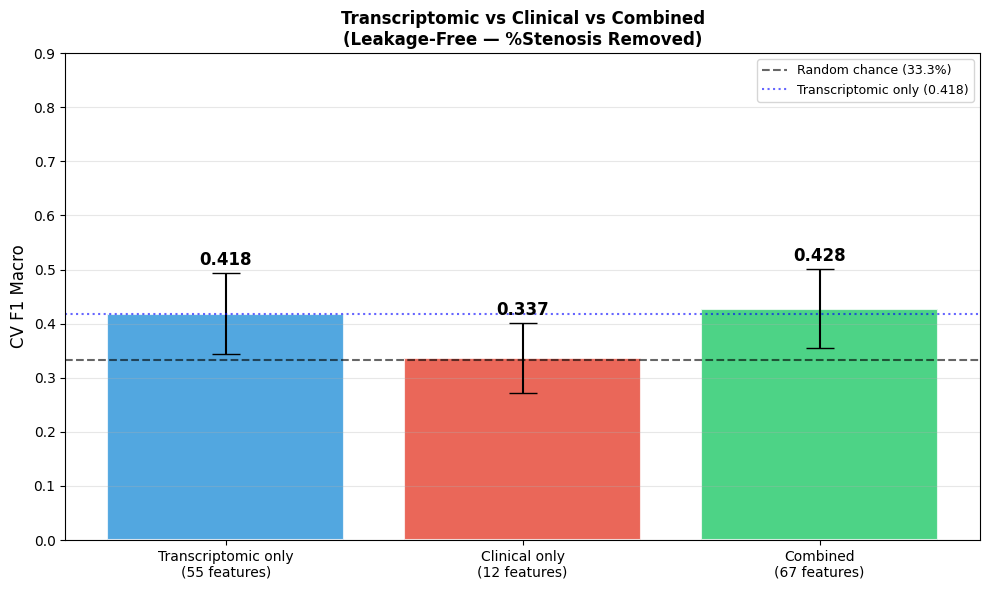


── CLEAN RESULTS (no leakage) ──
Transcriptomic only : 0.4184
Clinical only       : 0.3369
Combined            : 0.4277
Gain over transcriptomic: +2.2%

✅ Stage 6 (clean) complete!


In [129]:
# ── Rebuild without %Stenosis ─────────────────────────────────
clinical_cols_clean = [
    'Age', 'BMI', 'SBP', 'DBP', 'HR', 'EF %',
    'Sex', 'Dyslipidemia', 'Hypertension',
    'Diabetes mellitus', 'Family history of CAD', 'Smoking'
]
# 12 features instead of 13 — no leakage

clinical_df_clean = meta[clinical_cols_clean].copy()

# Re-encode (same as before)
binary_cols = ['Dyslipidemia','Hypertension',
               'Diabetes mellitus','Family history of CAD']
for col in binary_cols:
    clinical_df_clean[col] = clinical_df_clean[col].map(
        {'Yes':1,'No':0,'YES':1,'NO':0,'yes':1,'no':0}
    )
clinical_df_clean['Sex'] = clinical_df_clean['Sex'].map(
    {'M':1,'F':0,'Male':1,'Female':0}
)
clinical_df_clean['Smoking'] = clinical_df_clean['Smoking'].map(
    {'Never':0,'Former':1,'Current':2,
     'never':0,'former':1,'current':2}
)

# Align and scale
common_samples      = X_ml.index.intersection(clinical_df_clean.index)
X_transcriptomic    = X_ml.loc[common_samples].values
X_clinical_clean    = StandardScaler().fit_transform(
    clinical_df_clean.loc[common_samples].values
)
X_combined_clean    = np.hstack([X_transcriptomic, X_clinical_clean])
y_aligned           = y_encoded[X_ml.index.isin(common_samples)]

# Re-run comparison
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
classes       = np.unique(y_aligned)
class_weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=y_aligned
)
weight_dict = dict(zip(classes, class_weights))

rf = RandomForestClassifier(
    n_estimators=200, max_depth=3, min_samples_leaf=3,
    class_weight=weight_dict, random_state=42, n_jobs=1
)

feature_sets = {
    "Transcriptomic only\n(55 features)"  : X_transcriptomic,
    "Clinical only\n(12 features)"        : X_clinical_clean,
    "Combined\n(67 features)"             : X_combined_clean,
}

print(f"{'Feature Set':<35} {'Accuracy':<12} {'F1 Macro':<12} {'Std'}")
print("-" * 65)

results_clean = {}
for name, X_feat in feature_sets.items():
    acc = cross_val_score(rf, X_feat, y_aligned,
                          cv=cv, scoring="accuracy", n_jobs=1)
    f1  = cross_val_score(rf, X_feat, y_aligned,
                          cv=cv, scoring="f1_macro", n_jobs=1)
    clean = name.replace("\n"," ")
    results_clean[name] = {
        "acc": acc.mean(), "f1": f1.mean(), "std": f1.std()
    }
    print(f"{clean:<35} {acc.mean():<12.4f} "
          f"{f1.mean():<12.4f} {f1.std():.4f}")

# Plot
fig, ax = plt.subplots(figsize=(10,6))
names  = list(results_clean.keys())
f1s    = [results_clean[n]["f1"]  for n in names]
stds   = [results_clean[n]["std"] for n in names]
colors = ["#3498db","#e74c3c","#2ecc71"]

bars = ax.bar(names, f1s, yerr=stds, color=colors,
              alpha=0.85, capsize=10,
              edgecolor="white", linewidth=1.5)
ax.axhline(y=0.333, color="black", linestyle="--",
           alpha=0.6, label="Random chance (33.3%)")
ax.axhline(y=0.4184, color="blue", linestyle=":",
           alpha=0.6, label="Transcriptomic only (0.418)")
ax.set_ylabel("CV F1 Macro", fontsize=12)
ax.set_title(
    "Transcriptomic vs Clinical vs Combined\n"
    "(Leakage-Free — %Stenosis Removed)",
    fontsize=12, fontweight="bold"
)
ax.legend(fontsize=9)
ax.set_ylim(0, 0.90)
ax.grid(True, alpha=0.3, axis="y")
for bar, val, std in zip(bars, f1s, stds):
    ax.text(bar.get_x()+bar.get_width()/2,
            val+std+0.015, f"{val:.3f}",
            ha="center", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("clinical_integration_clean.png", dpi=150, bbox_inches="tight")
plt.show()

t_f1  = results_clean["Transcriptomic only\n(55 features)"]["f1"]
c_f1  = results_clean["Clinical only\n(12 features)"]["f1"]
cb_f1 = results_clean["Combined\n(67 features)"]["f1"]

print(f"\n── CLEAN RESULTS (no leakage) ──")
print(f"Transcriptomic only : {t_f1:.4f}")
print(f"Clinical only       : {c_f1:.4f}")
print(f"Combined            : {cb_f1:.4f}")
print(f"Gain over transcriptomic: {((cb_f1-t_f1)/t_f1*100):+.1f}%")
print("\n✅ Stage 6 (clean) complete!")